In [7]:
import plotly as pl
import matplotlib.pyplot as plt
import seaborn as s
import matplotlib as mp
import numpy as np
import pandas as pd
import os
import pathlib

notebook_dir = pathlib.Path().resolve()
print(notebook_dir)

/Users/teoboy/101_python/intro_to_statistics/pew-global-attitudes-2024-analysis


In [11]:
pew = pd.read_csv("pew_dataset.csv", dtype=str) 

In [12]:
# convert relevant columns to numeric

pew['weight'] = pd.to_numeric(pew['weight'], errors='coerce')
pew['age'] = pd.to_numeric(pew['age'], errors='coerce')  
pew['id'] = pd.to_numeric(pew['id'], errors='coerce')  
pew['country'] = pd.to_numeric(pew['country'], errors='coerce') 

# create a python dictionary, generating an additional 'country' column from country-codes

country_code_map = {
    2: "Canada",
    3: "France",
    4: "Germany",
    5: "Greece",
    6: "Hungary",
    7: "Italy",
    8: "Netherlands",
    9: "Poland",
    10: "Spain",
    11: "Sweden",
    12: "UK",
    13: "Australia",
    14: "Bangladesh",
    15: "India",
    16: "Indonesia",
    17: "Japan",
    18: "Malaysia",
    19: "Philippines",
    20: "Singapore",
    21: "South Korea",
    22: "Sri Lanka",
    23: "Thailand",
    24: "Israel",
    25: "Tunisia",
    26: "Turkey",
    27: "Ghana",
    28: "Kenya",
    29: "Nigeria",
    30: "South Africa",
    31: "Argentina",
    32: "Brazil",
    33: "Chile",
    34: "Colombia",
    35: "Mexico",
    36: "Peru"
}

pew['country_name'] = pew['country'].map(country_code_map)

# 1. Literature Review

China is often referenced, especially across Europe and the US, when talking about censorship and freedom, in addition to winning the AI arms race. But is there a correlation between global attitudes and opinions towards China, and views of internet freedom, press freedom and tech governance?


## Research Question: How do perceptions of China correlate with views on internet freedom, press freedom, and technology governance?

### Potential Analysis Directions:

1. **China Favorability vs. Internet Freedom Views**: Do people with favorable views of China also have different perspectives on internet freedom/censorship?
   
2. **Technocracy and China**: Does support for technocracy (rule by technology experts) correlate with views on China, especially given China's technological development model?

3. **Misinformation Concerns**: How do concerns about misinformation (which increasingly involves AI-generated content) relate to perceptions of China and internet freedom?

4. **Country-Level Patterns**: Are there regional patterns where countries with more restrictive internet policies have different views on China?

# 2. Methodology

## 2.2 Dataset

**Key Variables:

**China Perceptions**:
- `fav_china` (ALL): Please tell me if you have a very favorable (1), somewhat favorable (2), somewhat unfavorable (3), or very unfavorable (4) opinion of china?
- `fav_us` (ALL): Please tell me if you have a very favorable (1), somewhat favorable (2), somewhat unfavorable (3), or very unfavorable (4) opinion of china?
- `uspres_china` (ALL): thinking about U.S. president Joe Biden, do you strongly approve (1), somewhat approve (2), somewhat disapprove (3) or strongly disapprove (4) of the way he is dealing with China?
- `china_influ_econ` (ALL): How much influence do you think China is having on economic conditions in your country — a great deal of influence (1), a fair amount of influence (2), not too much influence (3), or no influence at all (4)?
- `china_influ_econ2` (ALL): If answer to the previous question was (1), (2), or (3), is China having a positive (1) or negative (2) or neither/both (3) impacts on economic conditions in your country?

**Internet/Freedom Variables**:
- `free_press` (ALL): How free is the media to report the news? Completely (1), somewhat (2), not very (3), not at all (4)
- `free_say` (ALL): How free are people to say what they want? Completely (1), somewhat (2), not very (3), not at all (4)
- `free_internet` (ALL): How free are people to use the internet? Completely (1), somewhat (2), not very (3), not at all (4)
- `press_freedom` (ALL): How important is it that the media can report the news without state or government censorship? Very important (1), somewhat important (2), not too important (3) or not important at all (4)
- `free_speech` (ALL): How important is it that people can say what they want without state or government censorship? Very important (1), somewhat important (2), not too important (3) or not important at all (4)
- `internet_freedom` (ALL): How important is it that people can use the internet without state or government censorship? Very important (1), somewhat important (2), not too important (3) or not important at all (4)

**Governance & Technology**:
- `prob_misinformation` (ALL): How much of a problem do you think made-up news and information is in your country today - a very big problem (1), a moderately big problem (2), a small problem (3), or not a problem at all (4)?
- `inequality_automation` (ALL): How much, if at all, do you think robots and computers doing work previously done by humans leads to economic inequality in your country? A great deal (1), a fair amount (2), not too much (3), not at all (4)
- `satisfied_democracy` (ALL) - 'How satisfied are you with the way democracy is working in your country? very satisfied (1), somewhat satisfied (2), not too satisfied (3), or not at all satisfied (4)?' \
- `polsys_technocracy` (Limited to 20 countries, mainly global south): Do you think the idea of a technocracy would be good for governing your country? Very good (1), somewhat good (2), somewhat bad (3), very bad (4)

## 2.1 Research Question

**Main Question**: How do perceptions of China correlate with attitudes toward internet freedom, press freedom, and technology governance (technocracy)?

**Sub-questions**:
1. Do people with favorable views of China have different attitudes toward internet censorship compared to those with unfavorable views?
2. Does support for technocracy (rule by technology experts) relate to perceptions of China?
3. How do concerns about misinformation relate to views on both China and internet freedom?

# Valuable Statistics

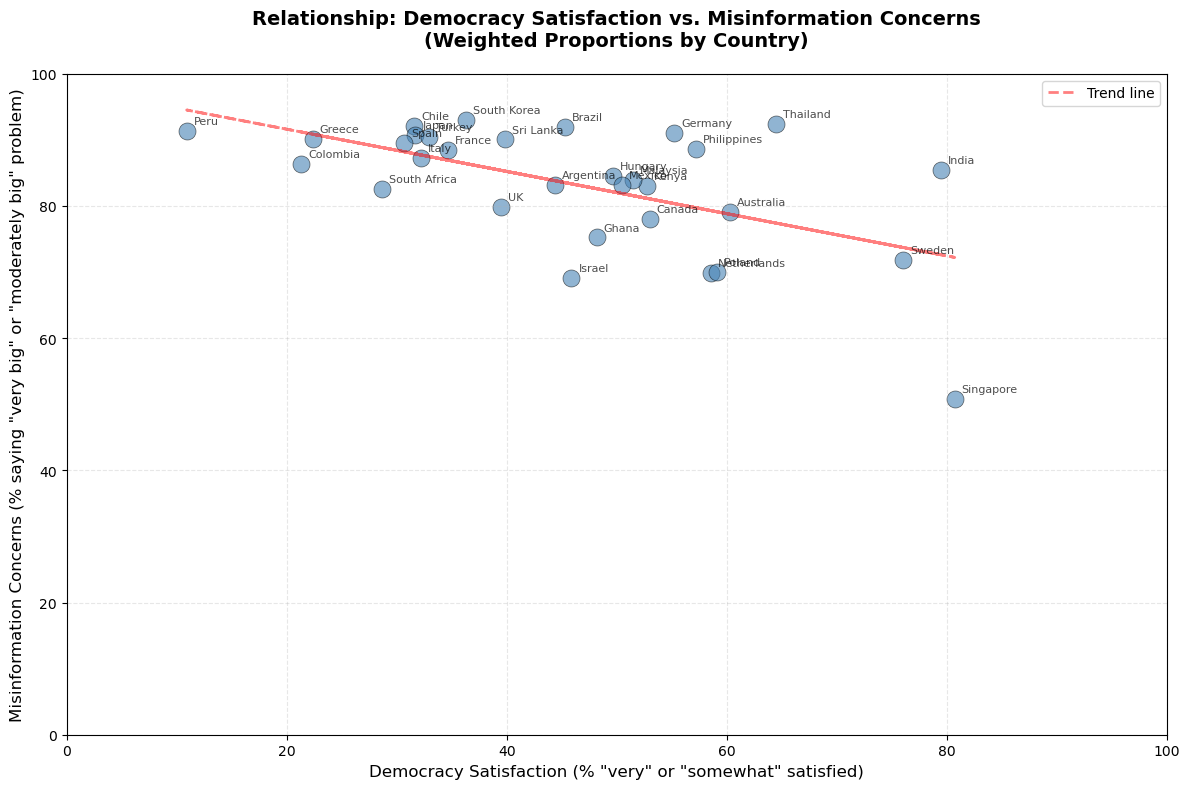

Summary Statistics (Weighted Proportions):

Number of countries: 31

Democracy Satisfaction (% satisfied):
  Mean: 46.0%
  Range: 10.9% - 80.7%

Misinformation Concerns (% saying it's a big problem):
  Mean: 83.3%
  Range: 50.8% - 93.0%

Spearman Correlation: -0.467 (p-value: 0.0080)
  Statistically significant correlation!
  Negative correlation: More satisfied with democracy → Less misinformation concerns
  This suggests that democratic satisfaction may reduce anxiety about misinformation


In [112]:
# Scatterplot: satisfied_democracy vs prob_misinformation
# Testing: Do countries with different levels of democracy satisfaction have different misinformation concerns?
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['satisfied_democracy'].isin(['1', '2', '3', '4']) & 
    pew['prob_misinformation'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'satisfied_democracy', 'prob_misinformation'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For satisfied_democracy: % who are satisfied (1 or 2: very/somewhat satisfied)
    satisfied_democracy_satisfied = country_data[country_data['satisfied_democracy'].isin(['1', '2'])]['weight'].sum()
    satisfied_democracy_pct = (satisfied_democracy_satisfied / total_weight) * 100
    
    # For prob_misinformation: % who say it's "a very big problem" or "a moderately big problem" (1 or 2)
    misinfo_concern = country_data[country_data['prob_misinformation'].isin(['1', '2'])]['weight'].sum()
    misinfo_concern_pct = (misinfo_concern / total_weight) * 100
    
    country_stats[country] = {
        'satisfied_democracy_pct': satisfied_democracy_pct,
        'misinfo_concern_pct': misinfo_concern_pct
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df['satisfied_democracy_pct'], 
           plot_df['misinfo_concern_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'satisfied_democracy_pct'], 
                 plot_df.loc[country, 'misinfo_concern_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line
from scipy import stats
z = np.polyfit(plot_df['satisfied_democracy_pct'], 
               plot_df['misinfo_concern_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['satisfied_democracy_pct'], 
        p(plot_df['satisfied_democracy_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('Democracy Satisfaction (% "very" or "somewhat" satisfied)', fontsize=12)
ax.set_ylabel('Misinformation Concerns (% saying "very big" or "moderately big" problem)', fontsize=12)
ax.set_title('Relationship: Democracy Satisfaction vs. Misinformation Concerns\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nDemocracy Satisfaction (% satisfied):")
print(f"  Mean: {plot_df['satisfied_democracy_pct'].mean():.1f}%")
print(f"  Range: {plot_df['satisfied_democracy_pct'].min():.1f}% - {plot_df['satisfied_democracy_pct'].max():.1f}%")
print(f"\nMisinformation Concerns (% saying it's a big problem):")
print(f"  Mean: {plot_df['misinfo_concern_pct'].mean():.1f}%")
print(f"  Range: {plot_df['misinfo_concern_pct'].min():.1f}% - {plot_df['misinfo_concern_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['satisfied_democracy_pct'], 
                                 plot_df['misinfo_concern_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
    if correlation < 0:
        print("  Negative correlation: More satisfied with democracy → Less misinformation concerns")
        print("  This suggests that democratic satisfaction may reduce anxiety about misinformation")
    else:
        print("  Positive correlation: More satisfied with democracy → More misinformation concerns")
        print("  This is counterintuitive - perhaps satisfied democracies are more aware of misinformation")
else:
    print("  No statistically significant correlation.")
    print("  This suggests democracy satisfaction and misinformation concerns operate independently")

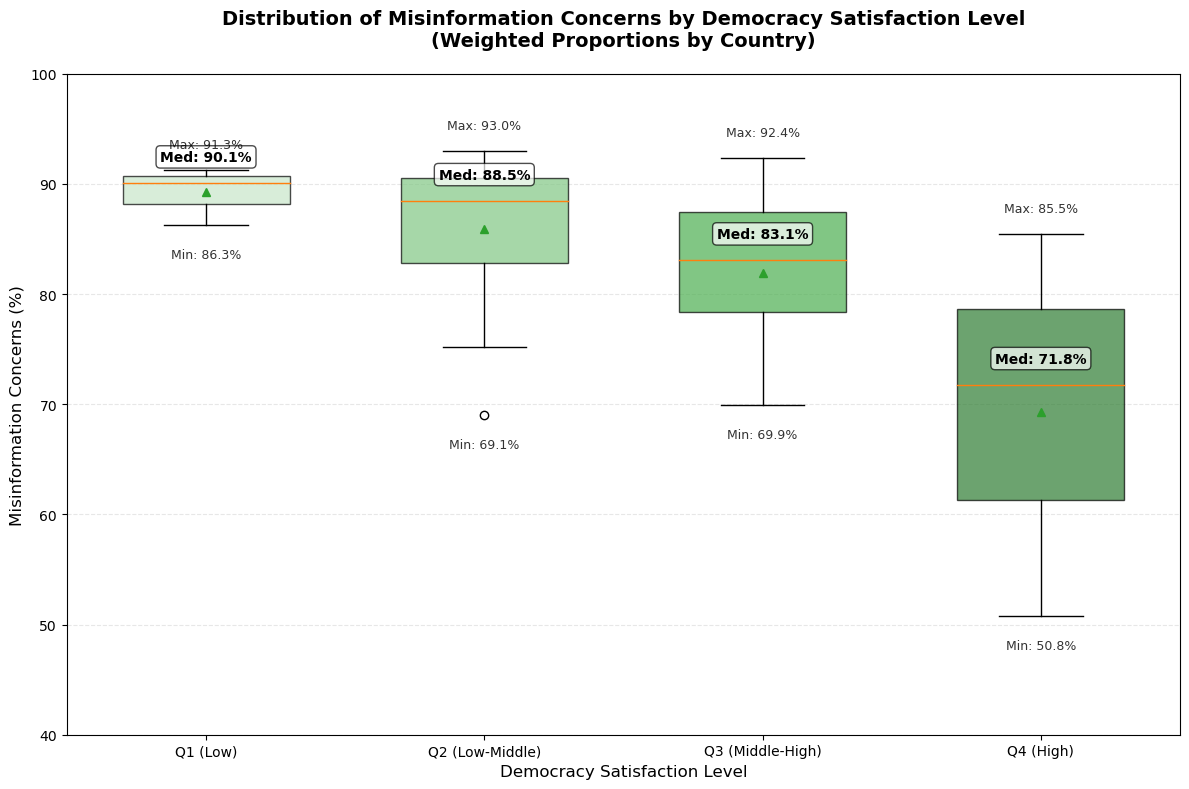

SUMMARY STATISTICS: Misinformation Concerns by Democracy Satisfaction Level

Q1: Low Democratic Satisfaction (n=3 countries):
  Countries: Colombia, Greece, Peru
  Misinformation Concerns:
    Median: 90.1%
    Mean: 89.2%
    Range: 86.3% - 91.3%
    Std Dev: 2.6%
  Democracy Satisfaction:
    Median: 21.3%
    Mean: 18.2%

Q2: Low-Medium Democratic Satisfaction (n=15 countries):
  Countries: Argentina, Brazil, Chile, France, Ghana, Hungary, Israel, Italy, Japan, South Africa, South Korea, Spain, Sri Lanka, Turkey, UK
  Misinformation Concerns:
    Median: 88.5%
    Mean: 85.9%
    Range: 69.1% - 93.0%
    Std Dev: 6.9%
  Democracy Satisfaction:
    Median: 36.3%
    Mean: 38.1%

Q3: Medium-High Democratic Satisfaction (n=10 countries):
  Countries: Australia, Canada, Germany, Kenya, Malaysia, Mexico, Netherlands, Philippines, Poland, Thailand
  Misinformation Concerns:
    Median: 83.1%
    Mean: 81.9%
    Range: 69.9% - 92.4%
    Std Dev: 7.9%
  Democracy Satisfaction:
    Median: 5

In [124]:
# Boxplot: Misinformation Concerns by Democracy Satisfaction Levels
# Grouping countries by democracy satisfaction and showing distribution of misinformation concerns

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['satisfied_democracy'].isin(['1', '2', '3', '4']) & 
    pew['prob_misinformation'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'satisfied_democracy', 'prob_misinformation'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For satisfied_democracy: % who are satisfied (1 or 2: very/somewhat satisfied)
    satisfied_democracy_satisfied = country_data[country_data['satisfied_democracy'].isin(['1', '2'])]['weight'].sum()
    satisfied_democracy_pct = (satisfied_democracy_satisfied / total_weight) * 100
    
    # For prob_misinformation: % who say it's "a very big problem" or "a moderately big problem" (1 or 2)
    misinfo_concern = country_data[country_data['prob_misinformation'].isin(['1', '2'])]['weight'].sum()
    misinfo_concern_pct = (misinfo_concern / total_weight) * 100
    
    country_stats[country] = {
        'satisfied_democracy_pct': satisfied_democracy_pct,
        'misinfo_concern_pct': misinfo_concern_pct
    }

# Convert to DataFrame
plot_df = pd.DataFrame(country_stats).T

# Categorize countries by democracy satisfaction levels (using tertiles)
def categorize_democracy_satisfaction(pct):
    if pct < 25:
        return 'Q1: Low Democratic Satisfaction'
    elif pct < 50:
        return 'Q2: Low-Medium Democratic Satisfaction'
    elif pct < 75:
        return 'Q3: Medium-High Democratic Satisfaction'
    else:
        return 'Q4: High Democratic Satisfaction'

plot_df['democracy_group'] = plot_df['satisfied_democracy_pct'].apply(categorize_democracy_satisfaction)

# Create boxplot
fig, ax = plt.subplots(figsize=(12, 8))

groups = ['Q1: Low Democratic Satisfaction', 'Q2: Low-Medium Democratic Satisfaction', 'Q3: Medium-High Democratic Satisfaction', 'Q4: High Democratic Satisfaction']
data_for_plot = [plot_df[plot_df['democracy_group'] == group]['misinfo_concern_pct'].values 
                 for group in groups]

# Shortened labels for x-axis
short_labels = ['Q1 (Low)', 'Q2 (Low-Middle)', 'Q3 (Middle-High)', 'Q4 (High)']

# Create boxplot
bp = ax.boxplot(data_for_plot, labels=short_labels, patch_artist=True,
                showmeans=True, meanline=False, widths=0.6)

# Color the boxes
colors = ['#C8E6C9', '#81C784', '#4CAF50', '#2E7D32']  # Purple gradients
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Add median labels
for i, group in enumerate(groups):
    group_data = plot_df[plot_df['democracy_group'] == group]['misinfo_concern_pct']
    if len(group_data) > 0:
        median_val = group_data.median()
        mean_val = group_data.mean()
        min_val = group_data.min()
        max_val = group_data.max()
        ax.text(i+1, median_val + 2, f'Med: {median_val:.1f}%',
               ha='center', fontsize=10, fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
        ax.text(i+1, min_val - 3, f'Min: {min_val:.1f}%',
               ha='center', fontsize=9, alpha=0.8)
        ax.text(i+1, max_val + 2, f'Max: {max_val:.1f}%',
               ha='center', fontsize=9, alpha=0.8)

ax.set_ylabel('Misinformation Concerns (%)', fontsize=12)
ax.set_xlabel('Democracy Satisfaction Level', fontsize=12)
ax.set_title('Distribution of Misinformation Concerns by Democracy Satisfaction Level\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')
ax.set_ylim(40, 100)
plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("SUMMARY STATISTICS: Misinformation Concerns by Democracy Satisfaction Level")
print("="*70)

for group in groups:
    group_data = plot_df[plot_df['democracy_group'] == group]
    if len(group_data) > 0:
        print(f"\n{group} (n={len(group_data)} countries):")
        print(f"  Countries: {', '.join(group_data.index.tolist())}")
        print(f"  Misinformation Concerns:")
        print(f"    Median: {group_data['misinfo_concern_pct'].median():.1f}%")
        print(f"    Mean: {group_data['misinfo_concern_pct'].mean():.1f}%")
        print(f"    Range: {group_data['misinfo_concern_pct'].min():.1f}% - {group_data['misinfo_concern_pct'].max():.1f}%")
        print(f"    Std Dev: {group_data['misinfo_concern_pct'].std():.1f}%")
        print(f"  Democracy Satisfaction:")
        print(f"    Median: {group_data['satisfied_democracy_pct'].median():.1f}%")
        print(f"    Mean: {group_data['satisfied_democracy_pct'].mean():.1f}%")

# Statistical test: Kruskal-Wallis (non-parametric test for comparing medians across groups)
from scipy.stats import kruskal

group_low = plot_df[plot_df['democracy_group'] == 'Q1: Low Democratic Satisfaction']['misinfo_concern_pct']
group_low_medium = plot_df[plot_df['democracy_group'] == 'Q2: Low-Medium Democratic Satisfaction']['misinfo_concern_pct']
group_medium_high = plot_df[plot_df['democracy_group'] == 'Q3: Medium-High Democratic Satisfaction']['misinfo_concern_pct']
group_high = plot_df[plot_df['democracy_group'] == 'Q4: High Democratic Satisfaction']['misinfo_concern_pct']

statistic, p_value = kruskal(group_low, group_low_medium, group_medium_high, group_high)

print(f"\n" + "="*70)
print("STATISTICAL TEST (Kruskal-Wallis):")
print("="*70)
print(f"  H-statistic: {statistic:.3f}")
print(f"  p-value: {p_value:.4f}")
if p_value < 0.05:
    print(f"  ✓ Statistically significant difference between groups!")
    print(f"  This confirms that democracy satisfaction levels are associated with")
    print(f"  different levels of misinformation concerns.")
else:
    print(f"  ✗ No statistically significant difference between groups")

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


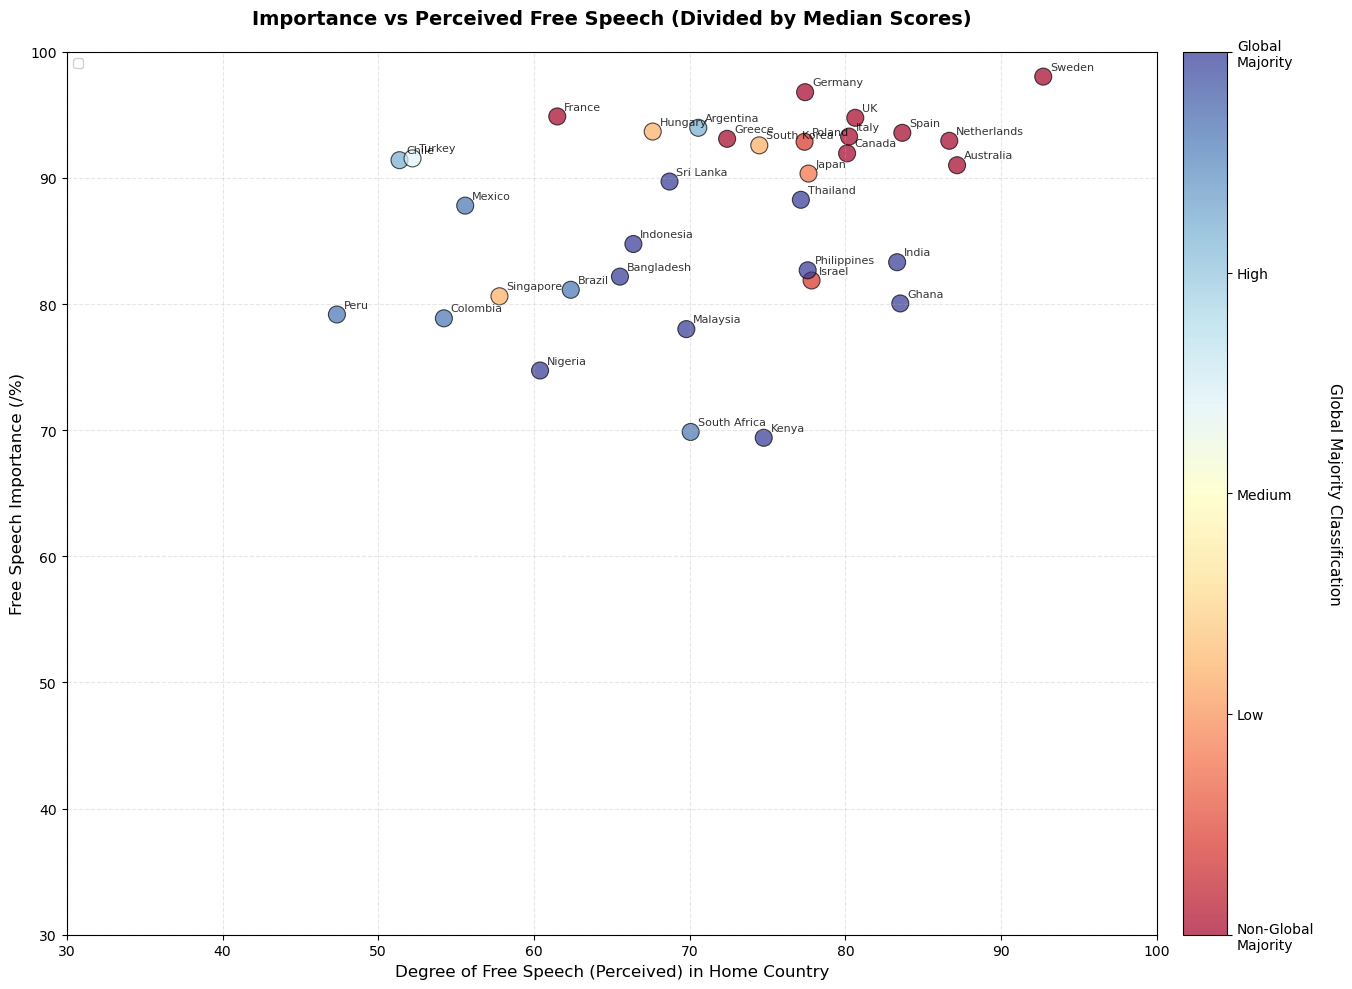

Summary Statistics (Weighted Proportions):

Number of countries: 34

Perceived Free Speech (% saying people are free):
  Mean: 71.4%
  Range: 47.3% - 92.7%

Importance of Free Speech (% saying it's important):
  Mean: 87.0%
  Range: 69.4% - 98.0%

Spearman Correlation: 0.363 (p-value: 0.0351)
  Statistically significant correlation!
COUNTRY STATS DIAGNOSTIC

Countries in country_stats: 34
Countries: ['Argentina', 'Australia', 'Bangladesh', 'Brazil', 'Canada', 'Chile', 'Colombia', 'France', 'Germany', 'Ghana', 'Greece', 'Hungary', 'India', 'Indonesia', 'Israel', 'Italy', 'Japan', 'Kenya', 'Malaysia', 'Mexico', 'Netherlands', 'Nigeria', 'Peru', 'Philippines', 'Poland', 'Singapore', 'South Africa', 'South Korea', 'Spain', 'Sri Lanka', 'Sweden', 'Thailand', 'Turkey', 'UK']

All countries from valid_data are in country_stats


In [295]:
# Scatterplot: free_say (perceived) vs free_speech (importance) with Global Majority Gradient
# Color-coding each country by Global Majority classification

# Global Majority classification (1.0 = Global Majority, 0.0 = Non-Global Majority)
global_majority_scores = {
    # Global Majority countries (score = 0.8-1.0)
    'Kenya': 1.0,
    'Malaysia': 1.0,
    'Bangladesh': 1.0,
    'Thailand': 1.0,
    'Sri Lanka': 1.0,
    'Philippines': 1.0,
    'Ghana': 1.0,
    'India': 0.999,
    'Nigeria': 0.998,
    'Indonesia': 0.997,
    'Tunisia': 1.0,
    'Brazil': 0.9,
    'Mexico': 0.9,
    'Argentina': 0.8,
    'Chile': 0.8,
    'Colombia': 0.9,
    'Peru': 0.9,
    'South Africa': 0.9,
    'Singapore': 0.3,  # Developed but in Global South
    
    # Mixed/Transitional (score = 0.4-0.7)
    'Turkey': 0.6,
    'Hungary': 0.3,
    'South Korea': 0.3,
    'Japan': 0.2,
    
    # Non-Global Majority (score = 0.0-0.3)
    'United States': 0.0,
    'Canada': 0.0,
    'UK': 0.0,
    'France': 0.0,
    'Germany': 0.0,
    'Italy': 0.0,
    'Spain': 0.0,
    'Netherlands': 0.0,
    'Sweden': -0.03,
    'Greece': 0.0,
    'Australia': 0.0,
    'Israel': 0.1,
    'Poland': 0.1,
}

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['free_say'].isin(['1', '2', '3', '4']) & 
    pew['free_speech'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'free_say', 'free_speech'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For free_say: % who say people are "completely" or "somewhat" free (1 or 2)
    free_say_free = country_data[country_data['free_say'].isin(['1', '2'])]['weight'].sum()
    free_say_free_pct = (free_say_free / total_weight) * 100
    
    # For free_speech: % who say it's "very important" or "somewhat important" (1 or 2)
    free_speech_important = country_data[country_data['free_speech'].isin(['1', '2'])]['weight'].sum()
    free_speech_important_pct = (free_speech_important / total_weight) * 100
    
    # Get Global Majority score (default to 0.5 if not found)
    global_majority_score = global_majority_scores.get(country, 0.5)
    
    country_stats[country] = {
        'perceived_free_pct': free_say_free_pct,
        'importance_pct': free_speech_important_pct,
        'global_majority': global_majority_score
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Create scatterplot with gradient coloring
fig, ax = plt.subplots(figsize=(14, 10))

# Use colormap - Red (Non-Global Majority) to Blue (Global Majority)
scatter = ax.scatter(plot_df['perceived_free_pct'], 
                     plot_df['importance_pct'], 
                     c=plot_df['global_majority'],
                     s=150, alpha=0.7, edgecolors='black', linewidth=0.8,
                     cmap='RdYlBu',  # Red (Non-Global Majority) to Blue (Global Majority)
                     vmin=0, vmax=1)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'perceived_free_pct'], 
                 plot_df.loc[country, 'importance_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Add trend line
#z = np.polyfit(plot_df['perceived_free_pct'], 
#               plot_df['importance_pct'], 1)
#p = np.poly1d(z)
#ax.plot(plot_df['perceived_free_pct'], 
#        p(plot_df['perceived_free_pct']), 
#         "k--", alpha=0.4, linewidth=2, label='Trend line', zorder=2)

# Add colorbar on the right
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Global Majority Classification', fontsize=11, rotation=270, labelpad=20)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['Non-Global\nMajority', 'Low', 'Medium', 'High', 'Global\nMajority'])

# Customize axes
ax.set_xlabel('Degree of Free Speech (Perceived) in Home Country', 
              fontsize=12)
ax.set_ylabel('Free Speech Importance (/%)', 
              fontsize=12)
ax.set_title('Importance vs Perceived Free Speech (Divided by Median Scores)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(30, 100)
ax.set_ylim(30, 100)
ax.legend(loc='upper left', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nPerceived Free Speech (% saying people are free):")
print(f"  Mean: {plot_df['perceived_free_pct'].mean():.1f}%")
print(f"  Range: {plot_df['perceived_free_pct'].min():.1f}% - {plot_df['perceived_free_pct'].max():.1f}%")
print(f"\nImportance of Free Speech (% saying it's important):")
print(f"  Mean: {plot_df['importance_pct'].mean():.1f}%")
print(f"  Range: {plot_df['importance_pct'].min():.1f}% - {plot_df['importance_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['perceived_free_pct'], plot_df['importance_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

# After your country_stats loop, add this:
print("="*70)
print("COUNTRY STATS DIAGNOSTIC")
print("="*70)

print(f"\nCountries in country_stats: {len(country_stats)}")
print(f"Countries: {sorted(country_stats.keys())}")

# Check which countries from valid_data didn't make it into country_stats
all_countries_in_data = set(valid_data['country_name'].unique())
countries_in_stats = set(country_stats.keys())
missing_from_stats = all_countries_in_data - countries_in_stats

if len(missing_from_stats) > 0:
    print(f"\nCountries in valid_data but NOT in country_stats: {len(missing_from_stats)}")
    print(f"Countries: {sorted(missing_from_stats)}")
    
    # Check why they're missing - do they have zero total_weight?
    for country in missing_from_stats:
        country_data = valid_data[valid_data['country_name'] == country]
        total_weight = country_data['weight'].sum()
        print(f"\n  {country}:")
        print(f"    Total weight: {total_weight}")
        print(f"    Number of rows: {len(country_data)}")
        print(f"    free_say values: {country_data['free_say'].value_counts().to_dict()}")
        print(f"    free_speech values: {country_data['free_speech'].value_counts().to_dict()}")
else:
    print("\nAll countries from valid_data are in country_stats")

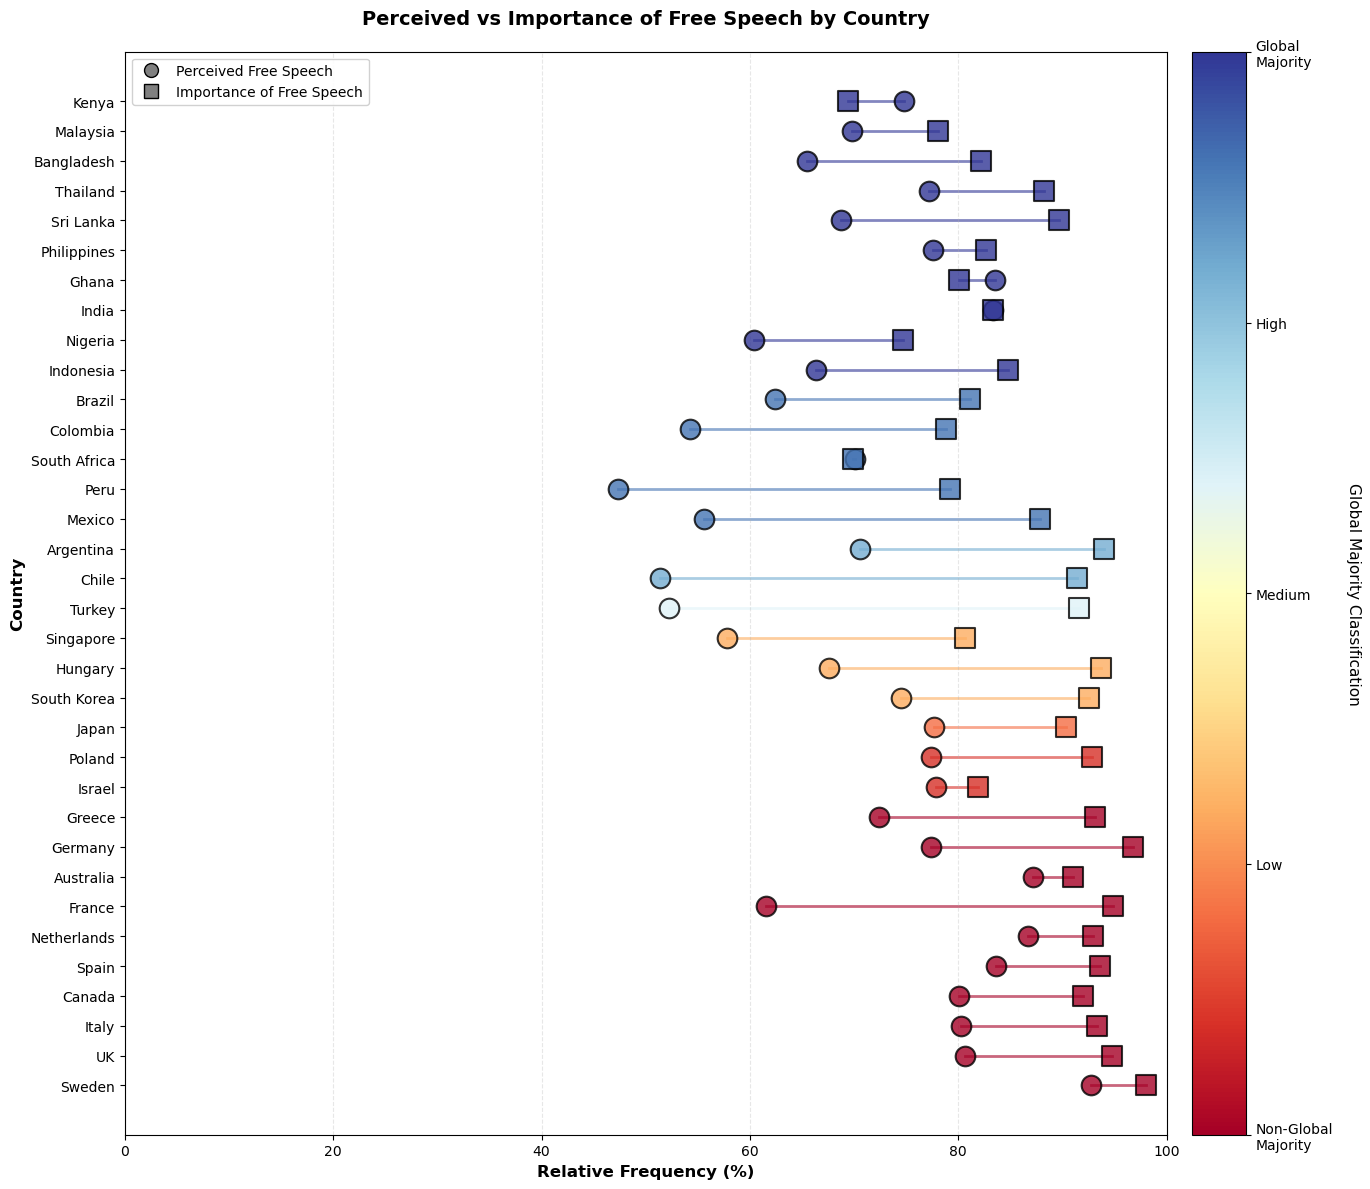

DUMBBELL PLOT SUMMARY

Number of countries: 34

Sorted by Global Majority Classification (Non-Global Majority to Global Majority)

Gap Analysis (Importance - Perceived):
  Mean gap: 15.7 percentage points
  Range: -5.4 to 40.0 percentage points

Countries where importance > perceived: 30
Countries where perceived > importance: 4
Countries where they're equal: 0


In [296]:
# Dumbbell Plot: Perceived Free Speech vs Importance of Free Speech by Country
# Shows the gap between perceived and importance, color-coded by Global Majority

# Use the same plot_df from your previous code
# Make sure plot_df has 'perceived_free_pct', 'importance_pct', and 'global_majority' columns

# Sort countries by Global Majority (to match scatter plot pattern)
plot_df_sorted = plot_df.sort_values('global_majority', ascending=False)

# Create dumbbell plot
fig, ax = plt.subplots(figsize=(14, 12))

y_pos = np.arange(len(plot_df_sorted))

# Plot lines and points for each country
for i, country in enumerate(plot_df_sorted.index):
    perceived = plot_df_sorted.loc[country, 'perceived_free_pct']
    importance = plot_df_sorted.loc[country, 'importance_pct']
    global_majority = plot_df_sorted.loc[country, 'global_majority']
    
    # Get color from Global Majority gradient
    cmap = plt.cm.RdYlBu  # Red (Non-Global Majority) to Blue (Global Majority)
    norm = plt.Normalize(vmin=0, vmax=1)
    color = cmap(norm(global_majority))
    
    # Draw connecting line
    ax.plot([perceived, importance], [i, i], 
           color=color, linewidth=2, alpha=0.6, zorder=1)
    
    # Draw points
    ax.scatter(perceived, i, s=200, color=color, alpha=0.8, 
              edgecolors='black', linewidth=1.5, zorder=3, 
              marker='o', label='Perceived' if i == 0 else '')
    ax.scatter(importance, i, s=200, color=color, alpha=0.8, 
              edgecolors='black', linewidth=1.5, zorder=3, 
              marker='s', label='Importance' if i == 0 else '')

# Add colorbar for Global Majority
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Global Majority Classification', fontsize=11, rotation=270, labelpad=20)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['Non-Global\nMajority', 'Low', 'Medium', 'High', 'Global\nMajority'])

# Customize the plot
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df_sorted.index, fontsize=10)
ax.set_xlabel('Relative Frequency (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Country', fontsize=12, fontweight='bold')
ax.set_title('Perceived vs Importance of Free Speech by Country',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 100)
ax.grid(True, alpha=0.3, axis='x', linestyle='--', zorder=0)
ax.invert_yaxis()  # Top to bottom

# Add legend for point markers
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
           markersize=10, markeredgecolor='black', label='Perceived Free Speech'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', 
           markersize=10, markeredgecolor='black', label='Importance of Free Speech')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("DUMBBELL PLOT SUMMARY")
print("="*70)
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nSorted by Global Majority Classification (Non-Global Majority to Global Majority)")

# Calculate gap for summary
plot_df['gap'] = plot_df['importance_pct'] - plot_df['perceived_free_pct']
print(f"\nGap Analysis (Importance - Perceived):")
print(f"  Mean gap: {plot_df['gap'].mean():.1f} percentage points")
print(f"  Range: {plot_df['gap'].min():.1f} to {plot_df['gap'].max():.1f} percentage points")
print(f"\nCountries where importance > perceived: {len(plot_df[plot_df['gap'] > 0])}")
print(f"Countries where perceived > importance: {len(plot_df[plot_df['gap'] < 0])}")
print(f"Countries where they're equal: {len(plot_df[plot_df['gap'] == 0])}")

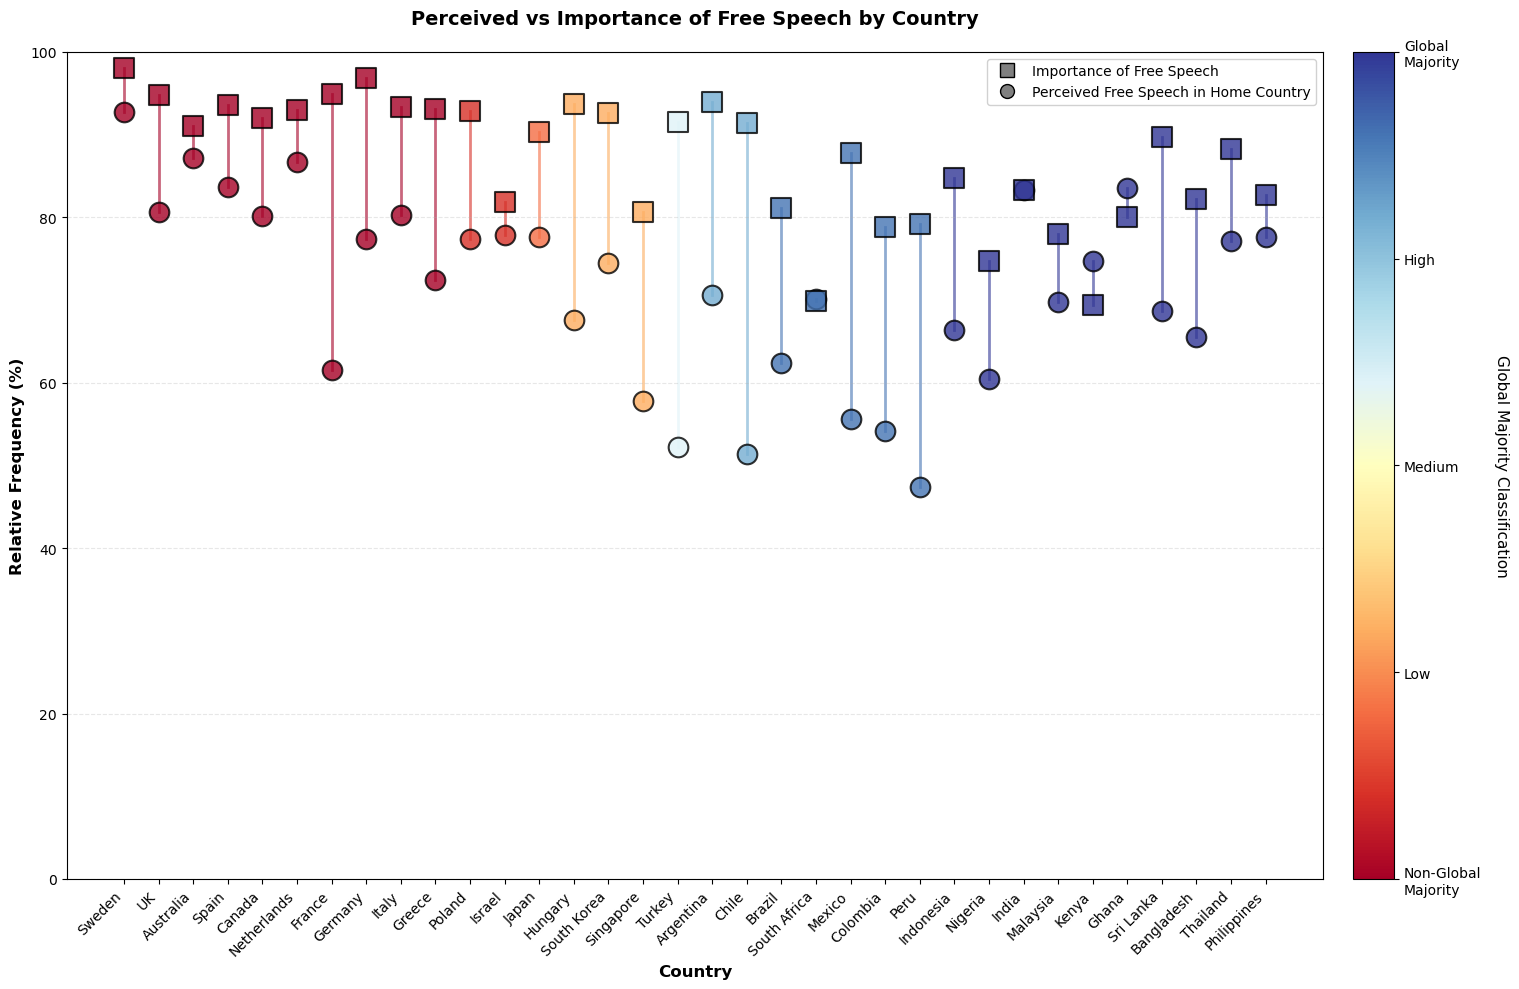

DUMBBELL PLOT SUMMARY

Number of countries: 34

Sorted by Global Majority Classification (Global Majority to Non-Global Majority)

Gap Analysis (Importance - Perceived):
  Mean gap: 15.7 percentage points
  Range: -5.4 to 40.0 percentage points

Countries where importance > perceived: 30
Countries where perceived > importance: 4
Countries where they're equal: 0


In [ ]:
# Dumbbell Plot: Perceived Free Speech vs Importance of Free Speech by Country
# Flipped axes: Countries on x-axis, Relative Frequency on y-axis
# Shows the gap between perceived and importance, color-coded by Global Majority

# Use the same plot_df from your previous code
# Make sure plot_df has 'perceived_free_pct', 'importance_pct', and 'global_majority' columns

# Sort countries by Global Majority (descending - Global Majority first)
plot_df_sorted = plot_df.sort_values('global_majority', ascending=True)

# Create dumbbell plot with flipped axes
fig, ax = plt.subplots(figsize=(16, 10))

x_pos = np.arange(len(plot_df_sorted))

# Plot lines and points for each country
for i, country in enumerate(plot_df_sorted.index):
    perceived = plot_df_sorted.loc[country, 'perceived_free_pct']
    importance = plot_df_sorted.loc[country, 'importance_pct']
    global_majority = plot_df_sorted.loc[country, 'global_majority']
    
    # Get color from Global Majority gradient
    cmap = plt.cm.RdYlBu  # Red (Non-Global Majority) to Blue (Global Majority)
    norm = plt.Normalize(vmin=0, vmax=1)
    color = cmap(norm(global_majority))
    
    # Draw connecting line (vertical now)
    ax.plot([i, i], [perceived, importance], 
           color=color, linewidth=2, alpha=0.6, zorder=1)
    
    # Draw points
    ax.scatter(i, perceived, s=200, color=color, alpha=0.8, 
              edgecolors='black', linewidth=1.5, zorder=3, 
              marker='o', label='Perceived' if i == 0 else '')
    ax.scatter(i, importance, s=200, color=color, alpha=0.8, 
              edgecolors='black', linewidth=1.5, zorder=3, 
              marker='s', label='Importance' if i == 0 else '')

# Add colorbar for Global Majority
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Global Majority Classification', fontsize=11, rotation=270, labelpad=20)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['Non-Global\nMajority', 'Low', 'Medium', 'High', 'Global\nMajority'])

# Customize the plot
ax.set_xticks(x_pos)
ax.set_xticklabels(plot_df_sorted.index, rotation=45, ha='right', fontsize=10)
ax.set_xlabel('Country', fontsize=12, fontweight='bold')
ax.set_ylabel('Relative Frequency (%)', fontsize=12, fontweight='bold')
ax.set_title('Perceived vs Importance of Free Speech by Country',
             fontsize=14, fontweight='bold', pad=20)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3, axis='y', linestyle='--', zorder=0)

# Add legend for point markers
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', 
           markersize=10, markeredgecolor='black', label='Importance of Free Speech'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
           markersize=10, markeredgecolor='black', label='Perceived Free Speech in Home Country')
]

ax.legend(handles=legend_elements, loc='upper right', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("DUMBBELL PLOT SUMMARY")
print("="*70)
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nSorted by Global Majority Classification (Global Majority to Non-Global Majority)")

# Calculate gap for summary
plot_df['gap'] = plot_df['importance_pct'] - plot_df['perceived_free_pct']
print(f"\nGap Analysis (Importance - Perceived):")
print(f"  Mean gap: {plot_df['gap'].mean():.1f} percentage points")
print(f"  Range: {plot_df['gap'].min():.1f} to {plot_df['gap'].max():.1f} percentage points")
print(f"\nCountries where importance > perceived: {len(plot_df[plot_df['gap'] > 0])}")
print(f"Countries where perceived > importance: {len(plot_df[plot_df['gap'] < 0])}")
print(f"Countries where they're equal: {len(plot_df[plot_df['gap'] == 0])}")

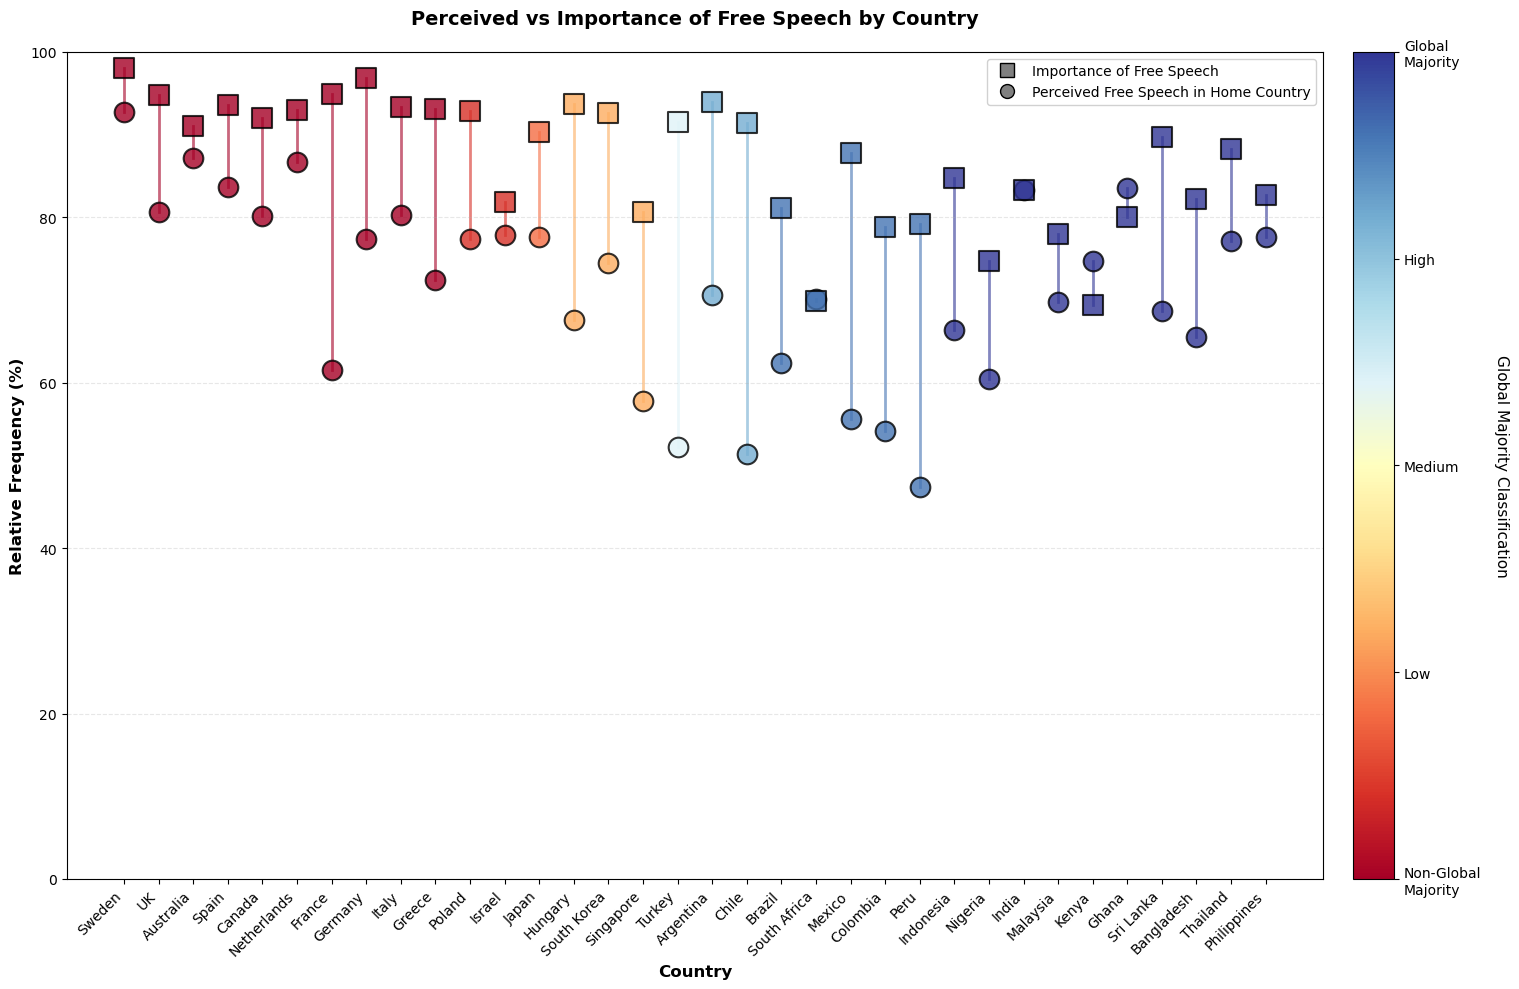

DUMBBELL PLOT SUMMARY

Number of countries: 34

Sorted by Global Majority Classification (Non-Global Majority to Global Majority)

Gap Analysis (Importance - Perceived):
  Mean gap: 15.7 percentage points
  Range: -5.4 to 40.0 percentage points

Countries where importance > perceived: 30
Countries where perceived > importance: 4
Countries where they're equal: 0


In [304]:
# Dumbbell Plot: Perceived Free Speech vs Importance of Free Speech by Country
# Flipped axes: Countries on x-axis, Relative Frequency on y-axis
# Shows the gap between perceived and importance, color-coded by Global Majority

# Global Majority classification (1.0 = Global Majority, 0.0 = Non-Global Majority)
global_majority_scores = {
    # Global Majority countries (score = 0.8-1.0)
    'Philippines': 1.0,
    'Kenya': 1.0,
    'Malaysia': 1.0,
    'Bangladesh': 1.0,
    'Thailand': 1.0,
    'Sri Lanka': 1.0,
    'Ghana': 1.0,
    'Nigeria': 0.998,
    'India': 0.999,
    'Indonesia': 0.997,
    'Brazil': 0.9,
    'Colombia': 0.9,
    'South Africa': 0.9,
    'Peru': 0.9,
    'Mexico': 0.9,
    'Argentina': 0.8,
    'Chile': 0.8,
    
    # Mixed/Transitional (score = 0.4-0.7)
    'Turkey': 0.6,
    'Singapore': 0.3,
    'Hungary': 0.3,
    'South Korea': 0.3,
    'Japan': 0.2,
    
    # Non-Global Majority (score = 0.0-0.3)
    'Poland': 0.1,
    'Israel': 0.1,
    'Greece': 0.0,
    'Germany': 0.0,
    'Australia': 0.0,
    'France': 0.0,
    'Netherlands': 0.0,
    'Spain': 0.0,
    'Canada': 0.0,
    'Italy': 0.0,
    'UK': 0.0,
    'Sweden': -0.1,
}

# Use the same plot_df from your previous code
# Make sure plot_df has 'perceived_free_pct' and 'importance_pct' columns

# Assign Global Majority scores from dictionary (or use existing if already in plot_df)
if 'global_majority' not in plot_df.columns:
    plot_df['global_majority'] = plot_df.index.map(lambda x: global_majority_scores.get(x, 0.5))
else:
    # Update with dictionary values (gives you control to override)
    plot_df['global_majority'] = plot_df.index.map(lambda x: global_majority_scores.get(x, plot_df.loc[x, 'global_majority']))

# Sort countries by Global Majority (ascending - Non-Global Majority first, Global Majority last)
plot_df_sorted = plot_df.sort_values('global_majority', ascending=True)

# Create dumbbell plot with flipped axes
fig, ax = plt.subplots(figsize=(16, 10))

x_pos = np.arange(len(plot_df_sorted))

# Plot lines and points for each country
for i, country in enumerate(plot_df_sorted.index):
    perceived = plot_df_sorted.loc[country, 'perceived_free_pct']
    importance = plot_df_sorted.loc[country, 'importance_pct']
    global_majority = plot_df_sorted.loc[country, 'global_majority']
    
    # Get color from Global Majority gradient
    cmap = plt.cm.RdYlBu  # Red (Non-Global Majority) to Blue (Global Majority)
    norm = plt.Normalize(vmin=0, vmax=1)
    color = cmap(norm(global_majority))
    
    # Draw connecting line (vertical now)
    ax.plot([i, i], [perceived, importance], 
           color=color, linewidth=2, alpha=0.6, zorder=1)
    
    # Draw points
    ax.scatter(i, perceived, s=200, color=color, alpha=0.8, 
              edgecolors='black', linewidth=1.5, zorder=3, 
              marker='o', label='Perceived' if i == 0 else '')
    ax.scatter(i, importance, s=200, color=color, alpha=0.8, 
              edgecolors='black', linewidth=1.5, zorder=3, 
              marker='s', label='Importance' if i == 0 else '')

# Add colorbar for Global Majority
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Global Majority Classification', fontsize=11, rotation=270, labelpad=20)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['Non-Global\nMajority', 'Low', 'Medium', 'High', 'Global\nMajority'])

# Customize the plot
ax.set_xticks(x_pos)
ax.set_xticklabels(plot_df_sorted.index, rotation=45, ha='right', fontsize=10)
ax.set_xlabel('Country', fontsize=12, fontweight='bold')
ax.set_ylabel('Relative Frequency (%)', fontsize=12, fontweight='bold')
ax.set_title('Perceived vs Importance of Free Speech by Country',
             fontsize=14, fontweight='bold', pad=20)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3, axis='y', linestyle='--', zorder=0)

# Add legend for point markers
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', 
           markersize=10, markeredgecolor='black', label='Importance of Free Speech'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
           markersize=10, markeredgecolor='black', label='Perceived Free Speech in Home Country')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("DUMBBELL PLOT SUMMARY")
print("="*70)
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nSorted by Global Majority Classification (Non-Global Majority to Global Majority)")

# Calculate gap for summary
plot_df['gap'] = plot_df['importance_pct'] - plot_df['perceived_free_pct']
print(f"\nGap Analysis (Importance - Perceived):")
print(f"  Mean gap: {plot_df['gap'].mean():.1f} percentage points")
print(f"  Range: {plot_df['gap'].min():.1f} to {plot_df['gap'].max():.1f} percentage points")
print(f"\nCountries where importance > perceived: {len(plot_df[plot_df['gap'] > 0])}")
print(f"Countries where perceived > importance: {len(plot_df[plot_df['gap'] < 0])}")
print(f"Countries where they're equal: {len(plot_df[plot_df['gap'] == 0])}")

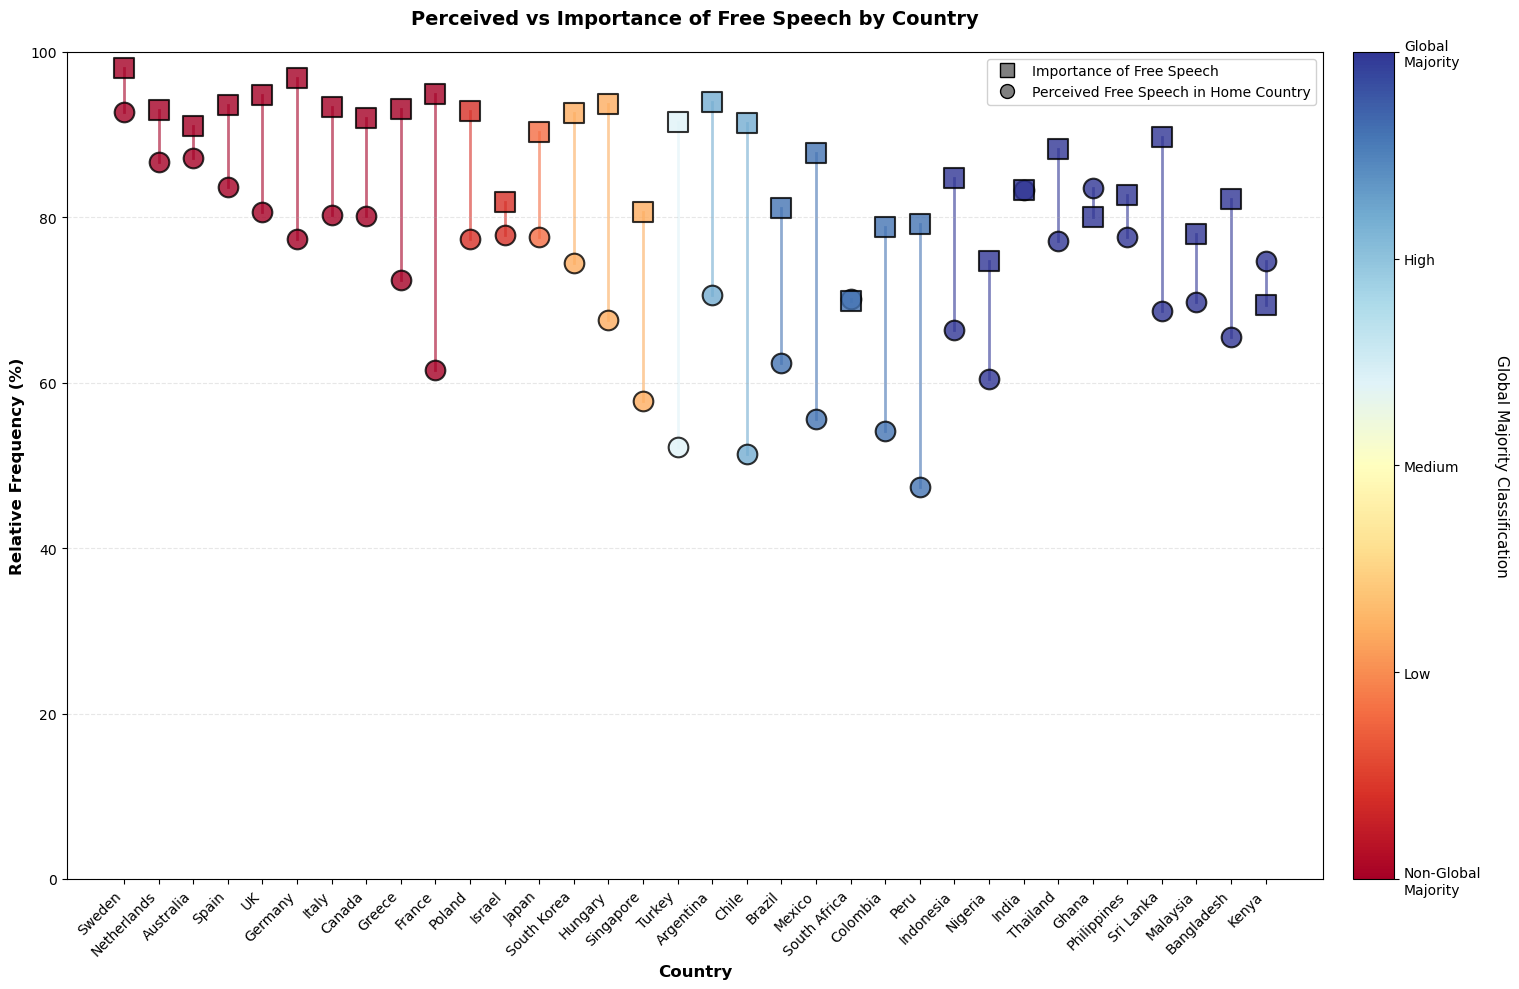

DUMBBELL PLOT SUMMARY

Number of countries: 34

Sorted by Global Majority (descending) then by average of both variables (descending)

Gap Analysis (Importance - Perceived):
  Mean gap: 15.7 percentage points
  Range: -5.4 to 40.0 percentage points

Countries where importance > perceived: 30
Countries where perceived > importance: 4
Countries where they're equal: 0


In [308]:
# Dumbbell Plot: Perceived Free Speech vs Importance of Free Speech by Country
# Flipped axes: Countries on x-axis, Relative Frequency on y-axis
# Shows the gap between perceived and importance, color-coded by Global Majority

# Global Majority classification (1.0 = Global Majority, 0.0 = Non-Global Majority)
global_majority_scores = {
    # Global Majority countries (score = 0.8-1.0)
    'Kenya': 1.0,
    'Malaysia': 1.0,
    'Bangladesh': 1.0,
    'Thailand': 1.0,
    'Sri Lanka': 1.0,
    'Philippines': 1.0,
    'Ghana': 1.0,
    'Nigeria': 0.998,
    'India': 0.999,
    'Indonesia': 0.997,
    'Brazil': 0.9,
    'Colombia': 0.9,
    'South Africa': 0.9,
    'Peru': 0.9,
    'Mexico': 0.9,
    'Argentina': 0.8,
    'Chile': 0.8,
    
    # Mixed/Transitional (score = 0.4-0.7)
    'Turkey': 0.6,
    'Singapore': 0.3,
    'Hungary': 0.3,
    'South Korea': 0.3,
    'Japan': 0.2,
    
    # Non-Global Majority (score = 0.0-0.3)
    'Poland': 0.1,
    'Israel': 0.1,
    'Greece': 0.0,
    'Germany': 0.0,
    'Australia': 0.0,
    'France': 0.0,
    'Netherlands': 0.0,
    'Spain': 0.0,
    'Canada': 0.0,
    'Italy': 0.0,
    'UK': 0.0,
    'Sweden': -0.1,
}

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['free_say'].isin(['1', '2', '3', '4']) & 
    pew['free_speech'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'free_say', 'free_speech'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For free_say: % who say people are "completely" or "somewhat" free (1 or 2)
    free_say_free = country_data[country_data['free_say'].isin(['1', '2'])]['weight'].sum()
    free_say_free_pct = (free_say_free / total_weight) * 100
    
    # For free_speech: % who say it's "very important" or "somewhat important" (1 or 2)
    free_speech_important = country_data[country_data['free_speech'].isin(['1', '2'])]['weight'].sum()
    free_speech_important_pct = (free_speech_important / total_weight) * 100
    
    # Get Global Majority score (default to 0.5 if not found)
    global_majority_score = global_majority_scores.get(country, 0.5)
    
    country_stats[country] = {
        'perceived_free_pct': free_say_free_pct,
        'importance_pct': free_speech_important_pct,
        'global_majority': global_majority_score
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Sort by Global Majority (descending) first, then by average of perceived and importance (descending)
# This creates the smoothest overall descending pattern across both variables
plot_df['avg_value'] = (plot_df['perceived_free_pct'] + plot_df['importance_pct']) / 2
plot_df_sorted = plot_df.sort_values(['global_majority', 'avg_value'], ascending=[True, False])
plot_df_sorted = plot_df_sorted.drop('avg_value', axis=1)

# Create dumbbell plot with flipped axes
fig, ax = plt.subplots(figsize=(16, 10))

x_pos = np.arange(len(plot_df_sorted))

# Plot lines and points for each country
for i, country in enumerate(plot_df_sorted.index):
    perceived = plot_df_sorted.loc[country, 'perceived_free_pct']
    importance = plot_df_sorted.loc[country, 'importance_pct']
    global_majority = plot_df_sorted.loc[country, 'global_majority']
    
    # Get color from Global Majority gradient
    cmap = plt.cm.RdYlBu  # Red (Non-Global Majority) to Blue (Global Majority)
    norm = plt.Normalize(vmin=0, vmax=1)
    color = cmap(norm(global_majority))
    
    # Draw connecting line (vertical now)
    ax.plot([i, i], [perceived, importance], 
           color=color, linewidth=2, alpha=0.6, zorder=1)
    
    # Draw points
    ax.scatter(i, perceived, s=200, color=color, alpha=0.8, 
              edgecolors='black', linewidth=1.5, zorder=3, 
              marker='o', label='Perceived' if i == 0 else '')
    ax.scatter(i, importance, s=200, color=color, alpha=0.8, 
              edgecolors='black', linewidth=1.5, zorder=3, 
              marker='s', label='Importance' if i == 0 else '')

# Add colorbar for Global Majority
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Global Majority Classification', fontsize=11, rotation=270, labelpad=20)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['Non-Global\nMajority', 'Low', 'Medium', 'High', 'Global\nMajority'])

# Customize the plot
ax.set_xticks(x_pos)
ax.set_xticklabels(plot_df_sorted.index, rotation=45, ha='right', fontsize=10)
ax.set_xlabel('Country', fontsize=12, fontweight='bold')
ax.set_ylabel('Relative Frequency (%)', fontsize=12, fontweight='bold')
ax.set_title('Perceived vs Importance of Free Speech by Country',
             fontsize=14, fontweight='bold', pad=20)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3, axis='y', linestyle='--', zorder=0)

# Add legend for point markers
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', 
           markersize=10, markeredgecolor='black', label='Importance of Free Speech'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
           markersize=10, markeredgecolor='black', label='Perceived Free Speech in Home Country')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("DUMBBELL PLOT SUMMARY")
print("="*70)
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nSorted by Global Majority (descending) then by average of both variables (descending)")

# Calculate gap for summary
plot_df['gap'] = plot_df['importance_pct'] - plot_df['perceived_free_pct']
print(f"\nGap Analysis (Importance - Perceived):")
print(f"  Mean gap: {plot_df['gap'].mean():.1f} percentage points")
print(f"  Range: {plot_df['gap'].min():.1f} to {plot_df['gap'].max():.1f} percentage points")
print(f"\nCountries where importance > perceived: {len(plot_df[plot_df['gap'] > 0])}")
print(f"Countries where perceived > importance: {len(plot_df[plot_df['gap'] < 0])}")
print(f"Countries where they're equal: {len(plot_df[plot_df['gap'] == 0])}")

# Next visualisation:

- countries on the Y axis
- bar chart seperated by ordinal values
- percentage on the bottom

# Boxplot

- it is okay to have quartiles on the x axis

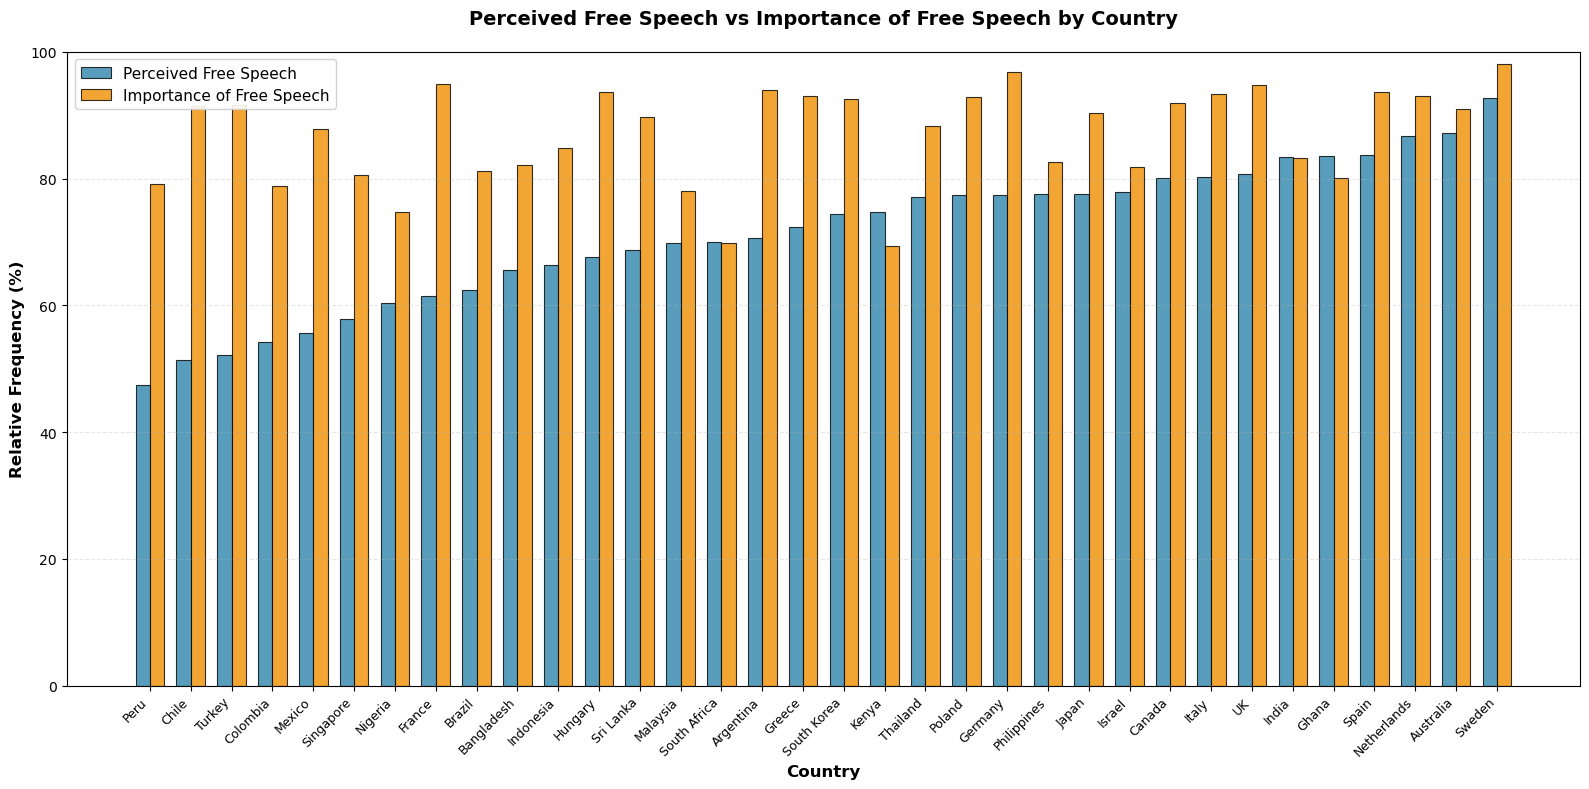

Summary Statistics (Weighted Proportions):

Number of countries: 34

Perceived Free Speech (% saying people are free):
  Mean: 71.4%
  Range: 47.3% - 92.7%

Importance of Free Speech (% saying it's important):
  Mean: 87.0%
  Range: 69.4% - 98.0%


In [259]:
# Grouped Bar Chart: Perceived Free Speech vs Importance of Free Speech by Country
# Countries on x-axis, relative frequencies on y-axis

# Global Majority classification (1.0 = Global Majority, 0.0 = Non-Global Majority)
global_majority_scores = {
    # Global Majority countries (score = 0.8-1.0)
    'India': 1.0,
    'Indonesia': 1.0,
    'Bangladesh': 1.0,
    'Nigeria': 1.0,
    'Kenya': 1.0,
    'Ghana': 1.0,
    'Philippines': 1.0,
    'Thailand': 1.0,
    'Sri Lanka': 1.0,
    'Tunisia': 1.0,
    'Brazil': 0.9,
    'Mexico': 0.9,
    'Argentina': 0.8,
    'Chile': 0.8,
    'Colombia': 0.9,
    'Peru': 0.9,
    'South Africa': 0.9,
    'Malaysia': 1.0,
    'Singapore': 0.3,
    
    # Mixed/Transitional (score = 0.4-0.7)
    'Turkey': 0.6,
    'Hungary': 0.3,
    'South Korea': 0.3,
    'Japan': 0.2,
    
    # Non-Global Majority (score = 0.0-0.3)
    'United States': 0.0,
    'Canada': 0.0,
    'UK': 0.0,
    'France': 0.0,
    'Germany': 0.0,
    'Italy': 0.0,
    'Spain': 0.0,
    'Netherlands': 0.0,
    'Sweden': 0.0,
    'Greece': 0.0,
    'Australia': 0.0,
    'Israel': 0.1,
    'Poland': 0.1,
}

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['free_say'].isin(['1', '2', '3', '4']) & 
    pew['free_speech'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'free_say', 'free_speech'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For free_say: % who say people are "completely" or "somewhat" free (1 or 2)
    free_say_free = country_data[country_data['free_say'].isin(['1', '2'])]['weight'].sum()
    free_say_free_pct = (free_say_free / total_weight) * 100
    
    # For free_speech: % who say it's "very important" or "somewhat important" (1 or 2)
    free_speech_important = country_data[country_data['free_speech'].isin(['1', '2'])]['weight'].sum()
    free_speech_important_pct = (free_speech_important / total_weight) * 100
    
    # Get Global Majority score (default to 0.5 if not found)
    global_majority_score = global_majority_scores.get(country, 0.5)
    
    country_stats[country] = {
        'perceived_free_pct': free_say_free_pct,
        'importance_pct': free_speech_important_pct,
        'global_majority': global_majority_score
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Sort countries for better visualization (e.g., by perceived free speech)
plot_df_sorted = plot_df.sort_values('perceived_free_pct', ascending=True)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(16, 8))

x = np.arange(len(plot_df_sorted))
width = 0.35  # Width of bars

# Create bars for both variables
# perceived_free_pct = from free_say (perceived free speech)
# importance_pct = from free_speech (importance of free speech)
bars1 = ax.bar(x - width/2, plot_df_sorted['perceived_free_pct'], 
               width, label='Perceived Free Speech', 
               color='#2E86AB', alpha=0.8, edgecolor='black', linewidth=0.8)

bars2 = ax.bar(x + width/2, plot_df_sorted['importance_pct'], 
               width, label='Importance of Free Speech', 
               color='#F18F01', alpha=0.8, edgecolor='black', linewidth=0.8)

# Customize the plot
ax.set_xlabel('Country', fontsize=12, fontweight='bold')
ax.set_ylabel('Relative Frequency (%)', fontsize=12, fontweight='bold')
ax.set_title('Perceived Free Speech vs Importance of Free Speech by Country',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(plot_df_sorted.index, rotation=45, ha='right', fontsize=9)
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, axis='y', linestyle='--', zorder=0)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nPerceived Free Speech (% saying people are free):")
print(f"  Mean: {plot_df['perceived_free_pct'].mean():.1f}%")
print(f"  Range: {plot_df['perceived_free_pct'].min():.1f}% - {plot_df['perceived_free_pct'].max():.1f}%")
print(f"\nImportance of Free Speech (% saying it's important):")
print(f"  Mean: {plot_df['importance_pct'].mean():.1f}%")
print(f"  Range: {plot_df['importance_pct'].min():.1f}% - {plot_df['importance_pct'].max():.1f}%")

Median Perceived Free Speech: 73.4%
Median Importance: 90.0%

Quadrants:
  Q1 (Top-Right): High Perceived Freedom + High Importance
  Q2 (Top-Left): Low Perceived Freedom + High Importance (Compensatory)
  Q3 (Bottom-Left): Low Perceived Freedom + Low Importance
  Q4 (Bottom-Right): High Perceived Freedom + Low Importance


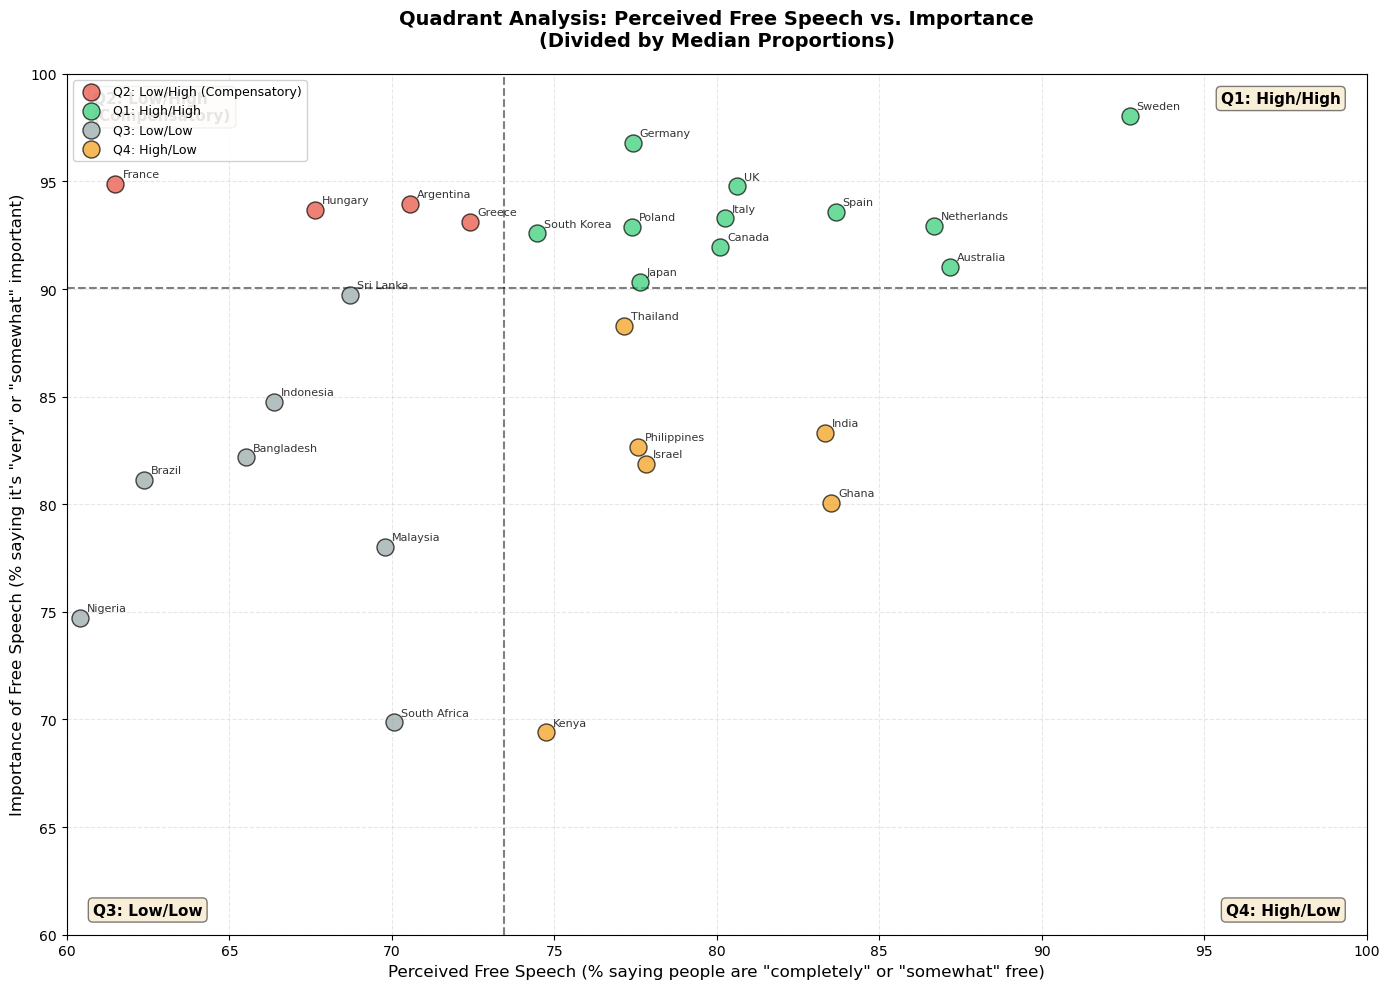


Countries by Quadrant:

Q1: High/High: 11 countries
  Australia, Canada, Germany, Italy, Japan, Netherlands, Poland, South Korea, Spain, Sweden, UK

Q2: Low/High (Compensatory): 6 countries
  Argentina, Chile, France, Greece, Hungary, Turkey

Q3: Low/Low: 11 countries
  Bangladesh, Brazil, Colombia, Indonesia, Malaysia, Mexico, Nigeria, Peru, Singapore, South Africa, Sri Lanka

Q4: High/Low: 6 countries
  Ghana, India, Israel, Kenya, Philippines, Thailand

Summary Statistics (Weighted Proportions):

Number of countries: 34

Perceived Free Speech (% saying people are free):
  Mean: 71.4%
  Range: 47.3% - 92.7%

Importance of Free Speech (% saying it's important):
  Mean: 87.0%
  Range: 69.4% - 98.0%

Spearman Correlation: 0.363 (p-value: 0.0351)
  Statistically significant correlation!


In [66]:
# Quadrant Plot: free_say (perceived) vs free_speech (importance)
# Using medians to divide into quadrants (appropriate for ordinal proportions)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['free_say'].isin(['1', '2', '3', '4']) & 
    pew['free_speech'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'free_say', 'free_speech'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For free_say: % who say people are "completely" or "somewhat" free (1 or 2)
    # Note: Lower values = more free, so we want 1 or 2
    free_say_free = country_data[country_data['free_say'].isin(['1', '2'])]['weight'].sum()
    free_say_free_pct = (free_say_free / total_weight) * 100
    
    # For free_speech: % who say it's "very important" or "somewhat important" (1 or 2)
    # Note: Lower values = more important, so we want 1 or 2
    free_speech_important = country_data[country_data['free_speech'].isin(['1', '2'])]['weight'].sum()
    free_speech_important_pct = (free_speech_important / total_weight) * 100
    
    country_stats[country] = {
        'perceived_free_pct': free_say_free_pct,  # % who perceive people as free to say what they want
        'importance_pct': free_speech_important_pct  # % who think free speech is important
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Calculate medians (not means!) to divide countries into quadrants
median_perceived = plot_df['perceived_free_pct'].median()
median_importance = plot_df['importance_pct'].median()

print(f"Median Perceived Free Speech: {median_perceived:.1f}%")
print(f"Median Importance: {median_importance:.1f}%")
print("\nQuadrants:")
print("  Q1 (Top-Right): High Perceived Freedom + High Importance")
print("  Q2 (Top-Left): Low Perceived Freedom + High Importance (Compensatory)")
print("  Q3 (Bottom-Left): Low Perceived Freedom + Low Importance")
print("  Q4 (Bottom-Right): High Perceived Freedom + Low Importance")

# Create quadrant plot
fig, ax = plt.subplots(figsize=(14, 10))

# Define quadrants based on medians
def get_quadrant(row):
    perceived = row['perceived_free_pct']
    importance = row['importance_pct']
    if perceived >= median_perceived and importance >= median_importance:
        return 'Q1: High/High'
    elif perceived < median_perceived and importance >= median_importance:
        return 'Q2: Low/High (Compensatory)'
    elif perceived < median_perceived and importance < median_importance:
        return 'Q3: Low/Low'
    else:
        return 'Q4: High/Low'

plot_df['quadrant'] = plot_df.apply(get_quadrant, axis=1)

# Color map for quadrants
colors = {
    'Q1: High/High': '#2ecc71',  # Green
    'Q2: Low/High (Compensatory)': '#e74c3c',  # Red
    'Q3: Low/Low': '#95a5a6',  # Gray
    'Q4: High/Low': '#f39c12'  # Orange
}

# Plot points by quadrant
for quadrant in plot_df['quadrant'].unique():
    quadrant_data = plot_df[plot_df['quadrant'] == quadrant]
    ax.scatter(quadrant_data['perceived_free_pct'], quadrant_data['importance_pct'],
              s=150, alpha=0.7, color=colors[quadrant], 
              edgecolors='black', linewidth=1, label=quadrant, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'perceived_free_pct'], 
                 plot_df.loc[country, 'importance_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Draw quadrant lines (using medians)
ax.axvline(x=median_perceived, color='black', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)
ax.axhline(y=median_importance, color='black', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)

# Add quadrant labels in corners
ax.text(0.98, 0.98, 'Q1: High/High', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.02, 0.98, 'Q2: Low/High\n(Compensatory)', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.02, 0.02, 'Q3: Low/Low', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.98, 0.02, 'Q4: High/Low', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='right', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Customize axes
ax.set_xlabel('Perceived Free Speech (% saying people are "completely" or "somewhat" free)', 
              fontsize=12)
ax.set_ylabel('Importance of Free Speech (% saying it\'s "very" or "somewhat" important)', 
              fontsize=12)
ax.set_title('Quadrant Analysis: Perceived Free Speech vs. Importance\n(Divided by Median Proportions)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(60, 100)
ax.set_ylim(60, 100)
ax.legend(loc='upper left', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nCountries by Quadrant:")
for quadrant in ['Q1: High/High', 'Q2: Low/High (Compensatory)', 'Q3: Low/Low', 'Q4: High/Low']:
    countries_in_quad = plot_df[plot_df['quadrant'] == quadrant].index.tolist()
    print(f"\n{quadrant}: {len(countries_in_quad)} countries")
    print(f"  {', '.join(countries_in_quad)}")

print("\nSummary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nPerceived Free Speech (% saying people are free):")
print(f"  Mean: {plot_df['perceived_free_pct'].mean():.1f}%")
print(f"  Range: {plot_df['perceived_free_pct'].min():.1f}% - {plot_df['perceived_free_pct'].max():.1f}%")
print(f"\nImportance of Free Speech (% saying it's important):")
print(f"  Mean: {plot_df['importance_pct'].mean():.1f}%")
print(f"  Range: {plot_df['importance_pct'].min():.1f}% - {plot_df['importance_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['perceived_free_pct'], plot_df['importance_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


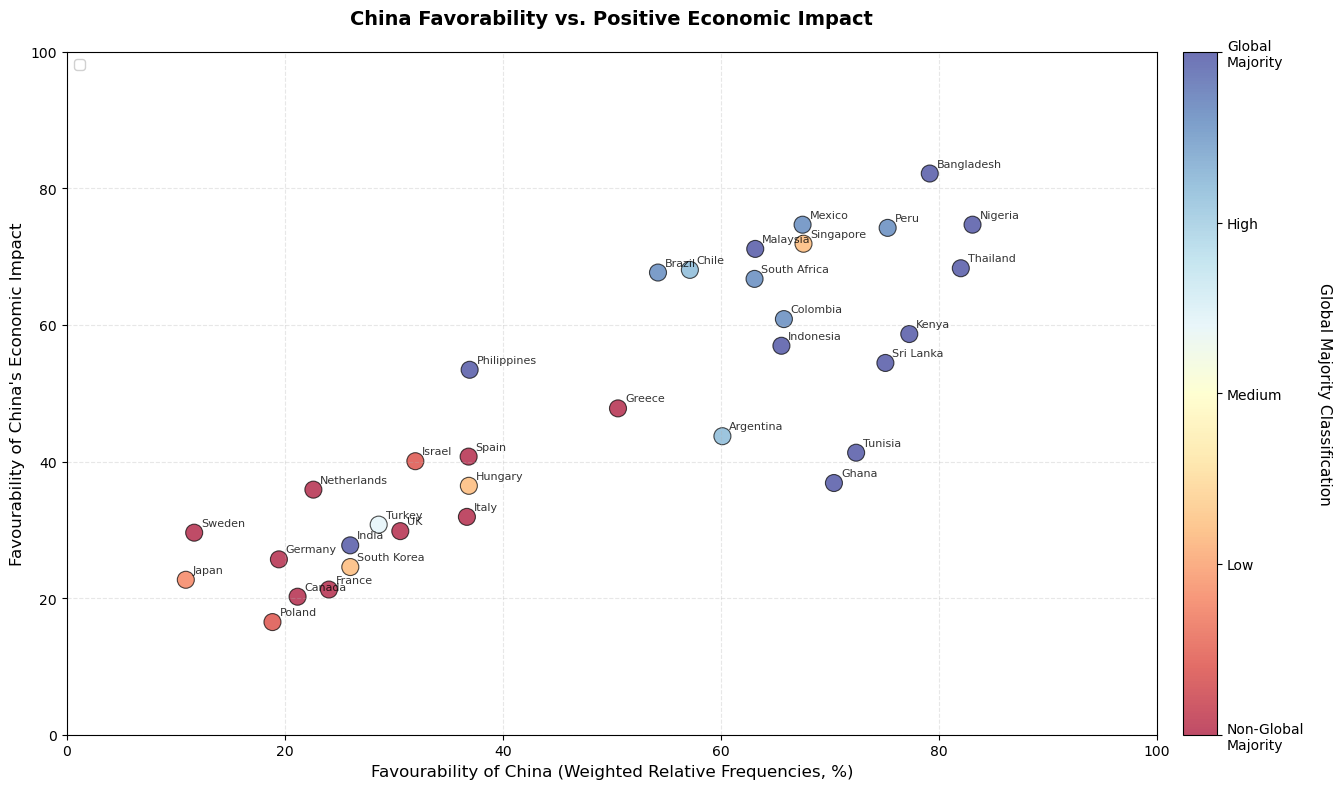

SUMMARY BY GLOBAL MAJORITY CLASSIFICATION

Global Majority Countries (n=18):
  Countries: Argentina, Bangladesh, Brazil, Chile, Colombia, Ghana, India, Indonesia, Kenya, Malaysia, Mexico, Nigeria, Peru, Philippines, South Africa, Sri Lanka, Thailand, Tunisia
  Mean China Favorability: 65.2%
  Mean Positive Economic Impact: 60.1%

Mixed/Transitional Countries (n=4):
  Countries: Hungary, Singapore, South Korea, Turkey
  Mean China Favorability: 39.8%
  Mean Positive Economic Impact: 40.9%

Non-Global Majority Countries (n=12):
  Countries: Canada, France, Germany, Greece, Israel, Italy, Japan, Netherlands, Poland, Spain, Sweden, UK
  Mean China Favorability: 26.3%
  Mean Positive Economic Impact: 30.2%


In [250]:
# Enhanced Scatterplot: fav_china vs china_influ_econ2 with Global Majority Gradient
# Color-coding each country by Global Majority classification

# Global Majority classification (1.0 = Global Majority, 0.0 = Non-Global Majority)
global_majority_scores = {
    # Global Majority countries (score = 0.8-1.0)
    'India': 1.0,
    'Indonesia': 1.0,
    'Bangladesh': 1.0,
    'Nigeria': 1.0,
    'Kenya': 1.0,
    'Ghana': 1.0,
    'Philippines': 1.0,
    'Thailand': 1.0,
    'Sri Lanka': 1.0,
    'Tunisia': 1.0,
    'Brazil': 0.9,
    'Mexico': 0.9,
    'Argentina': 0.8,
    'Chile': 0.8,
    'Colombia': 0.9,
    'Peru': 0.9,
    'South Africa': 0.9,
    'Malaysia': 1.0,
    'Singapore': 0.3,  # Developed but in Global South
    
    # Mixed/Transitional (score = 0.4-0.7)
    'Turkey': 0.6,
    'Hungary': 0.3,
    'South Korea': 0.3,
    'Japan': 0.2,
    
    # Non-Global Majority (score = 0.0-0.3)
    'United States': 0.0,
    'Canada': 0.0,
    'UK': 0.0,
    'France': 0.0,
    'Germany': 0.0,
    'Italy': 0.0,
    'Spain': 0.0,
    'Netherlands': 0.0,
    'Sweden': 0.0,
    'Greece': 0.0,
    'Australia': 0.0,
    'Israel': 0.1,
    'Poland': 0.1,
}

# Use the same data preparation as before
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['china_influ_econ2'].isin(['1', '2', '3'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'china_influ_econ2'])

country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    china_positive = country_data[country_data['china_influ_econ2'] == '1']['weight'].sum()
    china_positive_pct = (china_positive / total_weight) * 100
    
    # Get Global Majority score (default to 0.5 if not found)
    global_majority_score = global_majority_scores.get(country, 0.5)
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'china_positive_pct': china_positive_pct,
        'global_majority': global_majority_score
    }

plot_df = pd.DataFrame(country_stats).T

# Create scatterplot with gradient coloring
fig, ax = plt.subplots(figsize=(14, 8))

# Use colormap - reversed so Global Majority (1.0) is one color, Non-Global Majority (0.0) is another
scatter = ax.scatter(plot_df['fav_china_favorable_pct'], 
                     plot_df['china_positive_pct'], 
                     c=plot_df['global_majority'],
                     s=150, alpha=0.7, edgecolors='black', linewidth=0.8,
                     cmap='RdYlBu',  # Red (Non-Global Majority) to Blue (Global Majority)
                     vmin=0, vmax=1)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'fav_china_favorable_pct'], 
                 plot_df.loc[country, 'china_positive_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional)
# z = np.polyfit(plot_df['fav_china_favorable_pct'], 
#               plot_df['china_positive_pct'], 1)
# p = np.poly1d(z)
#ax.plot(plot_df['fav_china_favorable_pct'], 
#        p(plot_df['fav_china_favorable_pct']), 
#        "k--", alpha=0.4, linewidth=2, label='Trend line')

# Add colorbar on the right
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Global Majority Classification', fontsize=11, rotation=270, labelpad=20)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['Non-Global\nMajority', 'Low', 'Medium', 'High', 'Global\nMajority'])

ax.set_xlabel('Favourability of China (Weighted Relative Frequencies, %)', fontsize=12)
ax.set_ylabel('Favourability of China\'s Economic Impact', fontsize=12)
ax.set_title('China Favorability vs. Positive Economic Impact',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

# Print summary by Global Majority groups
print("="*70)
print("SUMMARY BY GLOBAL MAJORITY CLASSIFICATION")
print("="*70)

# Group countries
global_majority_countries = plot_df[plot_df['global_majority'] >= 0.7]
mixed_countries = plot_df[(plot_df['global_majority'] >= 0.3) & (plot_df['global_majority'] < 0.7)]
non_global_majority_countries = plot_df[plot_df['global_majority'] < 0.3]

for group_name, group_df in [('Global Majority', global_majority_countries), 
                               ('Mixed/Transitional', mixed_countries), 
                               ('Non-Global Majority', non_global_majority_countries)]:
    if len(group_df) > 0:
        print(f"\n{group_name} Countries (n={len(group_df)}):")
        print(f"  Countries: {', '.join(group_df.index.tolist())}")
        print(f"  Mean China Favorability: {group_df['fav_china_favorable_pct'].mean():.1f}%")
        print(f"  Mean Positive Economic Impact: {group_df['china_positive_pct'].mean():.1f}%")

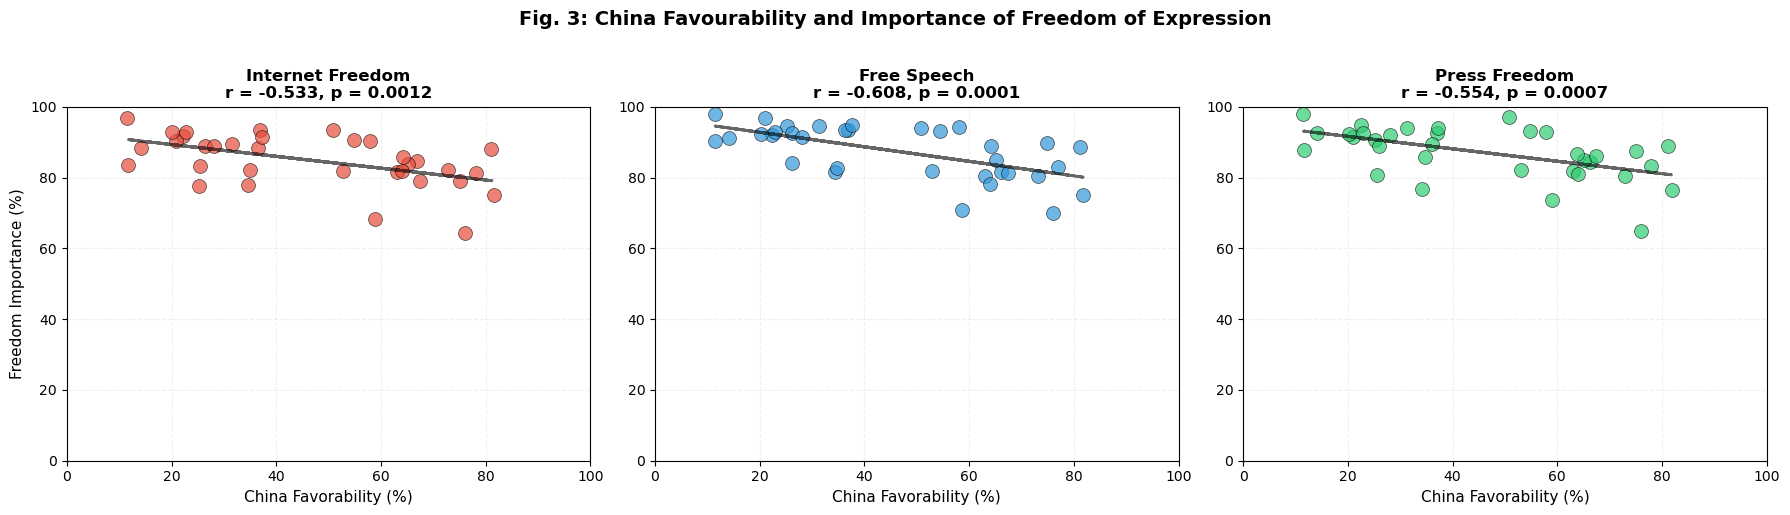

In [290]:
# Clean Combined Visualization: China Favorability vs All Three Freedom Variables
# Using subplots for clarity

# Reuse calculation function from before or recalculate
def calc_china_freedom_correlation(freedom_var):
    valid_data = pew[
        pew['fav_china'].isin(['1', '2', '3', '4']) & 
        pew[freedom_var].isin(['1', '2', '3', '4'])
    ].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', freedom_var])
    
    country_stats = {}
    for country in sorted(valid_data['country_name'].unique()):
        country_data = valid_data[valid_data['country_name'] == country]
        total_weight = country_data['weight'].sum()
        
        fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
        fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
        
        freedom_important = country_data[country_data[freedom_var].isin(['1', '2'])]['weight'].sum()
        freedom_important_pct = (freedom_important / total_weight) * 100
        
        country_stats[country] = {
            'fav_china_favorable_pct': fav_china_favorable_pct,
            'freedom_important_pct': freedom_important_pct
        }
    
    return pd.DataFrame(country_stats).T

plot_df_internet = calc_china_freedom_correlation('internet_freedom')
plot_df_speech = calc_china_freedom_correlation('free_speech')
plot_df_press = calc_china_freedom_correlation('press_freedom')

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

from scipy import stats
from scipy.stats import spearmanr

# Define colors for each
colors = ['#e74c3c', '#3498db', '#2ecc71']
datasets = [
    (plot_df_internet, 'Internet Freedom', 'internet_freedom'),
    (plot_df_speech, 'Free Speech', 'free_speech'),
    (plot_df_press, 'Press Freedom', 'press_freedom')
]

for idx, (plot_df, title, var_name) in enumerate(datasets):
    ax = axes[idx]
    
    # Scatter plot
    ax.scatter(plot_df['fav_china_favorable_pct'], 
               plot_df['freedom_important_pct'], 
               s=100, alpha=0.7, color=colors[idx], edgecolors='black', linewidth=0.5)
    
    # Trend line
    z = np.polyfit(plot_df['fav_china_favorable_pct'], 
                   plot_df['freedom_important_pct'], 1)
    p = np.poly1d(z)
    ax.plot(plot_df['fav_china_favorable_pct'], 
            p(plot_df['fav_china_favorable_pct']), 
            color='black', linestyle='--', alpha=0.6, linewidth=2)
    
    # Calculate correlation
    corr, p_val = spearmanr(plot_df['fav_china_favorable_pct'], 
                            plot_df['freedom_important_pct'])
    
    # Customize
    ax.set_xlabel('China Favorability (%)', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Freedom Importance (%)', fontsize=11)
    ax.set_title(f'{title}\nr = {corr:.3f}, p = {p_val:.4f}', 
                 fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.2, linestyle='--')
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)

plt.suptitle('Fig. 3: China Favourability and Importance of Freedom of Expression', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

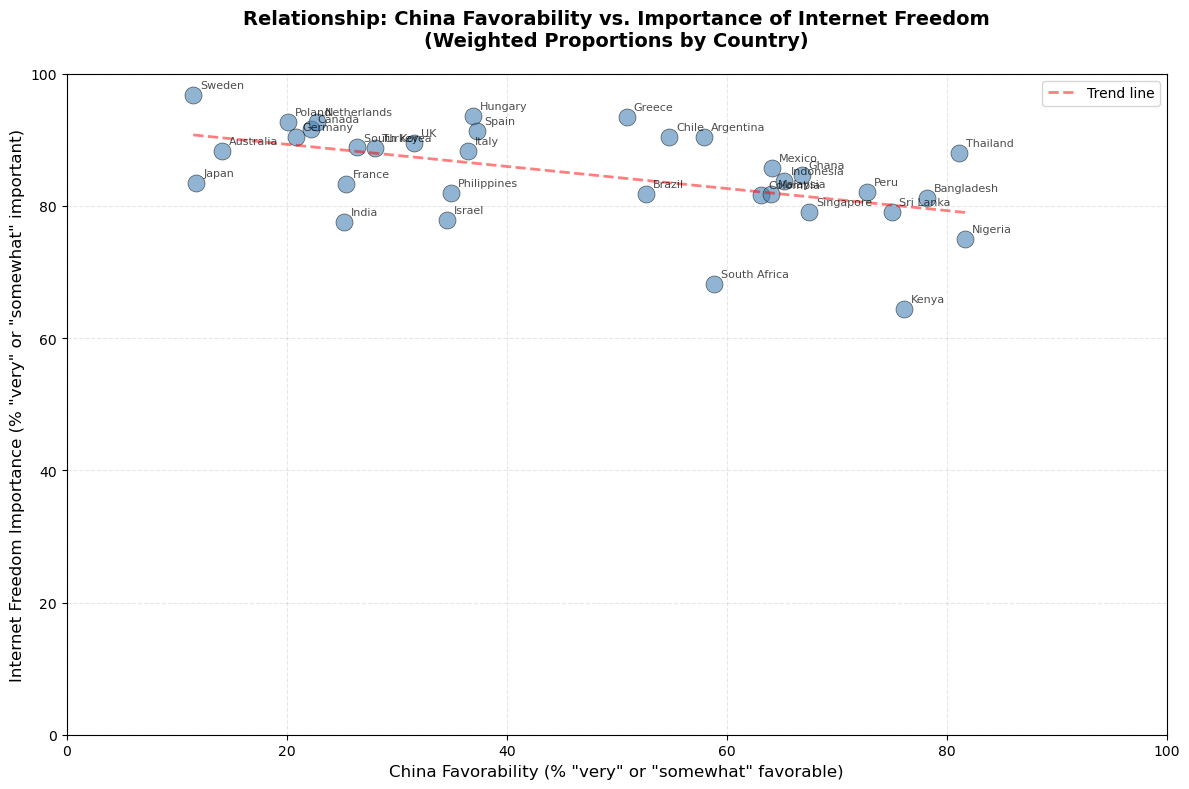

Summary Statistics (Weighted Proportions):

Number of countries: 34

China Favorability (% favorable):
  Mean: 46.2%
  Range: 11.5% - 81.7%

Internet Freedom Importance (% saying it's important):
  Mean: 84.9%
  Range: 64.4% - 96.8%

Spearman Correlation: -0.533 (p-value: 0.0012)
  Statistically significant correlation!


In [67]:
# Scatterplot to visualize the correlation between fav_china and internet_freedom
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df_china['fav_china_favorable_pct'], 
           plot_df_china['internet_freedom_important_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df_china.index:
    ax.annotate(country, 
                (plot_df_china.loc[country, 'fav_china_favorable_pct'], 
                 plot_df_china.loc[country, 'internet_freedom_important_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional - helps visualize correlation)
from scipy import stats
z = np.polyfit(plot_df_china['fav_china_favorable_pct'], 
               plot_df_china['internet_freedom_important_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df_china['fav_china_favorable_pct'], 
        p(plot_df_china['fav_china_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('China Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Internet Freedom Importance (% "very" or "somewhat" important)', fontsize=12)
ax.set_title('Relationship: China Favorability vs. Importance of Internet Freedom\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df_china)}")
print(f"\nChina Favorability (% favorable):")
print(f"  Mean: {plot_df_china['fav_china_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df_china['fav_china_favorable_pct'].min():.1f}% - {plot_df_china['fav_china_favorable_pct'].max():.1f}%")
print(f"\nInternet Freedom Importance (% saying it's important):")
print(f"  Mean: {plot_df_china['internet_freedom_important_pct'].mean():.1f}%")
print(f"  Range: {plot_df_china['internet_freedom_important_pct'].min():.1f}% - {plot_df_china['internet_freedom_important_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df_china['fav_china_favorable_pct'], plot_df_china['internet_freedom_important_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

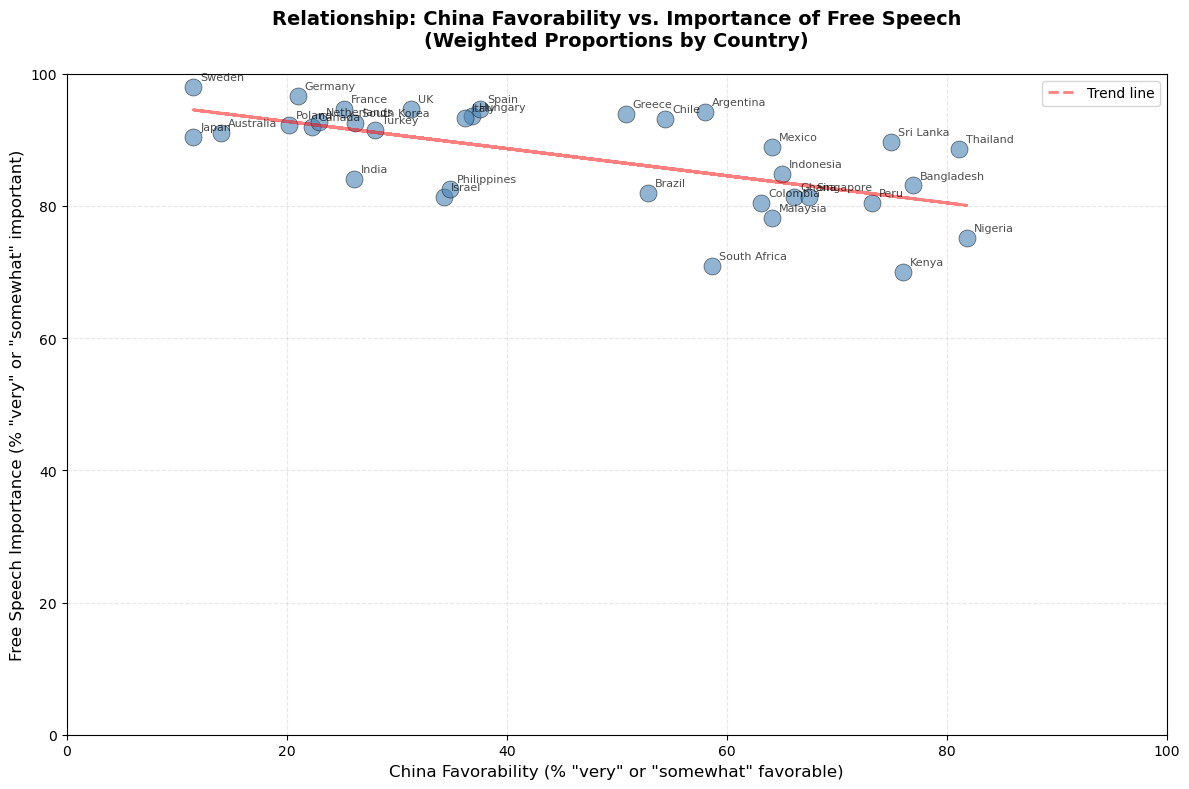

Summary Statistics (Weighted Proportions):

Number of countries: 34

China Favorability (% favorable):
  Mean: 46.1%
  Range: 11.5% - 81.8%

Free Speech Importance (% saying it's important):
  Mean: 87.4%
  Range: 70.0% - 98.1%

Spearman Correlation: -0.608 (p-value: 0.0001)
  Statistically significant correlation!


In [44]:
# Scatterplot: fav_china vs free_speech (importance)
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['free_speech'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'free_speech'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_china: % who are favorable (1 or 2: very/somewhat favorable)
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    # For free_speech: % who say it's "very important" or "somewhat important" (1 or 2)
    free_speech_important = country_data[country_data['free_speech'].isin(['1', '2'])]['weight'].sum()
    free_speech_important_pct = (free_speech_important / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'free_speech_important_pct': free_speech_important_pct
    }

# Convert to DataFrame for easier plotting
plot_df_speech = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df_speech['fav_china_favorable_pct'], 
           plot_df_speech['free_speech_important_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df_speech.index:
    ax.annotate(country, 
                (plot_df_speech.loc[country, 'fav_china_favorable_pct'], 
                 plot_df_speech.loc[country, 'free_speech_important_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional - helps visualize correlation)
from scipy import stats
z = np.polyfit(plot_df_speech['fav_china_favorable_pct'], 
               plot_df_speech['free_speech_important_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df_speech['fav_china_favorable_pct'], 
        p(plot_df_speech['fav_china_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('China Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Free Speech Importance (% "very" or "somewhat" important)', fontsize=12)
ax.set_title('Relationship: China Favorability vs. Importance of Free Speech\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df_speech)}")
print(f"\nChina Favorability (% favorable):")
print(f"  Mean: {plot_df_speech['fav_china_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df_speech['fav_china_favorable_pct'].min():.1f}% - {plot_df_speech['fav_china_favorable_pct'].max():.1f}%")
print(f"\nFree Speech Importance (% saying it's important):")
print(f"  Mean: {plot_df_speech['free_speech_important_pct'].mean():.1f}%")
print(f"  Range: {plot_df_speech['free_speech_important_pct'].min():.1f}% - {plot_df_speech['free_speech_important_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df_speech['fav_china_favorable_pct'], 
                                 plot_df_speech['free_speech_important_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

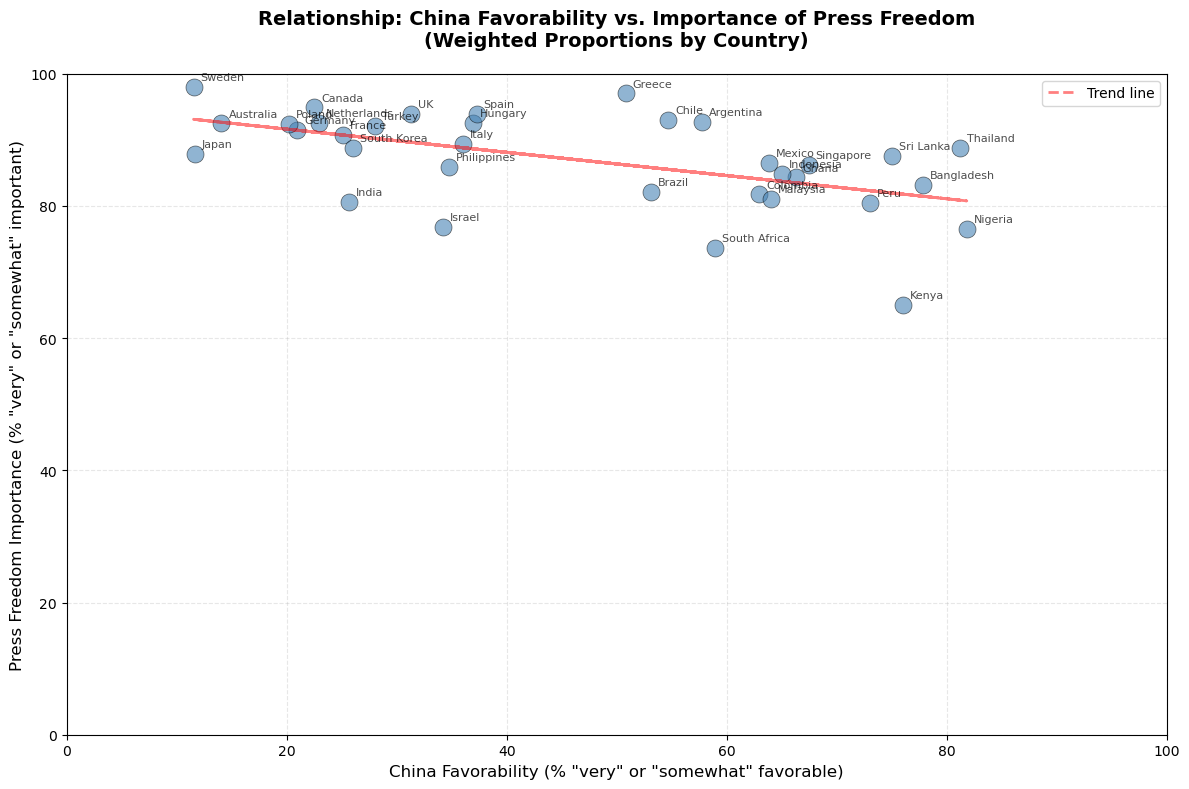

Summary Statistics (Weighted Proportions):

Number of countries: 34

China Favorability (% favorable):
  Mean: 46.1%
  Range: 11.5% - 81.8%

Press Freedom Importance (% saying it's important):
  Mean: 87.0%
  Range: 65.0% - 98.0%

Spearman Correlation: -0.554 (p-value: 0.0007)
  Statistically significant correlation!


In [45]:
# Scatterplot: fav_china vs press_freedom (importance)
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['press_freedom'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'press_freedom'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_china: % who are favorable (1 or 2: very/somewhat favorable)
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    # For press_freedom: % who say it's "very important" or "somewhat important" (1 or 2)
    press_freedom_important = country_data[country_data['press_freedom'].isin(['1', '2'])]['weight'].sum()
    press_freedom_important_pct = (press_freedom_important / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'press_freedom_important_pct': press_freedom_important_pct
    }

# Convert to DataFrame for easier plotting
plot_df_press = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df_press['fav_china_favorable_pct'], 
           plot_df_press['press_freedom_important_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df_press.index:
    ax.annotate(country, 
                (plot_df_press.loc[country, 'fav_china_favorable_pct'], 
                 plot_df_press.loc[country, 'press_freedom_important_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional - helps visualize correlation)
from scipy import stats
z = np.polyfit(plot_df_press['fav_china_favorable_pct'], 
               plot_df_press['press_freedom_important_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df_press['fav_china_favorable_pct'], 
        p(plot_df_press['fav_china_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('China Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Press Freedom Importance (% "very" or "somewhat" important)', fontsize=12)
ax.set_title('Relationship: China Favorability vs. Importance of Press Freedom\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df_press)}")
print(f"\nChina Favorability (% favorable):")
print(f"  Mean: {plot_df_press['fav_china_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df_press['fav_china_favorable_pct'].min():.1f}% - {plot_df_press['fav_china_favorable_pct'].max():.1f}%")
print(f"\nPress Freedom Importance (% saying it's important):")
print(f"  Mean: {plot_df_press['press_freedom_important_pct'].mean():.1f}%")
print(f"  Range: {plot_df_press['press_freedom_important_pct'].min():.1f}% - {plot_df_press['press_freedom_important_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df_press['fav_china_favorable_pct'], 
                                 plot_df_press['press_freedom_important_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

/Users/teoboy/anaconda3/lib/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning:

facecolor will have no effect as it has been defined as "never".



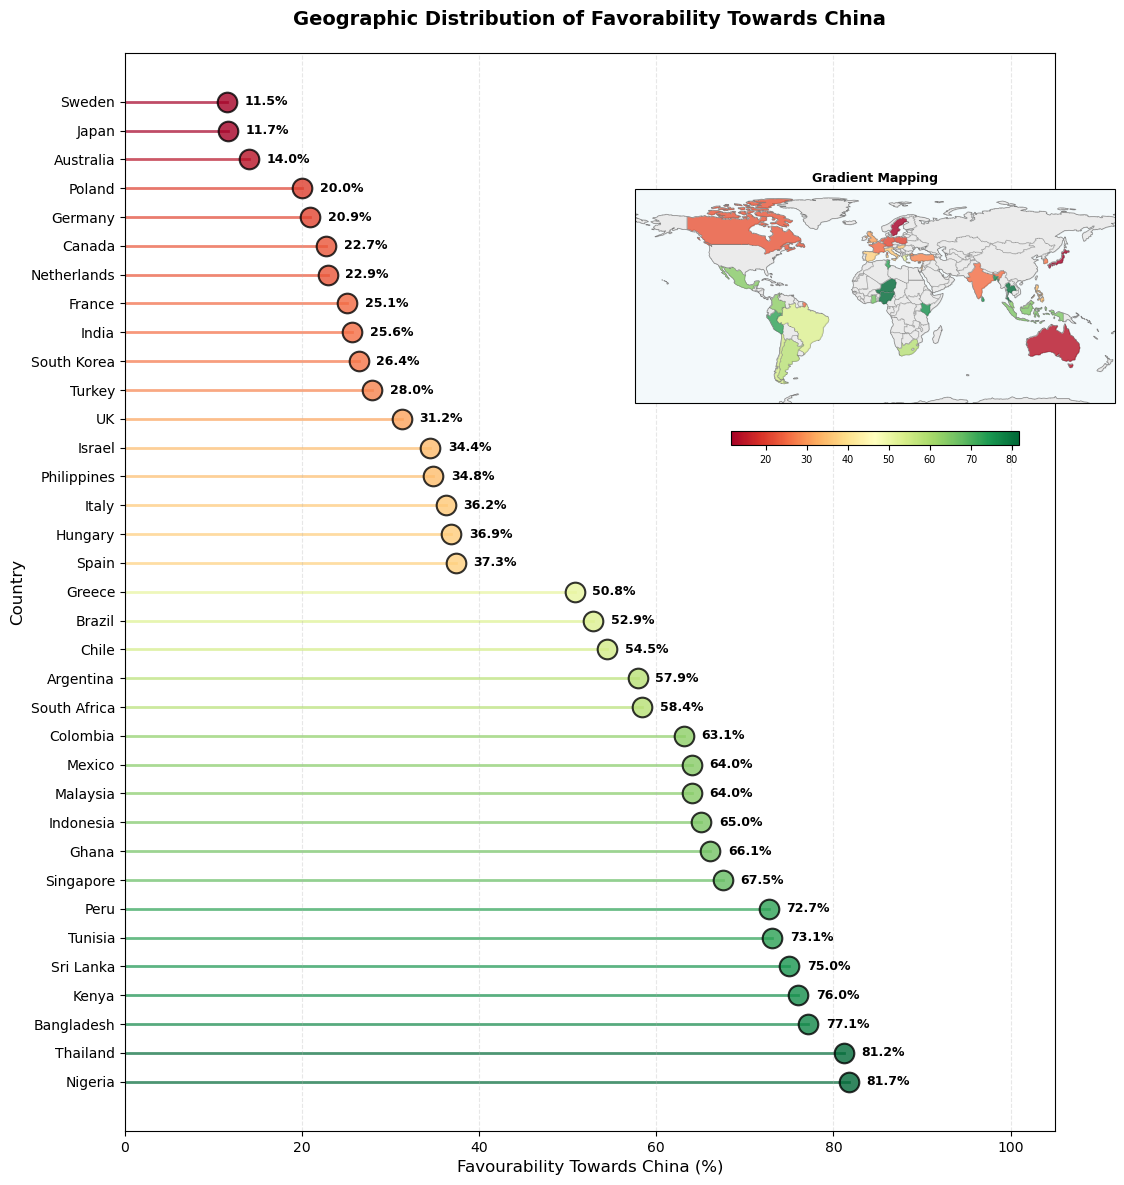

In [267]:
# Lollipop Chart: China Favorability by Country
# Color-coded by Favorability Gradient with choropleth world map inset

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader
import matplotlib.colors as mcolors

# Filter to valid responses
valid_data = pew[pew['fav_china'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Sort by China favorability for better visualization
plot_df = plot_df.sort_values('fav_china_favorable_pct', ascending=True)

# Create colormap for favorability gradient (low to high)
# Using RdYlGn (Red-Yellow-Green) reversed so red = low favorability, green = high
cmap = plt.cm.RdYlGn  # Reversed: Red (low) -> Yellow -> Green (high)
norm = mcolors.Normalize(vmin=plot_df['fav_china_favorable_pct'].min(), 
                        vmax=plot_df['fav_china_favorable_pct'].max())

# Create lollipop chart with favorability gradient coloring
fig, ax = plt.subplots(figsize=(12, max(10, len(plot_df) * 0.4)))

y_pos = np.arange(len(plot_df))

# Plot lollipop with favorability gradient colors
for i, country in enumerate(plot_df.index):
    china_val = plot_df.loc[country, 'fav_china_favorable_pct']
    color = cmap(norm(china_val))  # Get color from gradient based on favorability
    
    # Draw line
    ax.plot([0, china_val], [i, i], color=color, linewidth=2, alpha=0.7, zorder=1)
    
    # Draw dot with gradient color
    ax.scatter(china_val, i, s=200, color=color, alpha=0.8, edgecolors='black', linewidth=1.5, zorder=3)
    
    # Add percentage text to the right of the dot
    ax.text(china_val + 2, i, f'{china_val:.1f}%', 
            va='center', fontsize=9, fontweight='bold', zorder=4)

# Create mini world map inset with favorability gradient choropleth
ax_map = fig.add_axes([0.55, 0.55, 0.40, 0.40], projection=ccrs.PlateCarree())

# Add base geographic features
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5, color='gray')
ax_map.add_feature(cfeature.BORDERS, linewidth=0.3, color='gray')
ax_map.add_feature(cfeature.OCEAN, facecolor='#E8F4F8', alpha=0.5)
ax_map.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.2)

# Country name mapping (Pew dataset names to Natural Earth names)
ne_to_pew = {
    'United Kingdom of Great Britain and Northern Ireland': 'UK',
    'United Kingdom': 'UK',
    'United States of America': 'United States',
    'Republic of Korea': 'South Korea',
}

# Get Natural Earth country boundaries and color by favorability
try:
    shpfilename = shapereader.natural_earth(resolution='110m', category='cultural', name='admin_0_countries')
    reader = shapereader.Reader(shpfilename)
    
    # Color countries by favorability
    for country_record in reader.records():
        country_name_ne = country_record.attributes['NAME']
        geometry = country_record.geometry
        
        # Try to match country name
        matched_country = None
        for pew_country in plot_df.index:
            # Direct match
            if country_name_ne == pew_country:
                matched_country = pew_country
                break
            # Check mapping
            if country_name_ne in ne_to_pew:
                if ne_to_pew[country_name_ne] == pew_country:
                    matched_country = pew_country
                    break
            # Partial match
            if pew_country in country_name_ne or country_name_ne in pew_country:
                matched_country = pew_country
                break
        
        if matched_country and matched_country in plot_df.index:
            favorability = plot_df.loc[matched_country, 'fav_china_favorable_pct']
            color = cmap(norm(favorability))  # Get color from gradient
            ax_map.add_geometries([geometry], ccrs.PlateCarree(),
                                 facecolor=color, edgecolor='gray', 
                                 linewidth=0.3, alpha=0.8, zorder=2)
        else:
            # Unmatched countries in light gray
            ax_map.add_geometries([geometry], ccrs.PlateCarree(),
                                 facecolor='#D3D3D3', edgecolor='gray', 
                                 linewidth=0.2, alpha=0.3, zorder=1)
    
except Exception as e:
    print(f"Note: Could not load Natural Earth shapefiles. Using fallback method. Error: {e}")
    # Fallback: Use country centroids with gradient-colored markers
    country_coords = {
        'UK': (0, 54), 'France': (2, 46), 'Germany': (10, 51), 'Italy': (12, 42),
        'Spain': (-3, 40), 'Poland': (20, 52), 'Netherlands': (5, 52), 'Sweden': (18, 60),
        'Greece': (23, 39), 'Hungary': (20, 47),
        'Canada': (-95, 56), 'United States': (-95, 38),
        'Japan': (138, 36), 'South Korea': (127, 36), 'India': (77, 20), 'Indonesia': (120, -5),
        'Malaysia': (102, 4), 'Philippines': (121, 13), 'Singapore': (104, 1), 'Thailand': (101, 15),
        'Bangladesh': (90, 24), 'Sri Lanka': (81, 7),
        'Israel': (35, 31), 'Tunisia': (10, 34), 'Turkey': (35, 39),
        'South Africa': (25, -29), 'Ghana': (-1, 8), 'Kenya': (38, 0), 'Nigeria': (8, 9),
        'Brazil': (-55, -15), 'Argentina': (-64, -34), 'Chile': (-71, -33), 'Colombia': (-74, 4),
        'Peru': (-75, -10), 'Mexico': (-102, 23),
        'Australia': (133, -25)
    }
    
    for country in plot_df.index:
        if country in country_coords:
            lon, lat = country_coords[country]
            favorability = plot_df.loc[country, 'fav_china_favorable_pct']
            color = cmap(norm(favorability))  # Get color from gradient
            ax_map.scatter(lon, lat, s=500, c=[favorability], cmap=cmap, 
                          vmin=norm.vmin, vmax=norm.vmax, alpha=0.9, 
                          edgecolors='black', linewidth=1.5, zorder=5, 
                          transform=ccrs.PlateCarree())

# Add colorbar for favorability gradient
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax_map, orientation='horizontal', 
                   pad=0.05, shrink=0.6, aspect=20)
cbar.ax.tick_params(labelsize=7)

# Set map bounds
ax_map.set_global()
ax_map.set_extent([-180, 180, -70, 90], crs=ccrs.PlateCarree())
ax_map.set_title('Gradient Mapping', fontsize=9, fontweight='bold', pad=5)

# Main plot settings
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xlabel('Favourability Towards China (%)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('Geographic Distribution of Favorability Towards China',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 105)  # Extended slightly to accommodate percentage text
ax.set_xticks(np.arange(0, 101, 20))
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()  # Top to bottom

plt.show()

/Users/teoboy/anaconda3/lib/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning:

facecolor will have no effect as it has been defined as "never".



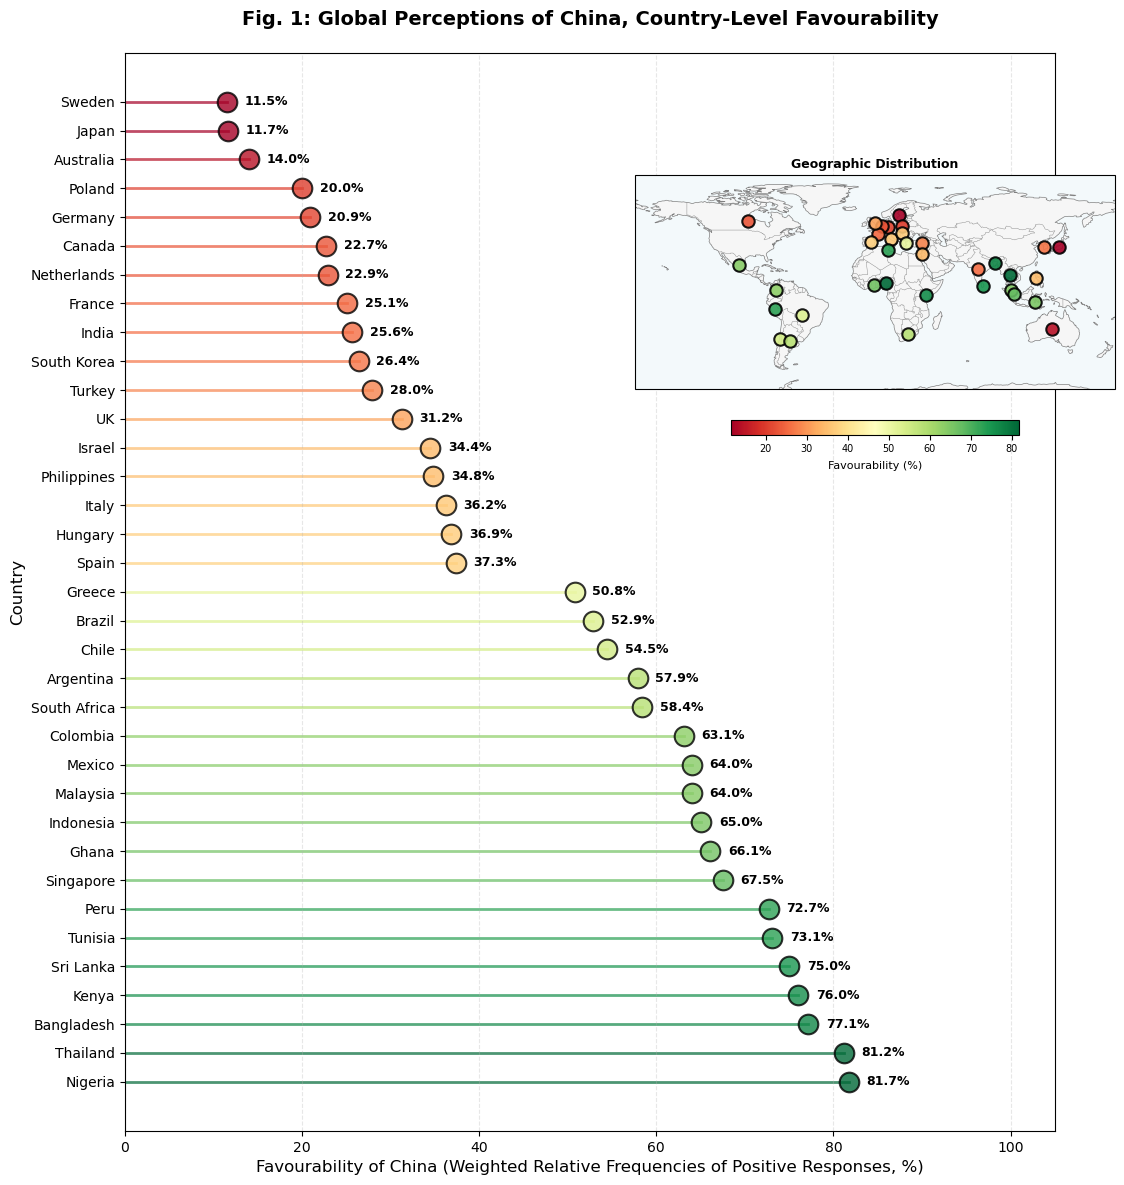

In [269]:
# Lollipop Chart: China Favorability by Country
# Color-coded by Favorability Gradient with gradient dots on world map inset

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors

# Filter to valid responses
valid_data = pew[pew['fav_china'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Sort by China favorability for better visualization
plot_df = plot_df.sort_values('fav_china_favorable_pct', ascending=True)

# Create colormap for favorability gradient (low to high)
# Using RdYlGn: Red (low favorability) -> Yellow -> Green (high favorability)
cmap = plt.cm.RdYlGn  # Red to Green
norm = mcolors.Normalize(vmin=plot_df['fav_china_favorable_pct'].min(), 
                        vmax=plot_df['fav_china_favorable_pct'].max())

# Create lollipop chart with favorability gradient coloring
fig, ax = plt.subplots(figsize=(12, max(10, len(plot_df) * 0.4)))

y_pos = np.arange(len(plot_df))

# Plot lollipop with favorability gradient colors
for i, country in enumerate(plot_df.index):
    china_val = plot_df.loc[country, 'fav_china_favorable_pct']
    color = cmap(norm(china_val))  # Get color from gradient based on favorability
    
    # Draw line
    ax.plot([0, china_val], [i, i], color=color, linewidth=2, alpha=0.7, zorder=1)
    
    # Draw dot with gradient color
    ax.scatter(china_val, i, s=200, color=color, alpha=0.8, edgecolors='black', linewidth=1.5, zorder=3)
    
    # Add percentage text to the right of the dot
    ax.text(china_val + 2, i, f'{china_val:.1f}%', 
            va='center', fontsize=9, fontweight='bold', zorder=4)

# Create mini world map inset with favorability gradient dots
ax_map = fig.add_axes([0.55, 0.55, 0.40, 0.45], projection=ccrs.PlateCarree())

# Add base geographic features
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5, color='gray')
ax_map.add_feature(cfeature.BORDERS, linewidth=0.3, color='gray')
ax_map.add_feature(cfeature.OCEAN, facecolor='#E8F4F8', alpha=0.5)
ax_map.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.2)

# Country coordinates for map (approximate centroids)
country_coords = {
    'UK': (0, 54), 'France': (2, 46), 'Germany': (10, 51), 'Italy': (12, 42),
    'Spain': (-3, 40), 'Poland': (20, 52), 'Netherlands': (5, 52), 'Sweden': (18, 60),
    'Greece': (23, 39), 'Hungary': (20, 47),
    'Canada': (-95, 56), 'United States': (-95, 38),
    'Japan': (138, 36), 'South Korea': (127, 36), 'India': (77, 20), 'Indonesia': (120, -5),
    'Malaysia': (102, 4), 'Philippines': (121, 13), 'Singapore': (104, 1), 'Thailand': (101, 15),
    'Bangladesh': (90, 24), 'Sri Lanka': (81, 7),
    'Israel': (35, 31), 'Tunisia': (10, 34), 'Turkey': (35, 39),
    'South Africa': (25, -29), 'Ghana': (-1, 8), 'Kenya': (38, 0), 'Nigeria': (8, 9),
    'Brazil': (-55, -15), 'Argentina': (-64, -34), 'Chile': (-71, -33), 'Colombia': (-74, 4),
    'Peru': (-75, -10), 'Mexico': (-102, 23),
    'Australia': (133, -25)
}

# Plot countries as dots with favorability gradient colors
for country in plot_df.index:
    if country in country_coords:
        lon, lat = country_coords[country]
        favorability = plot_df.loc[country, 'fav_china_favorable_pct']
        color = cmap(norm(favorability))  # Get color from gradient
        
        ax_map.scatter(lon, lat, s=80, c=[favorability], cmap=cmap, 
                      vmin=norm.vmin, vmax=norm.vmax, alpha=0.9, 
                      edgecolors='black', linewidth=1.5, zorder=5, 
                      transform=ccrs.PlateCarree())

# Add colorbar for favorability gradient
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax_map, orientation='horizontal', 
                   pad=0.05, shrink=0.6, aspect=20)
cbar.set_label('Favourability (%)', fontsize=8, labelpad=5)
cbar.ax.tick_params(labelsize=7)

# Set map bounds
ax_map.set_global()
ax_map.set_extent([-180, 180, -70, 90], crs=ccrs.PlateCarree())
ax_map.set_title('Geographic Distribution', fontsize=9, fontweight='bold', pad=5)

# Main plot settings
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xlabel('Favourability of China (Weighted Relative Frequencies of Positive Responses, %)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('Fig. 1: Global Perceptions of China, Country-Level Favourability',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 105)  # Extended slightly to accommodate percentage text
ax.set_xticks(np.arange(0, 101, 20))
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()  # Top to bottom

plt.show()

# Less Valuable Statistics

In [32]:
# 3. Analysis

## 3.1 China Favorability Across Countries

# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['fav_china'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('fav_china')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    # Convert Series to dict, handling missing values
    country_proportions[country] = {
        '1': proportions.get('1', 0) if '1' in proportions.index else 0,  # Very favorable
        '2': proportions.get('2', 0) if '2' in proportions.index else 0,  # Somewhat favorable
        '3': proportions.get('3', 0) if '3' in proportions.index else 0,  # Somewhat unfavorable
        '4': proportions.get('4', 0) if '4' in proportions.index else 0   # Very unfavorable
    }

# Create a summary: % favorable (1 or 2) vs unfavorable (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    favorable_percent = props['1'] + props['2']  # Very + Somewhat favorable
    unfavorable_percent = props['3'] + props['4']  # Somewhat + Very unfavorable
    summary_stats[country] = {
        'Very Favorable': props['1'],
        'Somewhat Favorable': props['2'],
        'Somewhat Unfavorable': props['3'],
        'Very Unfavorable': props['4'],
        'Total Favorable': favorable_percent,
        'Total Unfavorable': unfavorable_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Total Favorable', ascending=False)

print("China Favorability by Country (Weighted Proportions)")
print("=" * 90)
print(summary_df.round(1))



China Favorability by Country (Weighted Proportions)
              Very Favorable  Somewhat Favorable  Somewhat Unfavorable  \
Nigeria                 41.9                39.8                   8.2   
Thailand                21.9                59.3                  15.2   
Bangladesh              33.4                43.7                  11.3   
Kenya                   29.3                46.7                  12.4   
Sri Lanka               25.1                49.8                  12.5   
Tunisia                 22.7                50.3                  12.9   
Peru                    29.2                43.5                  14.3   
Singapore               14.7                52.8                  24.5   
Ghana                   36.5                29.6                  11.0   
Indonesia               13.4                51.6                  30.1   
Malaysia                15.8                48.2                  27.8   
Mexico                  16.2                47.8           

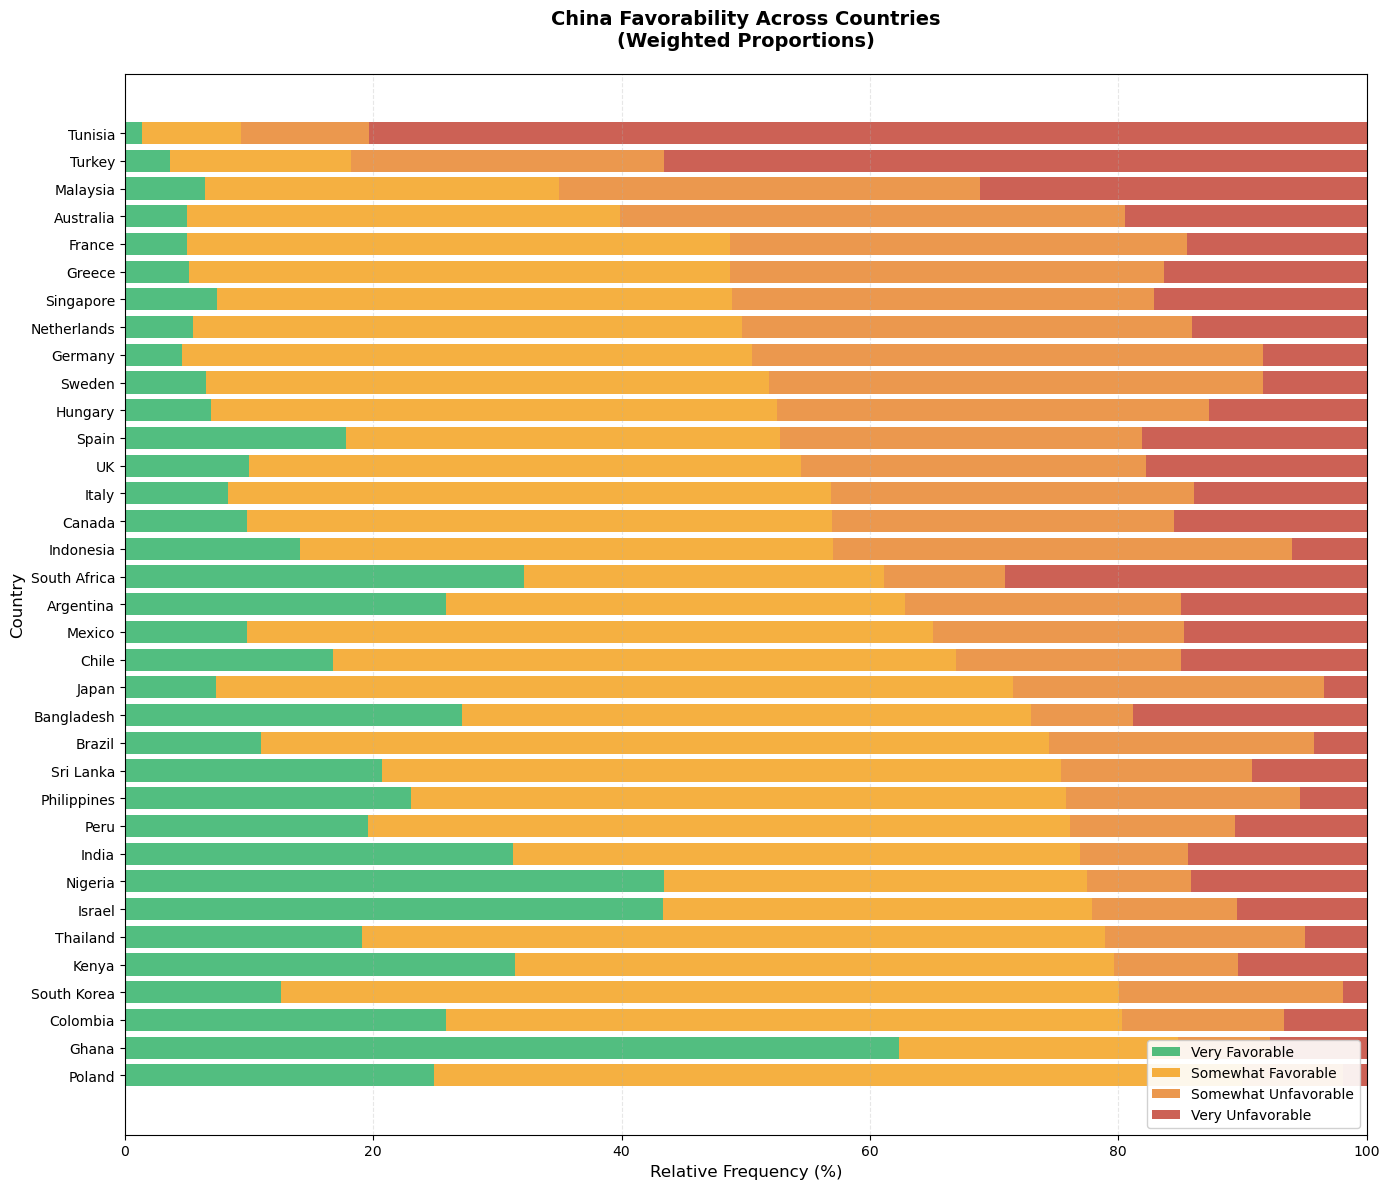

In [107]:
# Graph: China Favorability Across Countries
# Create a stacked horizontal bar chart

fig, ax = plt.subplots(figsize=(14, 12))

# Prepare data for stacked bar chart
countries = summary_df.index
categories = ['Very Favorable', 'Somewhat Favorable', 'Somewhat Unfavorable', 'Very Unfavorable']
colors = ['#27ae60', '#f39c12', '#e67e22', '#c0392b']  # Green to red gradient

# Create stacked bars
bottom = np.zeros(len(countries))
for category, color in zip(categories, colors):
    values = summary_df[category].values
    ax.barh(countries, values, left=bottom, label=category, color=color, alpha=0.8)
    bottom += values

ax.set_xlabel('Relative Frequency (%)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('China Favorability Across Countries\n(Weighted Proportions)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='lower right', framealpha=0.9)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()


US Favorability by Country (Weighted Proportions)
              Very Favorable  Somewhat Favorable  Somewhat Unfavorable  \
Poland                  24.9                65.0                   8.2   
Ghana                   62.4                22.4                   7.4   
Colombia                25.9                54.4                  13.1   
South Korea             12.5                67.5                  18.0   
Kenya                   31.4                48.2                  10.0   
Thailand                19.1                59.8                  16.2   
Israel                  43.3                34.6                  11.7   
Nigeria                 43.4                34.1                   8.4   
India                   31.3                45.6                   8.7   
Peru                    19.6                56.5                  13.3   
Philippines             23.0                52.7                  18.9   
Sri Lanka               20.7                54.7              

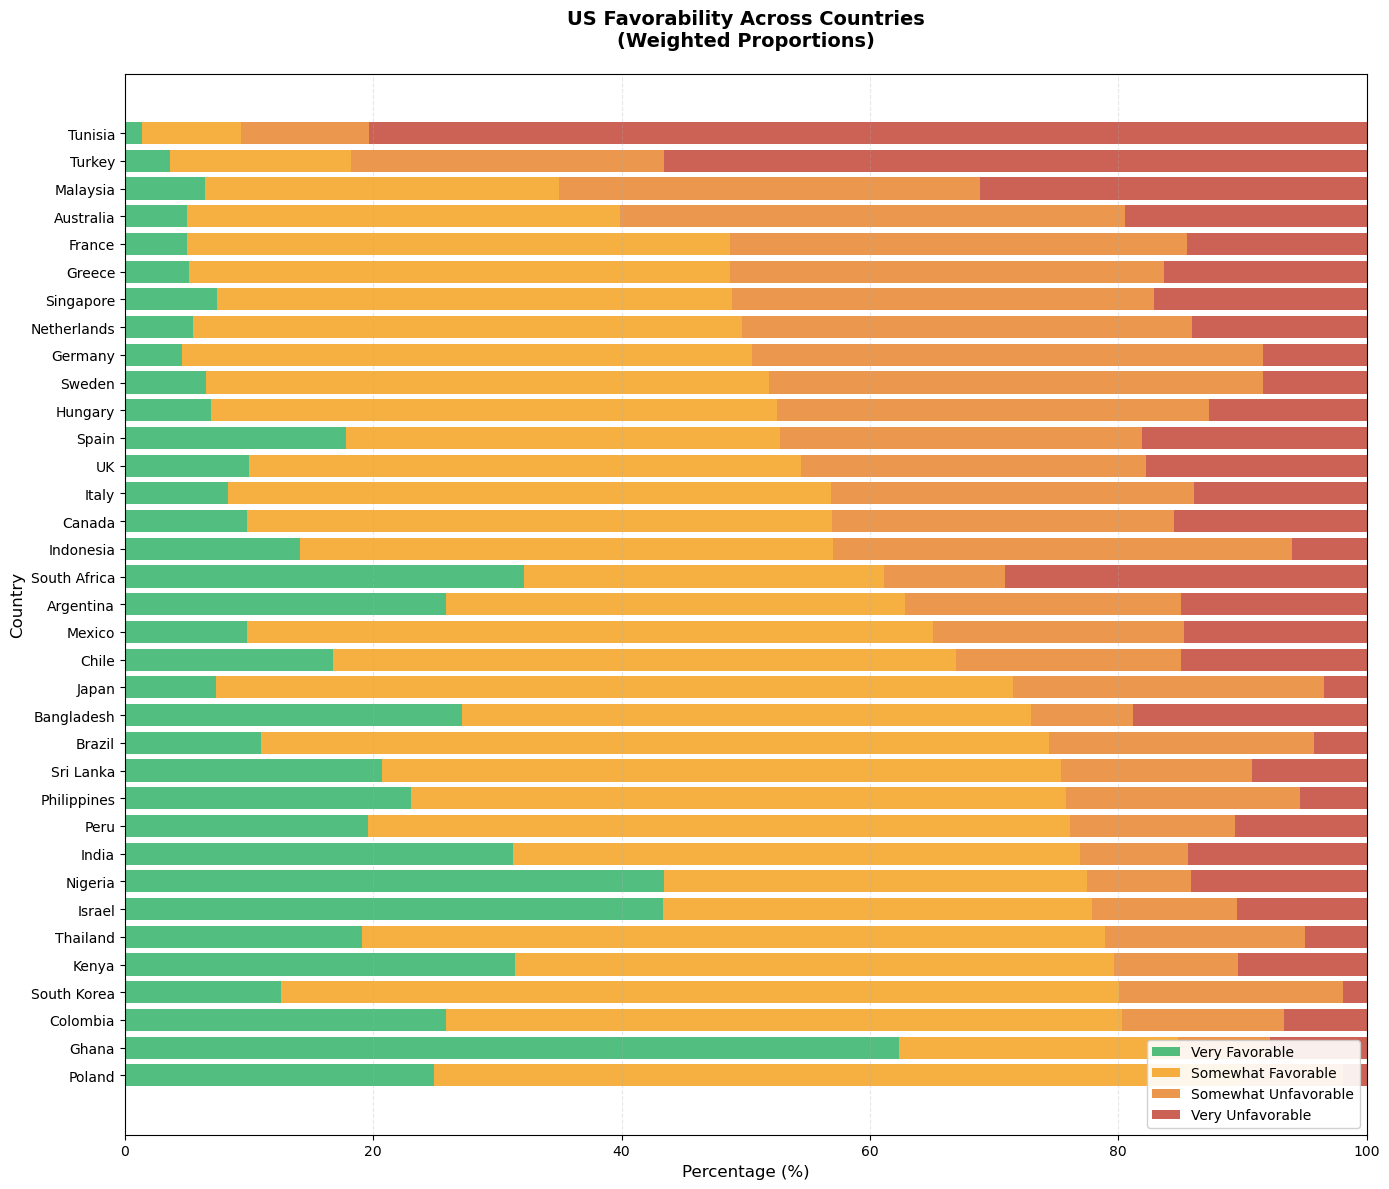

In [34]:
# Graph: China Favorability Across Countries
# Create a stacked horizontal bar chart

# 3. Analysis

## 3.1 China Favorability Across Countries

# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['fav_us'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_us'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('fav_us')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    # Convert Series to dict, handling missing values
    country_proportions[country] = {
        '1': proportions.get('1', 0) if '1' in proportions.index else 0,  # Very favorable
        '2': proportions.get('2', 0) if '2' in proportions.index else 0,  # Somewhat favorable
        '3': proportions.get('3', 0) if '3' in proportions.index else 0,  # Somewhat unfavorable
        '4': proportions.get('4', 0) if '4' in proportions.index else 0   # Very unfavorable
    }

# Create a summary: % favorable (1 or 2) vs unfavorable (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    favorable_percent = props['1'] + props['2']  # Very + Somewhat favorable
    unfavorable_percent = props['3'] + props['4']  # Somewhat + Very unfavorable
    summary_stats[country] = {
        'Very Favorable': props['1'],
        'Somewhat Favorable': props['2'],
        'Somewhat Unfavorable': props['3'],
        'Very Unfavorable': props['4'],
        'Total Favorable': favorable_percent,
        'Total Unfavorable': unfavorable_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Total Favorable', ascending=False)

print("US Favorability by Country (Weighted Proportions)")
print("=" * 90)
print(summary_df.round(1))

fig, ax = plt.subplots(figsize=(14, 12))

# Prepare data for stacked bar chart
countries = summary_df.index
categories = ['Very Favorable', 'Somewhat Favorable', 'Somewhat Unfavorable', 'Very Unfavorable']
colors = ['#27ae60', '#f39c12', '#e67e22', '#c0392b']  # Green to red gradient

# Create stacked bars
bottom = np.zeros(len(countries))
for category, color in zip(categories, colors):
    values = summary_df[category].values
    ax.barh(countries, values, left=bottom, label=category, color=color, alpha=0.8)
    bottom += values

ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('US Favorability Across Countries\n(Weighted Proportions)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='lower right', framealpha=0.9)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

UK Favorability by Country (Weighted Proportions)
              Very Favorable  Somewhat Favorable  Somewhat Unfavorable  \
Thailand                16.5                66.1                  13.1   
South Korea              6.3                75.4                  16.0   
Kenya                   27.0                53.4                  11.3   
Ghana                   48.3                30.9                  11.5   
Poland                  31.1                47.5                  15.7   
Sri Lanka               19.7                58.7                  13.0   
Bangladesh              26.3                48.9                  16.1   
Canada                  15.6                59.4                  16.0   
Colombia                27.2                47.4                  15.0   
Sweden                  21.2                53.4                  18.9   
Chile                   20.9                51.5                  15.1   
Peru                    21.1                51.2              

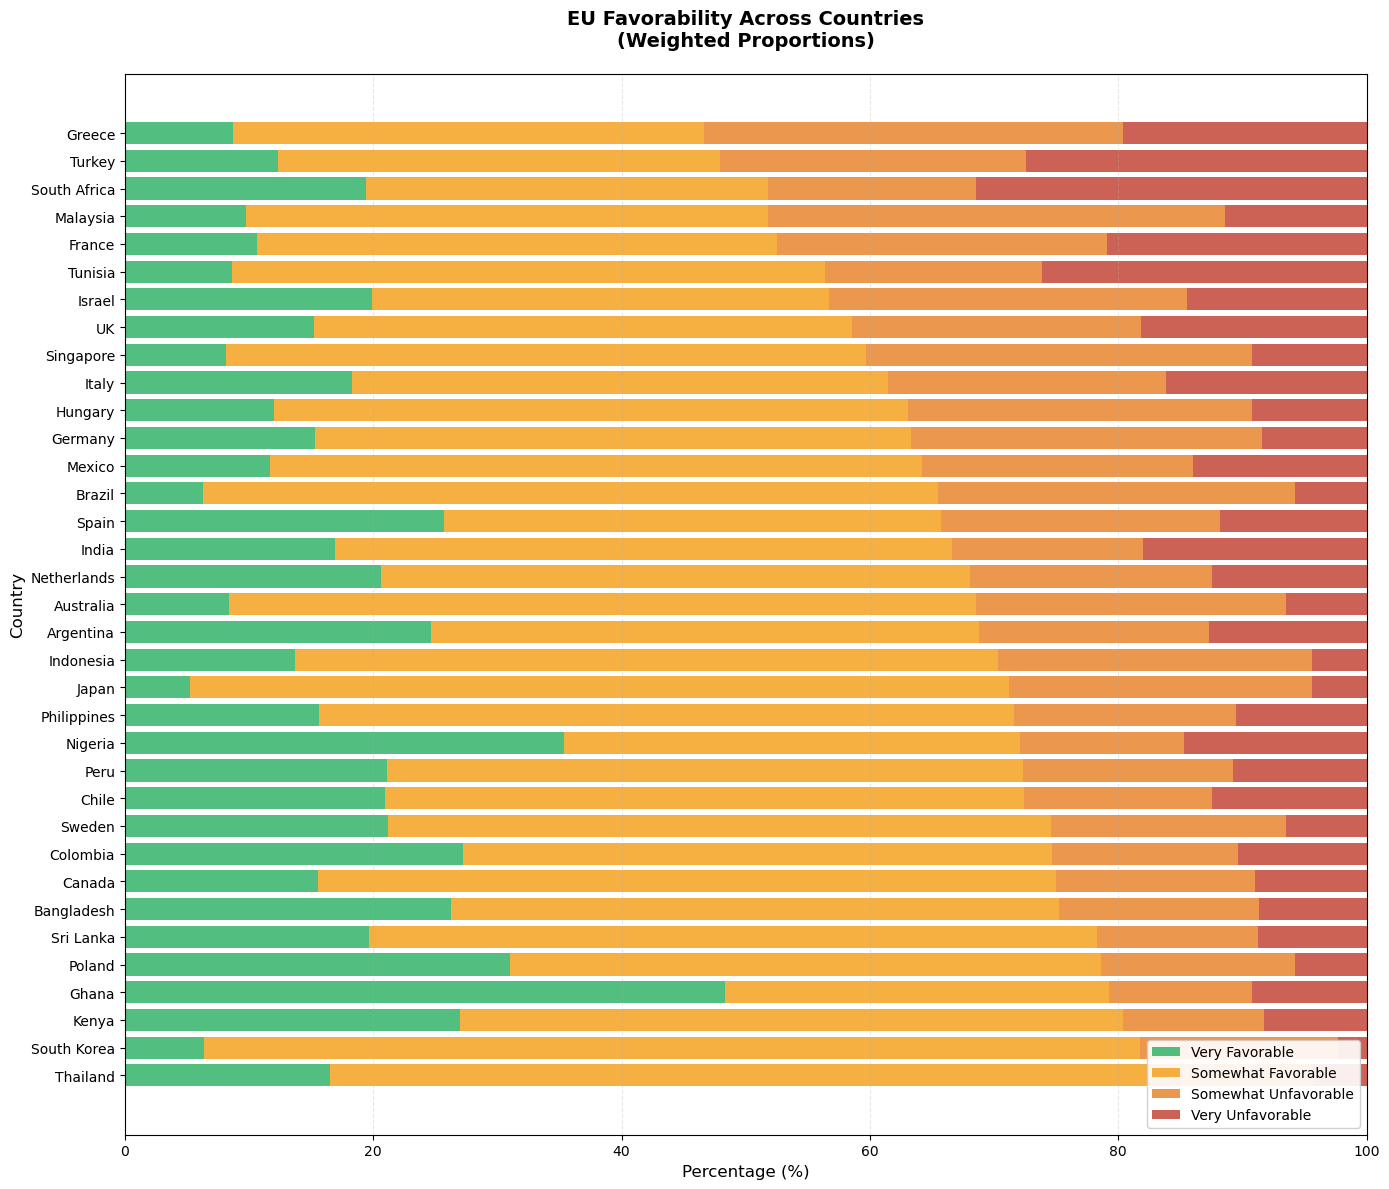

In [29]:
# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['fav_eu'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_eu'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('fav_eu')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    # Convert Series to dict, handling missing values
    country_proportions[country] = {
        '1': proportions.get('1', 0) if '1' in proportions.index else 0,  # Very favorable
        '2': proportions.get('2', 0) if '2' in proportions.index else 0,  # Somewhat favorable
        '3': proportions.get('3', 0) if '3' in proportions.index else 0,  # Somewhat unfavorable
        '4': proportions.get('4', 0) if '4' in proportions.index else 0   # Very unfavorable
    }

# Create a summary: % favorable (1 or 2) vs unfavorable (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    favorable_percent = props['1'] + props['2']  # Very + Somewhat favorable
    unfavorable_percent = props['3'] + props['4']  # Somewhat + Very unfavorable
    summary_stats[country] = {
        'Very Favorable': props['1'],
        'Somewhat Favorable': props['2'],
        'Somewhat Unfavorable': props['3'],
        'Very Unfavorable': props['4'],
        'Total Favorable': favorable_percent,
        'Total Unfavorable': unfavorable_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Total Favorable', ascending=False)

print("UK Favorability by Country (Weighted Proportions)")
print("=" * 90)
print(summary_df.round(1))

fig, ax = plt.subplots(figsize=(14, 12))

# Prepare data for stacked bar chart
countries = summary_df.index
categories = ['Very Favorable', 'Somewhat Favorable', 'Somewhat Unfavorable', 'Very Unfavorable']
colors = ['#27ae60', '#f39c12', '#e67e22', '#c0392b']  # Green to red gradient

# Create stacked bars
bottom = np.zeros(len(countries))
for category, color in zip(categories, colors):
    values = summary_df[category].values
    ax.barh(countries, values, left=bottom, label=category, color=color, alpha=0.8)
    bottom += values

ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('EU Favorability Across Countries\n(Weighted Proportions)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='lower right', framealpha=0.9)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

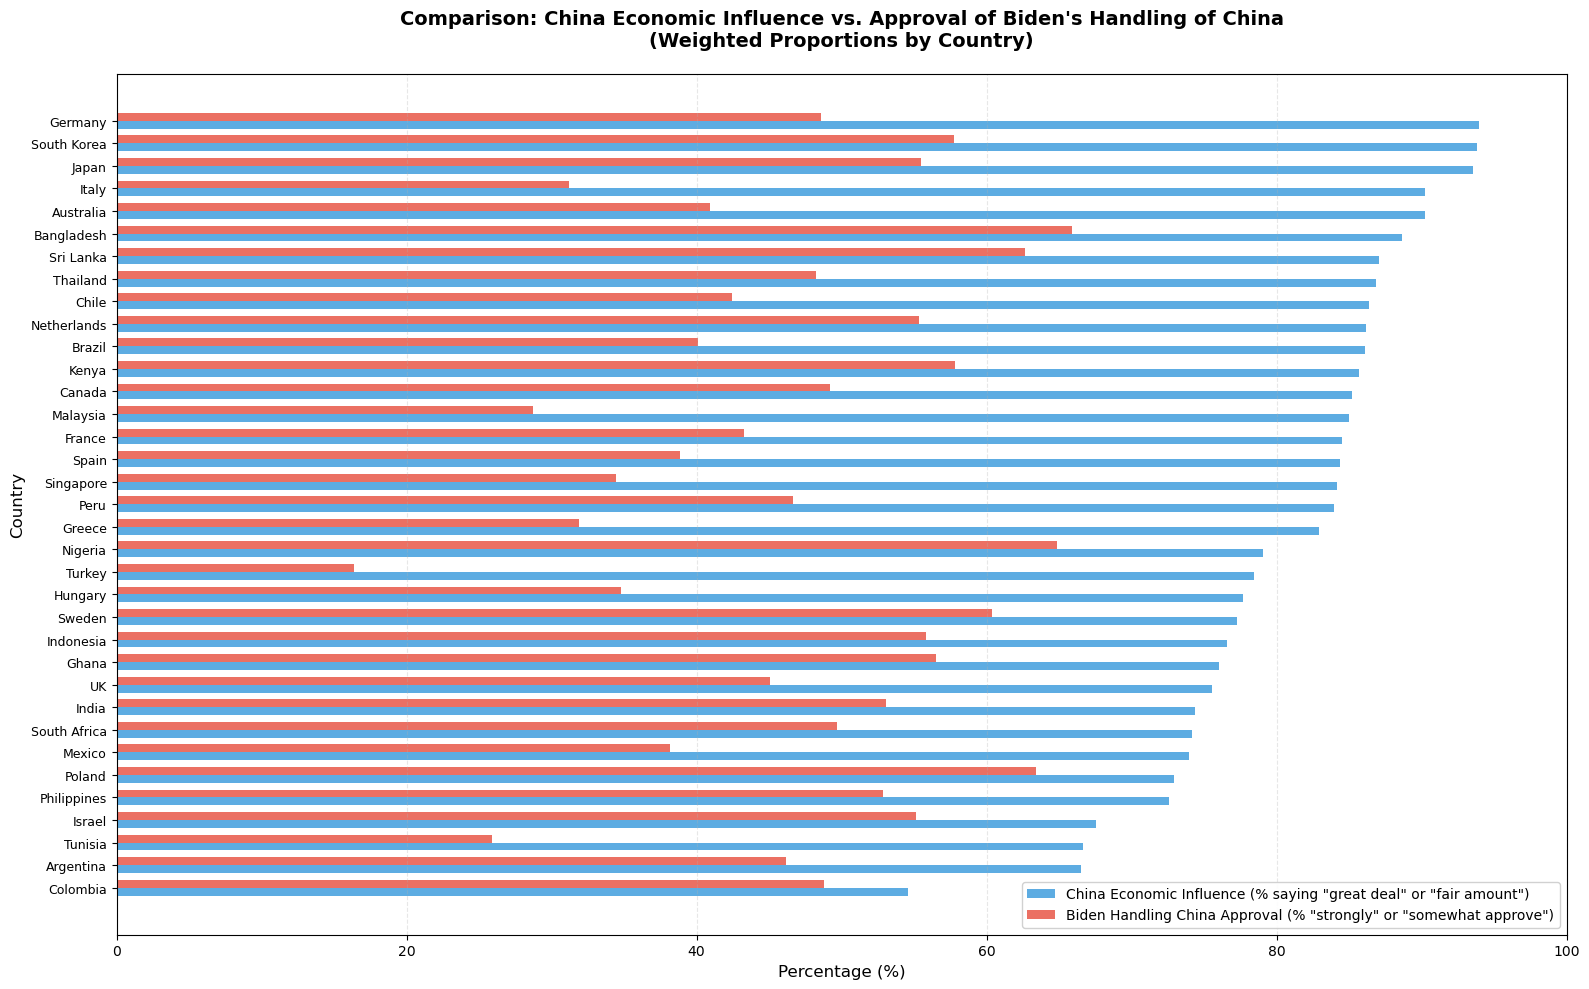

Summary Statistics (Weighted Proportions):

Number of countries: 35

China Economic Influence (% saying China has influence):
  Mean: 80.6%
  Range: 54.6% - 94.0%

Biden Handling China Approval (% approving):
  Mean: 47.0%
  Range: 16.4% - 65.9%


In [35]:
# Grouped Bar Chart: Comparing uspres_china vs china_influ_econ across countries
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['uspres_china'].isin(['1', '2', '3', '4']) & 
    pew['china_influ_econ'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'uspres_china', 'china_influ_econ'])

# Calculate weighted proportions for each country
# For ordinal variables, we use proportions, not means
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For uspres_china: % who approve (1 or 2: strongly/somewhat approve)
    uspres_approve = country_data[country_data['uspres_china'].isin(['1', '2'])]['weight'].sum()
    uspres_approve_pct = (uspres_approve / total_weight) * 100
    
    # For china_influ_econ: % who say China has influence (1 or 2: great deal/fair amount)
    econ_influence = country_data[country_data['china_influ_econ'].isin(['1', '2'])]['weight'].sum()
    econ_influence_pct = (econ_influence / total_weight) * 100
    
    country_stats[country] = {
        'uspres_approve_pct': uspres_approve_pct,
        'econ_influence_pct': econ_influence_pct
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T
# Sort by economic influence percentage for better visualization
plot_df = plot_df.sort_values('econ_influence_pct', ascending=True)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(16, 10))

# Set up positions for bars
x = np.arange(len(plot_df.index))
width = 0.35  # Width of the bars

# Create bars
bars1 = ax.barh(x - width/2, plot_df['econ_influence_pct'], width, 
                label='China Economic Influence (% saying "great deal" or "fair amount")', 
                color='#3498db', alpha=0.8)
bars2 = ax.barh(x + width/2, plot_df['uspres_approve_pct'], width, 
                label='Biden Handling China Approval (% "strongly" or "somewhat approve")', 
                color='#e74c3c', alpha=0.8)

# Customize the plot
ax.set_ylabel('Country', fontsize=12)
ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_title('Comparison: China Economic Influence vs. Approval of Biden\'s Handling of China\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.set_yticks(x)
ax.set_yticklabels(plot_df.index, fontsize=9)
ax.legend(loc='lower right', framealpha=0.9, fontsize=10)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nChina Economic Influence (% saying China has influence):")
print(f"  Mean: {plot_df['econ_influence_pct'].mean():.1f}%")
print(f"  Range: {plot_df['econ_influence_pct'].min():.1f}% - {plot_df['econ_influence_pct'].max():.1f}%")
print(f"\nBiden Handling China Approval (% approving):")
print(f"  Mean: {plot_df['uspres_approve_pct'].mean():.1f}%")
print(f"  Range: {plot_df['uspres_approve_pct'].min():.1f}% - {plot_df['uspres_approve_pct'].max():.1f}%")



Median Perceived Freedom: 87.8%
Median Importance: 84.7%

Quadrants:
  Q1 (Top-Right): High Perceived Freedom + High Importance
  Q2 (Top-Left): Low Perceived Freedom + High Importance (Compensatory)
  Q3 (Bottom-Left): Low Perceived Freedom + Low Importance
  Q4 (Bottom-Right): High Perceived Freedom + Low Importance


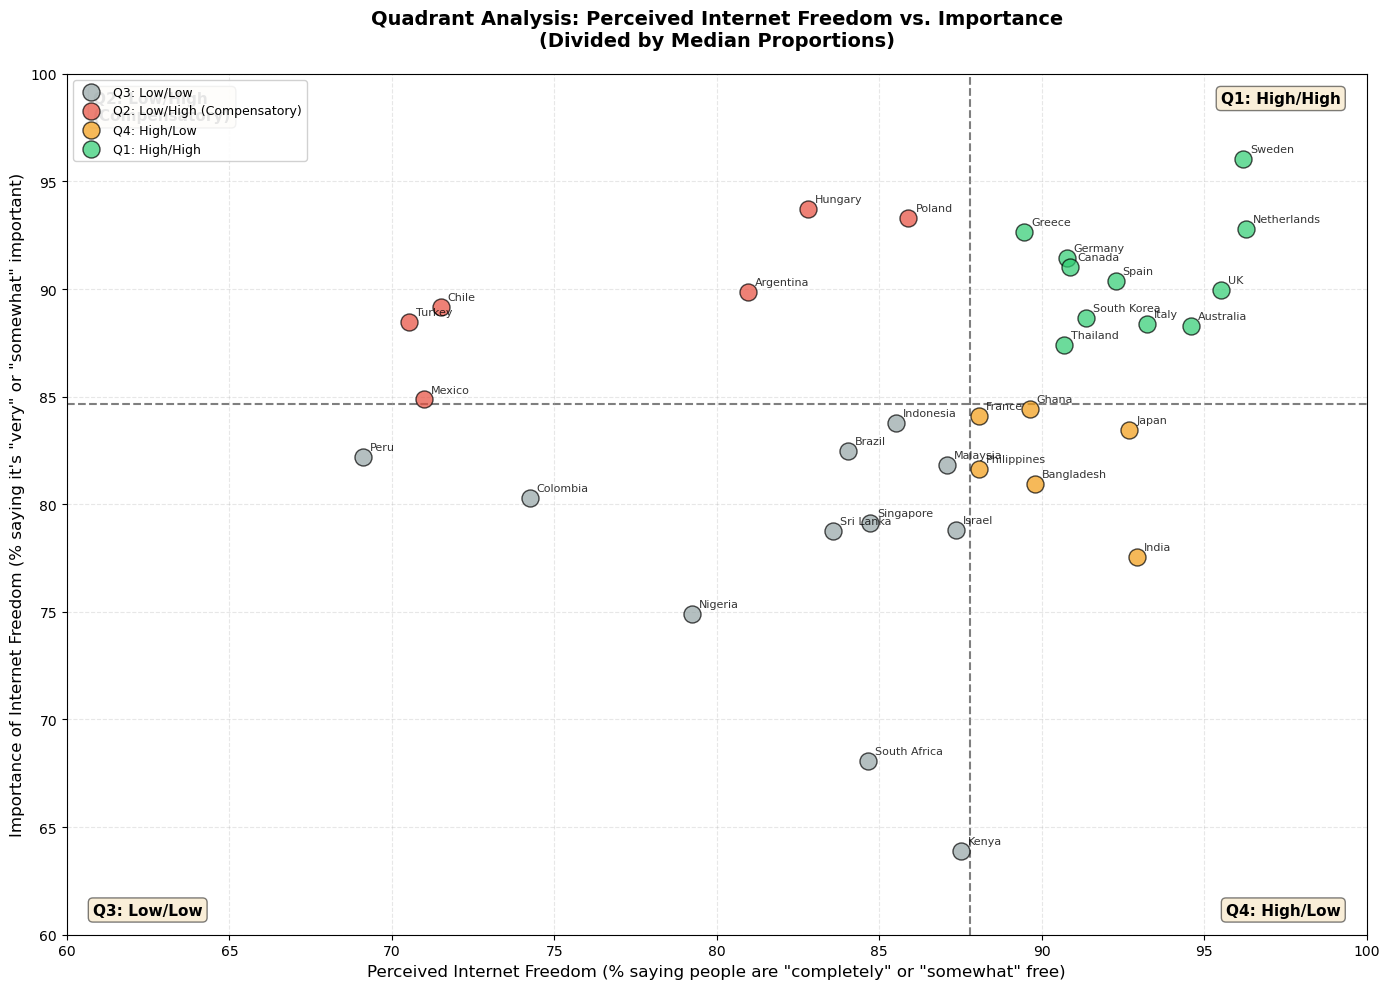

Summary Statistics (Weighted Proportions):

Number of countries: 34

Perceived Internet Freedom (% saying people are free):
  Mean: 86.2%
  Range: 69.1% - 96.3%

Importance of Internet Freedom (% saying it's important):
  Mean: 84.8%
  Range: 63.9% - 96.1%

Spearman Correlation: 0.321 (p-value: 0.0639)
  No statistically significant correlation.


In [43]:
# Quadrant Plot: free_internet (perceived) vs internet_freedom (importance)
# Using medians to divide into quadrants (appropriate for ordinal proportions)

# Reuse plot_df from previous cell
# Calculate medians (not means!) to divide countries into quadrants
median_perceived = plot_df['perceived_free_pct'].median()
median_importance = plot_df['importance_pct'].median()

print(f"Median Perceived Freedom: {median_perceived:.1f}%")
print(f"Median Importance: {median_importance:.1f}%")
print("\nQuadrants:")
print("  Q1 (Top-Right): High Perceived Freedom + High Importance")
print("  Q2 (Top-Left): Low Perceived Freedom + High Importance (Compensatory)")
print("  Q3 (Bottom-Left): Low Perceived Freedom + Low Importance")
print("  Q4 (Bottom-Right): High Perceived Freedom + Low Importance")

# Create quadrant plot
fig, ax = plt.subplots(figsize=(14, 10))

# Define quadrants based on medians
def get_quadrant(row):
    perceived = row['perceived_free_pct']
    importance = row['importance_pct']
    if perceived >= median_perceived and importance >= median_importance:
        return 'Q1: High/High'
    elif perceived < median_perceived and importance >= median_importance:
        return 'Q2: Low/High (Compensatory)'
    elif perceived < median_perceived and importance < median_importance:
        return 'Q3: Low/Low'
    else:
        return 'Q4: High/Low'

plot_df['quadrant'] = plot_df.apply(get_quadrant, axis=1)

# Color map for quadrants
colors = {
    'Q1: High/High': '#2ecc71',  # Green
    'Q2: Low/High (Compensatory)': '#e74c3c',  # Red
    'Q3: Low/Low': '#95a5a6',  # Gray
    'Q4: High/Low': '#f39c12'  # Orange
}

# Plot points by quadrant
for quadrant in plot_df['quadrant'].unique():
    quadrant_data = plot_df[plot_df['quadrant'] == quadrant]
    ax.scatter(quadrant_data['perceived_free_pct'], quadrant_data['importance_pct'],
              s=150, alpha=0.7, color=colors[quadrant], 
              edgecolors='black', linewidth=1, label=quadrant, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'perceived_free_pct'], 
                 plot_df.loc[country, 'importance_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Draw quadrant lines (using medians)
ax.axvline(x=median_perceived, color='black', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)
ax.axhline(y=median_importance, color='black', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)

# Add quadrant labels in corners
ax.text(0.98, 0.98, 'Q1: High/High', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.02, 0.98, 'Q2: Low/High\n(Compensatory)', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.02, 0.02, 'Q3: Low/Low', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.98, 0.02, 'Q4: High/Low', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='right', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Customize axes
ax.set_xlabel('Perceived Internet Freedom (% saying people are "completely" or "somewhat" free)', 
              fontsize=12)
ax.set_ylabel('Importance of Internet Freedom (% saying it\'s "very" or "somewhat" important)', 
              fontsize=12)
ax.set_title('Quadrant Analysis: Perceived Internet Freedom vs. Importance\n(Divided by Median Proportions)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(60, 100)
ax.set_ylim(60, 100)
ax.legend(loc='upper left', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nPerceived Internet Freedom (% saying people are free):")
print(f"  Mean: {plot_df['perceived_free_pct'].mean():.1f}%")
print(f"  Range: {plot_df['perceived_free_pct'].min():.1f}% - {plot_df['perceived_free_pct'].max():.1f}%")
print(f"\nImportance of Internet Freedom (% saying it's important):")
print(f"  Mean: {plot_df['importance_pct'].mean():.1f}%")
print(f"  Range: {plot_df['importance_pct'].min():.1f}% - {plot_df['importance_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['perceived_free_pct'], plot_df['importance_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")


Median Perceived Press Freedom: 73.0%
Median Importance: 88.1%

Quadrants:
  Q1 (Top-Right): High Perceived Freedom + High Importance
  Q2 (Top-Left): Low Perceived Freedom + High Importance (Compensatory)
  Q3 (Bottom-Left): Low Perceived Freedom + Low Importance
  Q4 (Bottom-Right): High Perceived Freedom + Low Importance


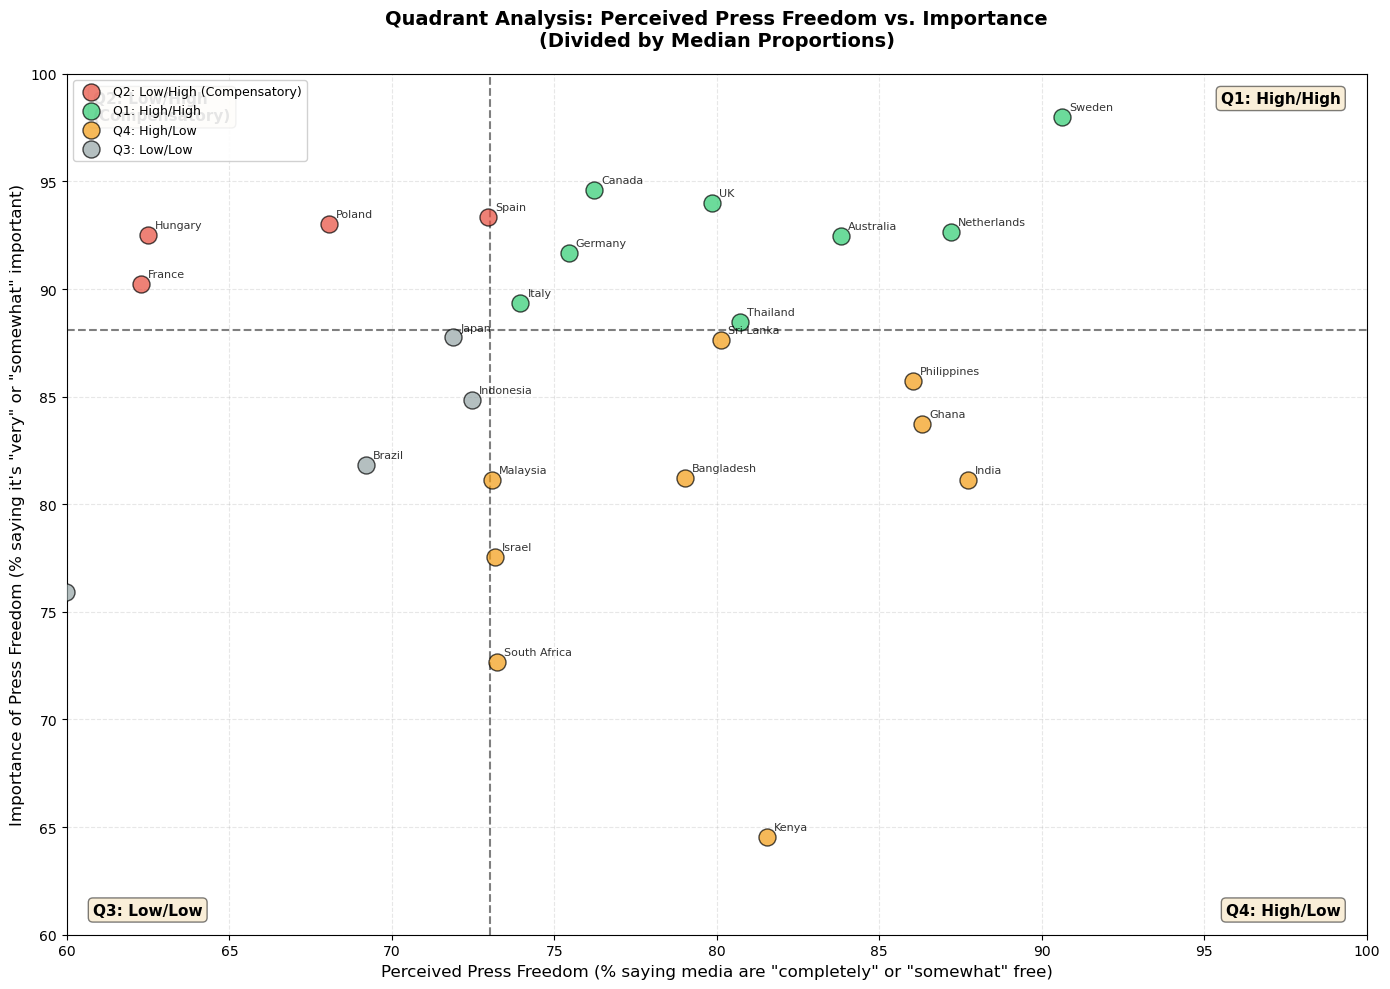


Countries by Quadrant:

Q1: High/High: 8 countries
  Australia, Canada, Germany, Italy, Netherlands, Sweden, Thailand, UK

Q2: Low/High (Compensatory): 9 countries
  Argentina, Chile, France, Greece, Hungary, Poland, South Korea, Spain, Turkey

Q3: Low/Low: 8 countries
  Brazil, Colombia, Indonesia, Japan, Mexico, Nigeria, Peru, Singapore

Q4: High/Low: 9 countries
  Bangladesh, Ghana, India, Israel, Kenya, Malaysia, Philippines, South Africa, Sri Lanka

Summary Statistics (Weighted Proportions):

Number of countries: 34

Perceived Press Freedom (% saying media are free):
  Mean: 68.3%
  Range: 29.3% - 90.6%

Importance of Press Freedom (% saying it's important):
  Mean: 86.7%
  Range: 64.5% - 98.0%

Spearman Correlation: 0.020 (p-value: 0.9105)
  No statistically significant correlation.


In [65]:
# Quadrant Plot: free_press (perceived) vs press_freedom (importance)
# Using medians to divide into quadrants (appropriate for ordinal proportions)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['free_press'].isin(['1', '2', '3', '4']) & 
    pew['press_freedom'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'free_press', 'press_freedom'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For free_press: % who say media are "completely" or "somewhat" free (1 or 2)
    # Note: Lower values = more free, so we want 1 or 2
    free_press_free = country_data[country_data['free_press'].isin(['1', '2'])]['weight'].sum()
    free_press_free_pct = (free_press_free / total_weight) * 100
    
    # For press_freedom: % who say it's "very important" or "somewhat important" (1 or 2)
    # Note: Lower values = more important, so we want 1 or 2
    press_freedom_important = country_data[country_data['press_freedom'].isin(['1', '2'])]['weight'].sum()
    press_freedom_important_pct = (press_freedom_important / total_weight) * 100
    
    country_stats[country] = {
        'perceived_free_pct': free_press_free_pct,  # % who perceive media as free
        'importance_pct': press_freedom_important_pct  # % who think freedom is important
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Calculate medians (not means!) to divide countries into quadrants
median_perceived = plot_df['perceived_free_pct'].median()
median_importance = plot_df['importance_pct'].median()

print(f"Median Perceived Press Freedom: {median_perceived:.1f}%")
print(f"Median Importance: {median_importance:.1f}%")
print("\nQuadrants:")
print("  Q1 (Top-Right): High Perceived Freedom + High Importance")
print("  Q2 (Top-Left): Low Perceived Freedom + High Importance (Compensatory)")
print("  Q3 (Bottom-Left): Low Perceived Freedom + Low Importance")
print("  Q4 (Bottom-Right): High Perceived Freedom + Low Importance")

# Create quadrant plot
fig, ax = plt.subplots(figsize=(14, 10))

# Define quadrants based on medians
def get_quadrant(row):
    perceived = row['perceived_free_pct']
    importance = row['importance_pct']
    if perceived >= median_perceived and importance >= median_importance:
        return 'Q1: High/High'
    elif perceived < median_perceived and importance >= median_importance:
        return 'Q2: Low/High (Compensatory)'
    elif perceived < median_perceived and importance < median_importance:
        return 'Q3: Low/Low'
    else:
        return 'Q4: High/Low'

plot_df['quadrant'] = plot_df.apply(get_quadrant, axis=1)

# Color map for quadrants
colors = {
    'Q1: High/High': '#2ecc71',  # Green
    'Q2: Low/High (Compensatory)': '#e74c3c',  # Red
    'Q3: Low/Low': '#95a5a6',  # Gray
    'Q4: High/Low': '#f39c12'  # Orange
}

# Plot points by quadrant
for quadrant in plot_df['quadrant'].unique():
    quadrant_data = plot_df[plot_df['quadrant'] == quadrant]
    ax.scatter(quadrant_data['perceived_free_pct'], quadrant_data['importance_pct'],
              s=150, alpha=0.7, color=colors[quadrant], 
              edgecolors='black', linewidth=1, label=quadrant, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'perceived_free_pct'], 
                 plot_df.loc[country, 'importance_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Draw quadrant lines (using medians)
ax.axvline(x=median_perceived, color='black', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)
ax.axhline(y=median_importance, color='black', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)

# Add quadrant labels in corners
ax.text(0.98, 0.98, 'Q1: High/High', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.02, 0.98, 'Q2: Low/High\n(Compensatory)', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.02, 0.02, 'Q3: Low/Low', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.98, 0.02, 'Q4: High/Low', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='right', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Customize axes
ax.set_xlabel('Perceived Press Freedom (% saying media are "completely" or "somewhat" free)', 
              fontsize=12)
ax.set_ylabel('Importance of Press Freedom (% saying it\'s "very" or "somewhat" important)', 
              fontsize=12)
ax.set_title('Quadrant Analysis: Perceived Press Freedom vs. Importance\n(Divided by Median Proportions)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(60, 100)
ax.set_ylim(60, 100)
ax.legend(loc='upper left', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nCountries by Quadrant:")
for quadrant in ['Q1: High/High', 'Q2: Low/High (Compensatory)', 'Q3: Low/Low', 'Q4: High/Low']:
    countries_in_quad = plot_df[plot_df['quadrant'] == quadrant].index.tolist()
    print(f"\n{quadrant}: {len(countries_in_quad)} countries")
    print(f"  {', '.join(countries_in_quad)}")

print("\nSummary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nPerceived Press Freedom (% saying media are free):")
print(f"  Mean: {plot_df['perceived_free_pct'].mean():.1f}%")
print(f"  Range: {plot_df['perceived_free_pct'].min():.1f}% - {plot_df['perceived_free_pct'].max():.1f}%")
print(f"\nImportance of Press Freedom (% saying it's important):")
print(f"  Mean: {plot_df['importance_pct'].mean():.1f}%")
print(f"  Range: {plot_df['importance_pct'].min():.1f}% - {plot_df['importance_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['perceived_free_pct'], plot_df['importance_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

Notes:

Countries where people perceive more free speech also place more importance on free speech, and this relationship is statistically significant (r = 0.363, p = 0.0351). This suggests a reinforcing pattern where experiencing freedom increases the value placed on it.

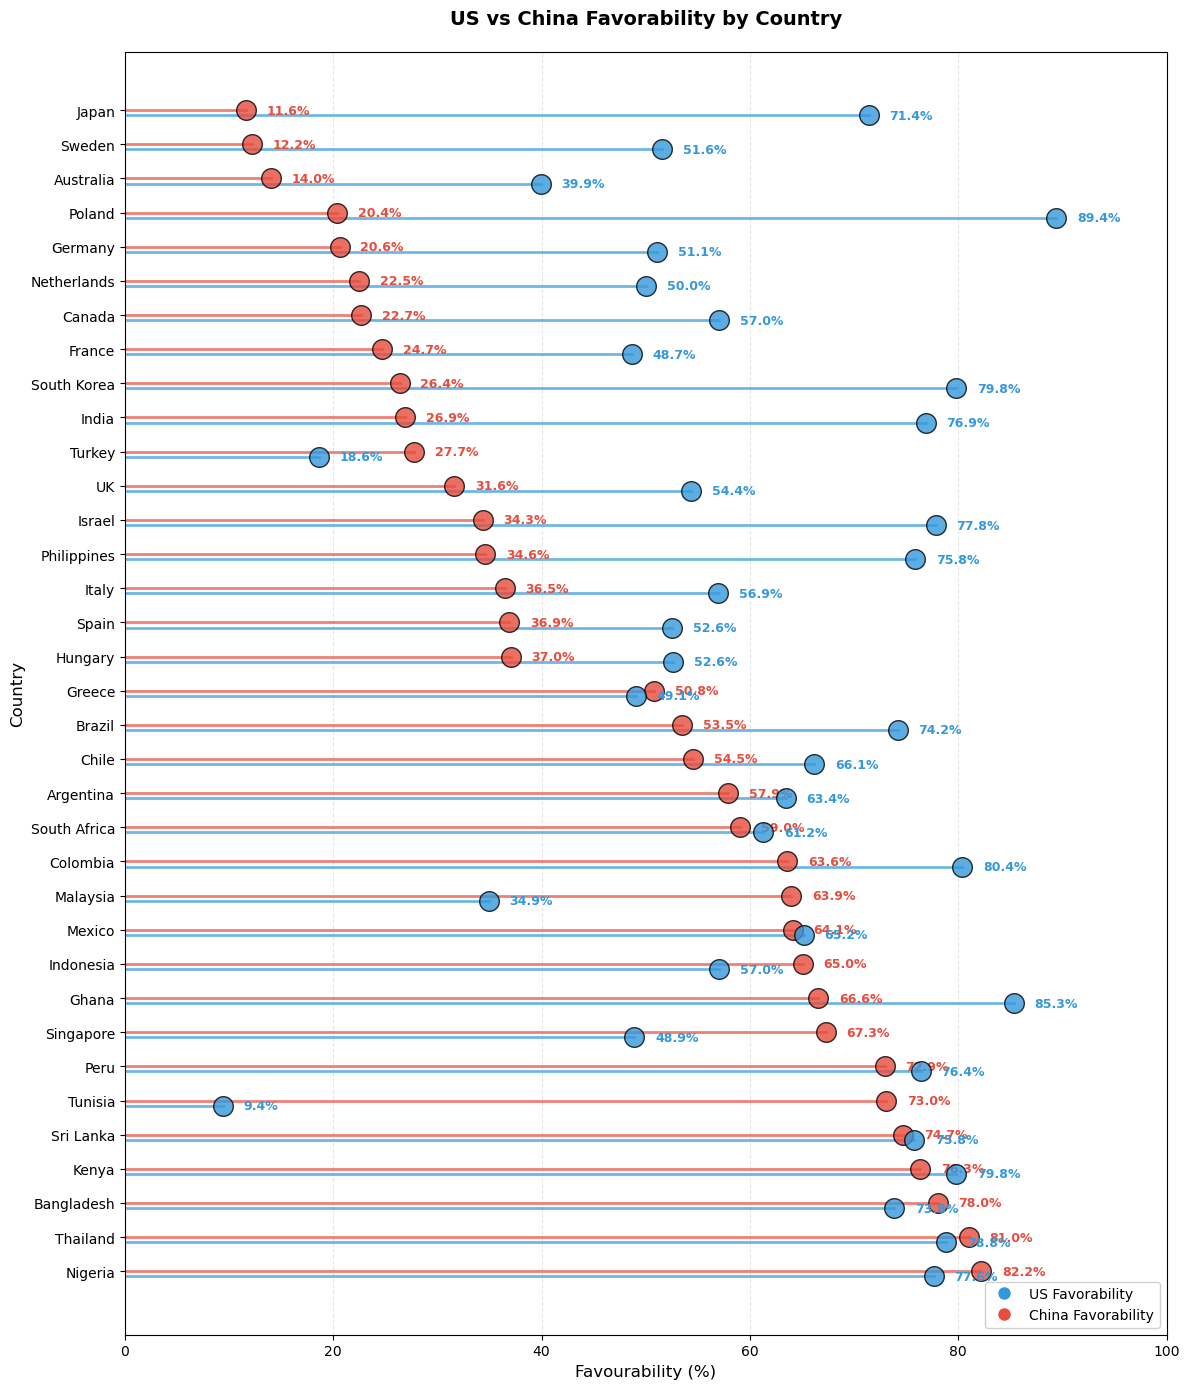

In [139]:
# Lollipop Chart: US vs China Favorability by Country
# Countries on Y-axis, similar style to social media penetration chart

# Filter to valid responses
valid_data = pew[
    pew['fav_us'].isin(['1', '2', '3', '4']) & 
    pew['fav_china'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_us', 'fav_china'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_us_favorable = country_data[country_data['fav_us'].isin(['1', '2'])]['weight'].sum()
    fav_us_pct = (fav_us_favorable / total_weight) * 100
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_pct = (fav_china_favorable / total_weight) * 100
    
    country_stats[country] = {
        'fav_us_pct': fav_us_pct,
        'fav_china_pct': fav_china_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Sort by China favorability for better visualization
plot_df = plot_df.sort_values('fav_china_pct', ascending=True)

# Create lollipop chart
fig, ax = plt.subplots(figsize=(12, max(10, len(plot_df) * 0.4)))

y_pos = np.arange(len(plot_df))

# Plot lines and dots for each country
for i, country in enumerate(plot_df.index):
    china_val = plot_df.loc[country, 'fav_china_pct']
    us_val = plot_df.loc[country, 'fav_us_pct']
    
    # China line and dot (red)
    ax.plot([0, china_val], [i, i], color='#e74c3c', linewidth=2, alpha=0.7)
    ax.scatter(china_val, i, s=200, color='#e74c3c', alpha=0.8, edgecolors='black', linewidth=1, zorder=3)
    ax.text(china_val + 2, i, f'{china_val:.1f}%', va='center', fontsize=9, color='#e74c3c', fontweight='bold')
    
    # US line and dot (blue) - offset slightly
    ax.plot([0, us_val], [i+0.15, i+0.15], color='#3498db', linewidth=2, alpha=0.7)
    ax.scatter(us_val, i+0.15, s=200, color='#3498db', alpha=0.8, edgecolors='black', linewidth=1, zorder=3)
    ax.text(us_val + 2, i+0.15, f'{us_val:.1f}%', va='center', fontsize=9, color='#3498db', fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xlabel('Favourability (%)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('US vs China Favorability by Country',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 100)
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()  # Top to bottom

# Add legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#3498db', markersize=10, label='US Favorability'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#e74c3c', markersize=10, label='China Favorability')
]
ax.legend(handles=legend_elements, loc='lower right', framealpha=0.9)

plt.tight_layout()
plt.show()

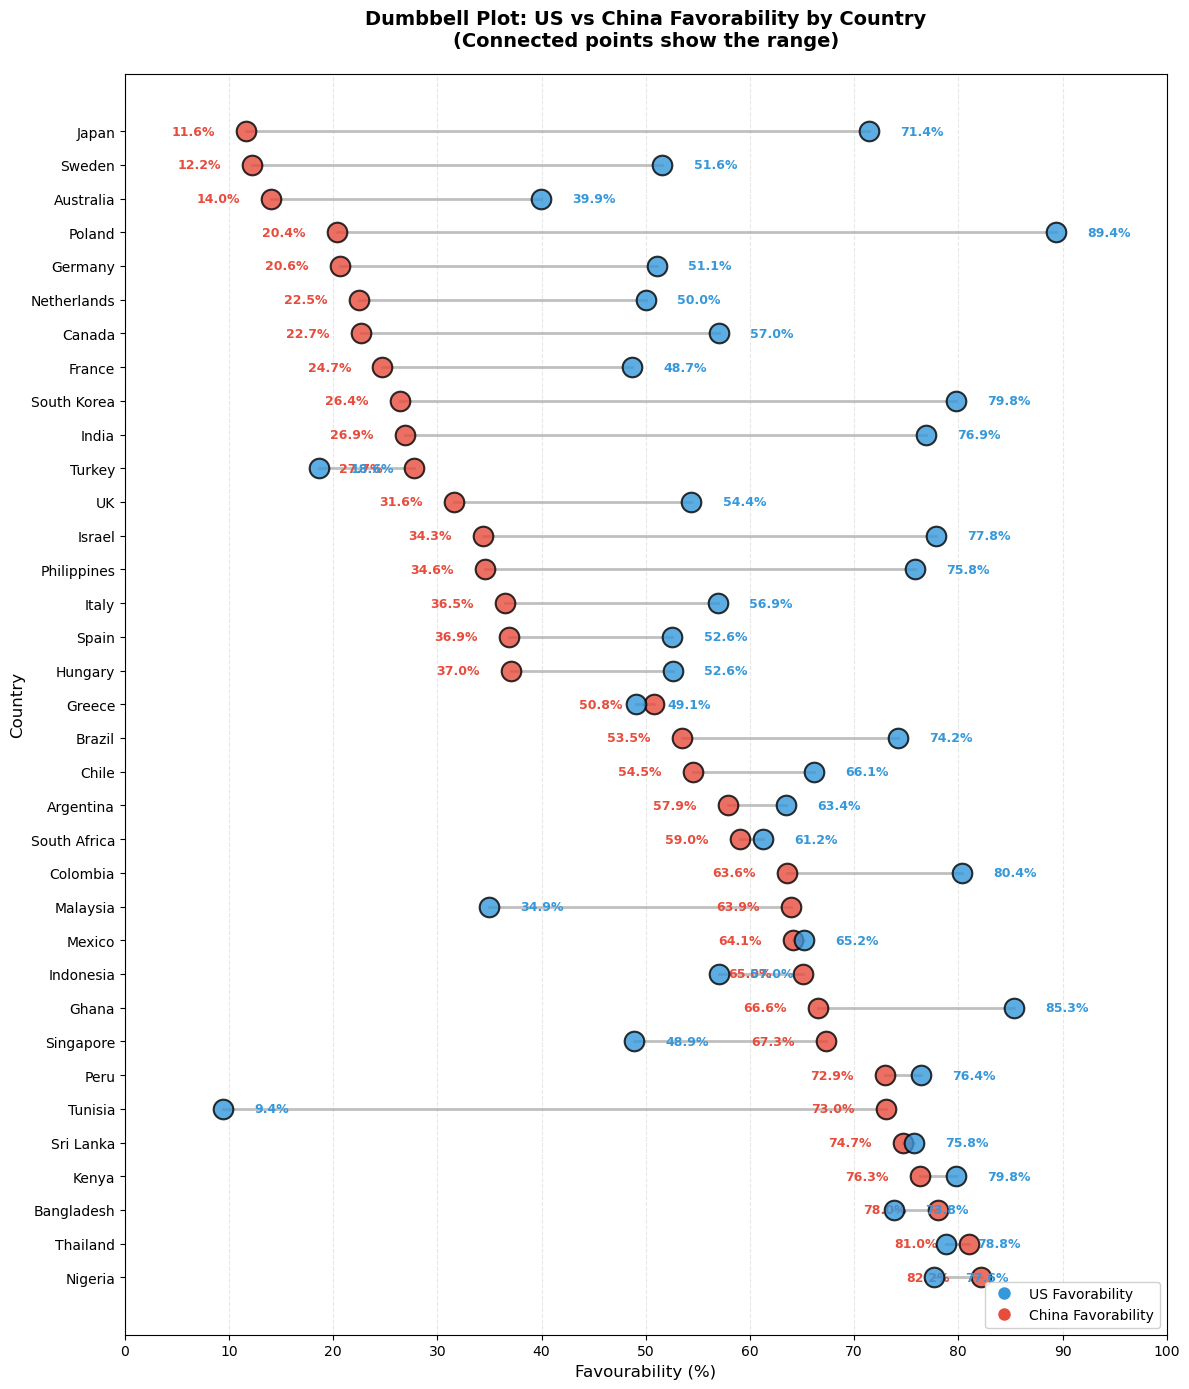

In [144]:
# Dumbbell Plot: US vs China Favorability by Country
# Connected points showing the range between US and China favorability

# Use the same plot_df from before (or recreate it)
valid_data = pew[
    pew['fav_us'].isin(['1', '2', '3', '4']) & 
    pew['fav_china'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_us', 'fav_china'])

country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_us_favorable = country_data[country_data['fav_us'].isin(['1', '2'])]['weight'].sum()
    fav_us_pct = (fav_us_favorable / total_weight) * 100
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_pct = (fav_china_favorable / total_weight) * 100
    
    country_stats[country] = {
        'fav_us_pct': fav_us_pct,
        'fav_china_pct': fav_china_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Sort by China favorability for better visualization
plot_df = plot_df.sort_values('fav_china_pct', ascending=True)

# Create dumbbell plot
fig, ax = plt.subplots(figsize=(12, max(10, len(plot_df) * 0.4)))

y_pos = np.arange(len(plot_df))

# Plot connecting lines and points for each country
# Plot connecting lines and points for each country
for i, country in enumerate(plot_df.index):
    china_val = plot_df.loc[country, 'fav_china_pct']
    us_val = plot_df.loc[country, 'fav_us_pct']
    
    # Draw connecting line (dumbbell bar)
    ax.plot([china_val, us_val], [i, i], color='gray', linewidth=2, alpha=0.5, zorder=1)
    
    # China point (left) - label on the left side
    ax.scatter(china_val, i, s=200, color='#e74c3c', alpha=0.8, edgecolors='black', linewidth=1.5, zorder=3)
    ax.text(china_val - 3, i, f'{china_val:.1f}%', ha='right', va='center', fontsize=9, 
            color='#e74c3c', fontweight='bold')
    
    # US point (right) - label on the right side
    ax.scatter(us_val, i, s=200, color='#3498db', alpha=0.8, edgecolors='black', linewidth=1.5, zorder=3)
    ax.text(us_val + 3, i, f'{us_val:.1f}%', ha='left', va='center', fontsize=9, 
            color='#3498db', fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xlabel('Favourability (%)', fontsize=12)
ax.set_xticks(np.arange(0, 101, 10))  # 0, 10, 20, 30, ..., 100
ax.set_ylabel('Country', fontsize=12)
ax.set_title('Dumbbell Plot: US vs China Favorability by Country\n(Connected points show the range)',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 100)
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()  # Top to bottom

# Add legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#3498db', markersize=10, label='US Favorability'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#e74c3c', markersize=10, label='China Favorability')
]
ax.legend(handles=legend_elements, loc='lower right', framealpha=0.9)

plt.tight_layout()
plt.show()

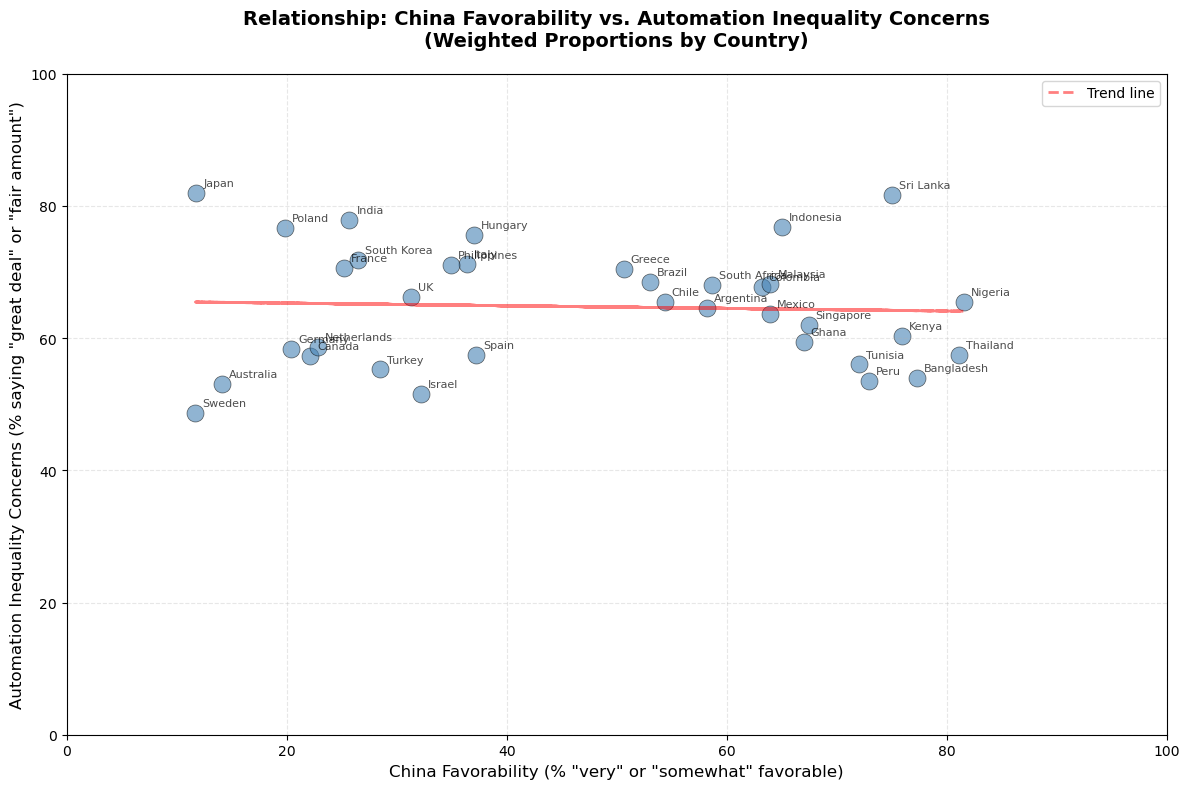

Summary Statistics (Weighted Proportions):

Number of countries: 35

China Favorability (% favorable):
  Mean: 46.8%
  Range: 11.7% - 81.6%

Automation Inequality Concerns (% saying it leads to inequality):
  Mean: 64.8%
  Range: 48.6% - 81.9%

Spearman Correlation: -0.073 (p-value: 0.6764)
  No statistically significant correlation.


In [73]:
# Scatterplot: fav_china vs inequality_automation
# Testing: Do countries with automation anxiety view China differently?
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['inequality_automation'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'inequality_automation'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_china: % who are favorable (1 or 2: very/somewhat favorable)
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    # For inequality_automation: % who say it leads to inequality "a great deal" or "a fair amount" (1 or 2)
    automation_inequality = country_data[country_data['inequality_automation'].isin(['1', '2'])]['weight'].sum()
    automation_inequality_pct = (automation_inequality / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'automation_inequality_pct': automation_inequality_pct
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df['fav_china_favorable_pct'], 
           plot_df['automation_inequality_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'fav_china_favorable_pct'], 
                 plot_df.loc[country, 'automation_inequality_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional - helps visualize correlation)
from scipy import stats
z = np.polyfit(plot_df['fav_china_favorable_pct'], 
               plot_df['automation_inequality_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['fav_china_favorable_pct'], 
        p(plot_df['fav_china_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('China Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Automation Inequality Concerns (% saying "great deal" or "fair amount")', fontsize=12)
ax.set_title('Relationship: China Favorability vs. Automation Inequality Concerns\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nChina Favorability (% favorable):")
print(f"  Mean: {plot_df['fav_china_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df['fav_china_favorable_pct'].min():.1f}% - {plot_df['fav_china_favorable_pct'].max():.1f}%")
print(f"\nAutomation Inequality Concerns (% saying it leads to inequality):")
print(f"  Mean: {plot_df['automation_inequality_pct'].mean():.1f}%")
print(f"  Range: {plot_df['automation_inequality_pct'].min():.1f}% - {plot_df['automation_inequality_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['fav_china_favorable_pct'], 
                                 plot_df['automation_inequality_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
    if correlation < 0:
        print("  Negative correlation: More automation anxiety → Less favorable views of China")
    else:
        print("  Positive correlation: More automation anxiety → More favorable views of China")
else:
    print("  No statistically significant correlation.")

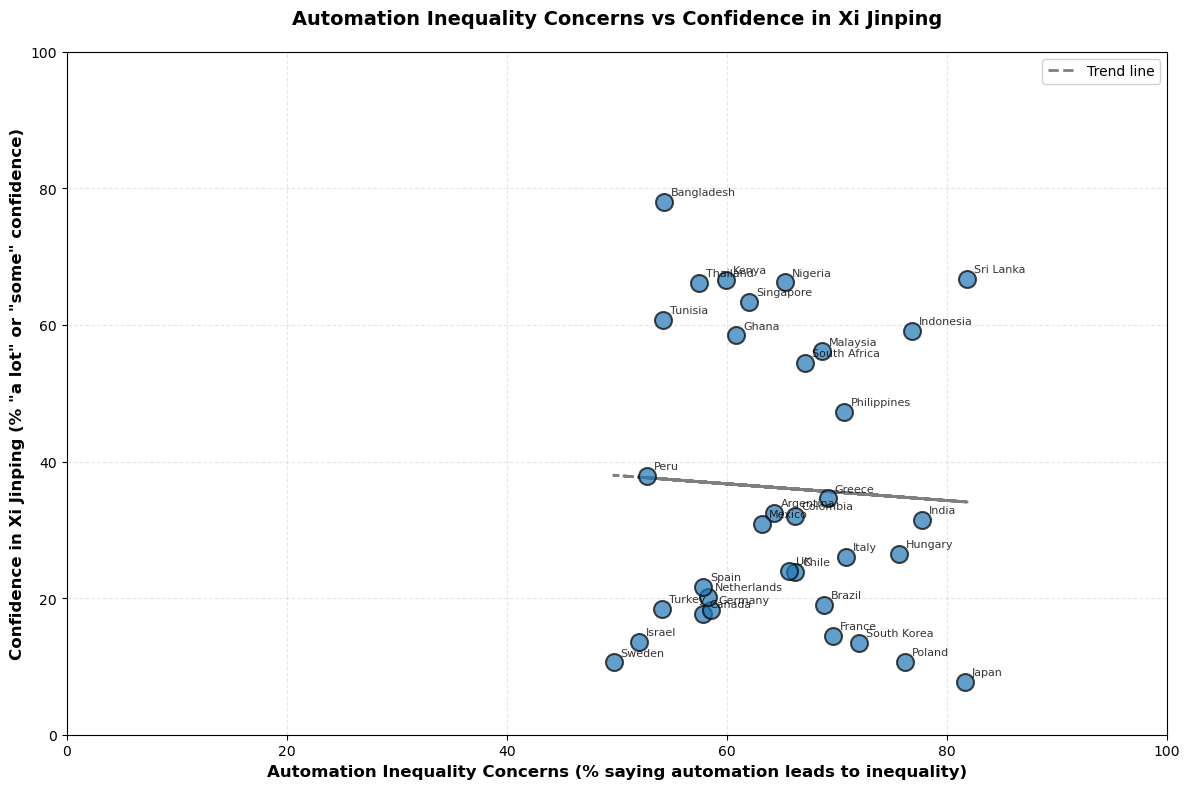

SUMMARY STATISTICS (Weighted Proportions)

Number of countries: 34

Automation Inequality Concerns (% saying it leads to inequality):
  Mean: 64.9%
  Range: 49.7% - 81.9%

Confidence in Xi Jinping (% 'a lot' or 'some' confidence):
  Mean: 36.1%
  Range: 7.8% - 78.1%

Spearman Correlation: -0.033 (p-value: 0.8510)
  ✗ No statistically significant correlation.
  This suggests automation inequality concerns and confidence in Xi Jinping are independent.


In [331]:
# Scatterplot: Automation Inequality Concerns vs Confidence in Xi Jinping
# Testing: Do countries with automation anxiety view China's leadership differently?

# Filter to valid responses
valid_data = pew[
    pew['inequality_automation'].isin(['1', '2', '3', '4']) & 
    pew['confid_xi'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'inequality_automation', 'confid_xi'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Automation inequality: % who say automation leads to inequality (1 or 2)
    automation_inequality = country_data[country_data['inequality_automation'].isin(['1', '2'])]['weight'].sum()
    automation_inequality_pct = (automation_inequality / total_weight) * 100
    
    # Confidence in Xi: % who have "a lot" or "some" confidence (1 or 2)
    confid_xi_high = country_data[country_data['confid_xi'].isin(['1', '2'])]['weight'].sum()
    confid_xi_high_pct = (confid_xi_high / total_weight) * 100
    
    country_stats[country] = {
        'automation_inequality_pct': automation_inequality_pct,
        'confid_xi_pct': confid_xi_high_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points
ax.scatter(plot_df['automation_inequality_pct'], 
           plot_df['confid_xi_pct'], 
           s=150, alpha=0.7, edgecolors='black', linewidth=1.5, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'automation_inequality_pct'], 
                 plot_df.loc[country, 'confid_xi_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Add trend line
z = np.polyfit(plot_df['automation_inequality_pct'], 
               plot_df['confid_xi_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['automation_inequality_pct'], 
        p(plot_df['automation_inequality_pct']), 
        "k--", alpha=0.5, linewidth=2, label='Trend line', zorder=2)

# Customize axes
ax.set_xlabel('Automation Inequality Concerns (% saying automation leads to inequality)', 
              fontsize=12, fontweight='bold')
ax.set_ylabel('Confidence in Xi Jinping (% "a lot" or "some" confidence)', 
              fontsize=12, fontweight='bold')
ax.set_title('Automation Inequality Concerns vs Confidence in Xi Jinping',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='best', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("SUMMARY STATISTICS (Weighted Proportions)")
print("="*70)
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nAutomation Inequality Concerns (% saying it leads to inequality):")
print(f"  Mean: {plot_df['automation_inequality_pct'].mean():.1f}%")
print(f"  Range: {plot_df['automation_inequality_pct'].min():.1f}% - {plot_df['automation_inequality_pct'].max():.1f}%")
print(f"\nConfidence in Xi Jinping (% 'a lot' or 'some' confidence):")
print(f"  Mean: {plot_df['confid_xi_pct'].mean():.1f}%")
print(f"  Range: {plot_df['confid_xi_pct'].min():.1f}% - {plot_df['confid_xi_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['automation_inequality_pct'], 
                                 plot_df['confid_xi_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  ✓ Statistically significant correlation!")
    if correlation > 0:
        print("  Countries with higher automation inequality concerns tend to have more confidence in Xi Jinping.")
    else:
        print("  Countries with higher automation inequality concerns tend to have less confidence in Xi Jinping.")
else:
    print("  ✗ No statistically significant correlation.")
    print("  This suggests automation inequality concerns and confidence in Xi Jinping are independent.")

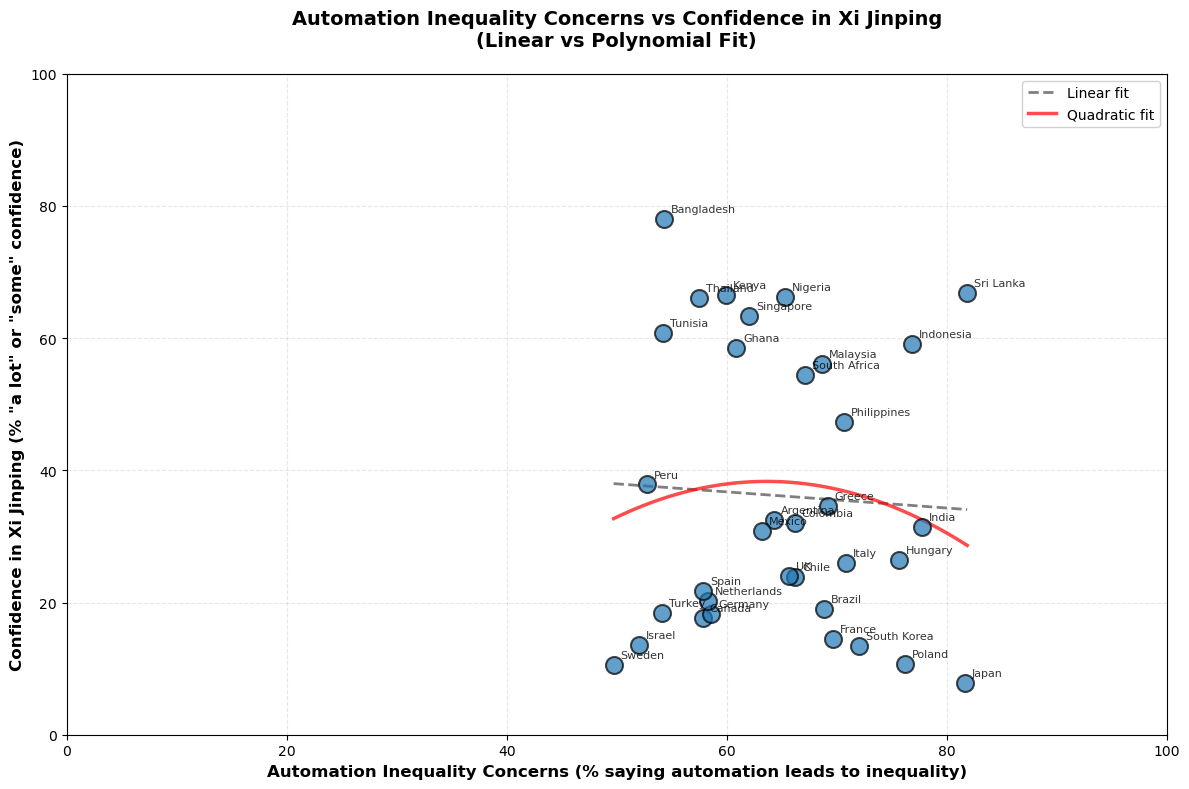

LINEAR vs POLYNOMIAL FIT COMPARISON

Linear Model (y = -0.122x + 44.059):
  R-squared: 0.0026
  RSS (Residual Sum of Squares): 14522.70

Quadratic Model (y = -0.029x² + 3.704x + -79.490):
  R-squared: 0.0147
  RSS (Residual Sum of Squares): 14345.56

Model Comparison (F-test):
  F-statistic: 0.383
  p-value: 0.5406
  ✗ Quadratic model does not fit significantly better than linear.
  Linear relationship is sufficient.

Spearman Correlation (non-parametric): -0.033 (p-value: 0.8510)
  ✗ No statistically significant monotonic relationship


In [335]:
# Scatterplot: Automation Inequality Concerns vs Confidence in Xi Jinping
# Testing for non-linear (polynomial) relationships

# Filter to valid responses
valid_data = pew[
    pew['inequality_automation'].isin(['1', '2', '3', '4']) & 
    pew['confid_xi'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'inequality_automation', 'confid_xi'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Automation inequality: % who say automation leads to inequality (1 or 2)
    automation_inequality = country_data[country_data['inequality_automation'].isin(['1', '2'])]['weight'].sum()
    automation_inequality_pct = (automation_inequality / total_weight) * 100
    
    # Confidence in Xi: % who have "a lot" or "some" confidence (1 or 2)
    confid_xi_high = country_data[country_data['confid_xi'].isin(['1', '2'])]['weight'].sum()
    confid_xi_high_pct = (confid_xi_high / total_weight) * 100
    
    country_stats[country] = {
        'automation_inequality_pct': automation_inequality_pct,
        'confid_xi_pct': confid_xi_high_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points
ax.scatter(plot_df['automation_inequality_pct'], 
           plot_df['confid_xi_pct'], 
           s=150, alpha=0.7, edgecolors='black', linewidth=1.5, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'automation_inequality_pct'], 
                 plot_df.loc[country, 'confid_xi_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Fit linear model
x = plot_df['automation_inequality_pct'].values
y = plot_df['confid_xi_pct'].values

# Linear fit (degree 1)
linear_coefs = np.polyfit(x, y, 1)
linear_poly = np.poly1d(linear_coefs)
x_line = np.linspace(x.min(), x.max(), 100)
y_linear = linear_poly(x_line)

# Polynomial fit (degree 2 - quadratic)
poly_coefs = np.polyfit(x, y, 2)
poly_poly = np.poly1d(poly_coefs)
y_poly = poly_poly(x_line)

# Plot both fits
ax.plot(x_line, y_linear, "k--", alpha=0.5, linewidth=2, label='Linear fit', zorder=2)
ax.plot(x_line, y_poly, "r-", alpha=0.7, linewidth=2.5, label='Quadratic fit', zorder=2)

# Calculate R-squared for both models
from sklearn.metrics import r2_score

y_pred_linear = linear_poly(x)
y_pred_poly = poly_poly(x)

r2_linear = r2_score(y, y_pred_linear)
r2_poly = r2_score(y, y_pred_poly)

# F-test to compare models
from scipy.stats import f
n = len(x)
p_linear = 2  # number of parameters in linear model (slope + intercept)
p_poly = 3    # number of parameters in quadratic model

# Residual sum of squares
rss_linear = np.sum((y - y_pred_linear)**2)
rss_poly = np.sum((y - y_pred_poly)**2)

# F-statistic
f_stat = ((rss_linear - rss_poly) / (p_poly - p_linear)) / (rss_poly / (n - p_poly))
f_pvalue = 1 - f.cdf(f_stat, p_poly - p_linear, n - p_poly)

# Customize axes
ax.set_xlabel('Automation Inequality Concerns (% saying automation leads to inequality)', 
              fontsize=12, fontweight='bold')
ax.set_ylabel('Confidence in Xi Jinping (% "a lot" or "some" confidence)', 
              fontsize=12, fontweight='bold')
ax.set_title('Automation Inequality Concerns vs Confidence in Xi Jinping\n(Linear vs Polynomial Fit)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='best', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

# Print comparison statistics
print("="*70)
print("LINEAR vs POLYNOMIAL FIT COMPARISON")
print("="*70)
print(f"\nLinear Model (y = {linear_coefs[0]:.3f}x + {linear_coefs[1]:.3f}):")
print(f"  R-squared: {r2_linear:.4f}")
print(f"  RSS (Residual Sum of Squares): {rss_linear:.2f}")

print(f"\nQuadratic Model (y = {poly_coefs[0]:.3f}x² + {poly_coefs[1]:.3f}x + {poly_coefs[2]:.3f}):")
print(f"  R-squared: {r2_poly:.4f}")
print(f"  RSS (Residual Sum of Squares): {rss_poly:.2f}")

print(f"\nModel Comparison (F-test):")
print(f"  F-statistic: {f_stat:.3f}")
print(f"  p-value: {f_pvalue:.4f}")
if f_pvalue < 0.05:
    print(f"  ✓ Quadratic model fits significantly better than linear!")
    print(f"  This suggests a non-linear relationship.")
else:
    print(f"  ✗ Quadratic model does not fit significantly better than linear.")
    print(f"  Linear relationship is sufficient.")

# Spearman correlation (non-parametric, doesn't assume linearity)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(x, y)
print(f"\nSpearman Correlation (non-parametric): {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  ✓ Statistically significant monotonic relationship")
else:
    print("  ✗ No statistically significant monotonic relationship")

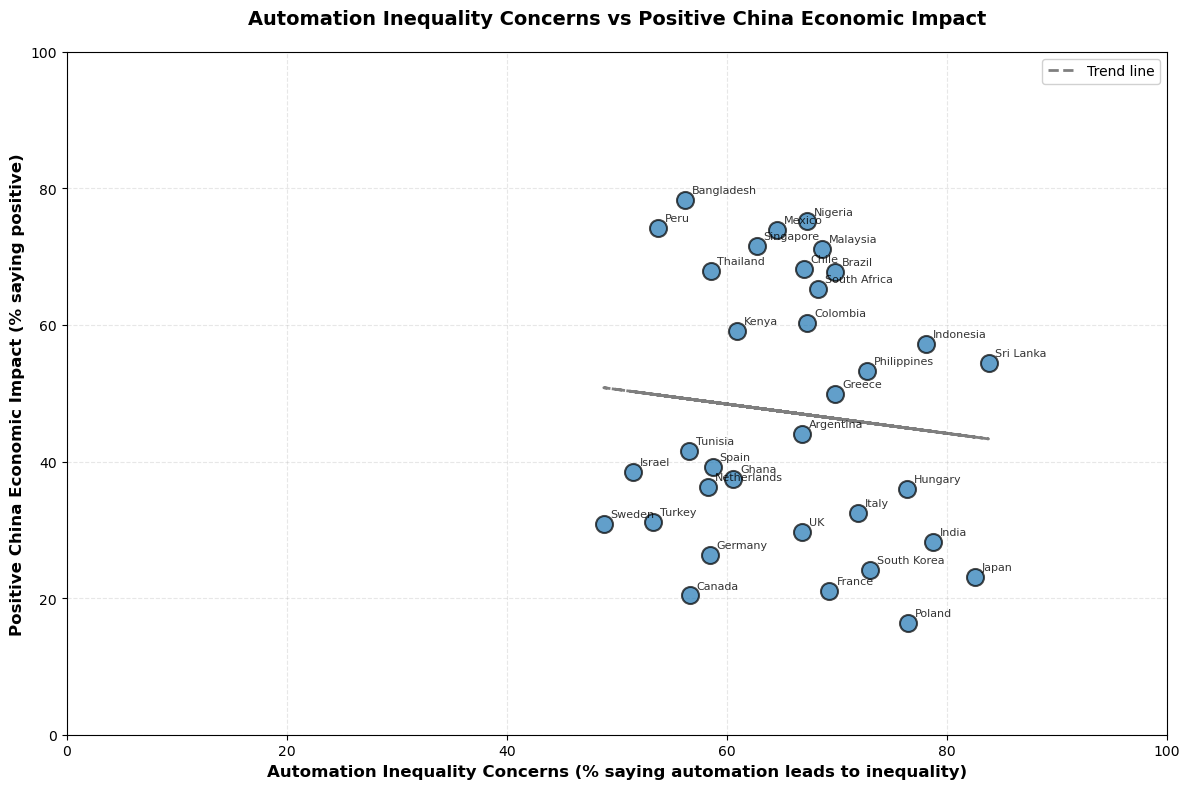

SUMMARY STATISTICS (Weighted Proportions)

Number of countries: 34

Automation Inequality Concerns (% saying it leads to inequality):
  Mean: 65.7%
  Range: 48.8% - 83.8%

Positive China Economic Impact (% saying positive):
  Mean: 47.2%
  Range: 16.3% - 78.3%

Spearman Correlation: -0.156 (p-value: 0.3774)
  ✗ No statistically significant correlation.
  This suggests automation inequality concerns and views of China's positive economic impact are independent.


In [332]:
# Scatterplot: Automation Inequality Concerns vs Positive China Economic Impact
# Testing: Do countries with automation anxiety see China's economic impact as positive?

# Filter to valid responses
valid_data = pew[
    pew['inequality_automation'].isin(['1', '2', '3', '4']) & 
    pew['china_influ_econ2'].isin(['1', '2', '3'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'inequality_automation', 'china_influ_econ2'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Automation inequality: % who say automation leads to inequality (1 or 2)
    automation_inequality = country_data[country_data['inequality_automation'].isin(['1', '2'])]['weight'].sum()
    automation_inequality_pct = (automation_inequality / total_weight) * 100
    
    # China economic impact: % who say it's positive (1)
    china_positive = country_data[country_data['china_influ_econ2'] == '1']['weight'].sum()
    china_positive_pct = (china_positive / total_weight) * 100
    
    country_stats[country] = {
        'automation_inequality_pct': automation_inequality_pct,
        'china_positive_pct': china_positive_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points
ax.scatter(plot_df['automation_inequality_pct'], 
           plot_df['china_positive_pct'], 
           s=150, alpha=0.7, edgecolors='black', linewidth=1.5, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'automation_inequality_pct'], 
                 plot_df.loc[country, 'china_positive_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Add trend line
z = np.polyfit(plot_df['automation_inequality_pct'], 
               plot_df['china_positive_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['automation_inequality_pct'], 
        p(plot_df['automation_inequality_pct']), 
        "k--", alpha=0.5, linewidth=2, label='Trend line', zorder=2)

# Customize axes
ax.set_xlabel('Automation Inequality Concerns (% saying automation leads to inequality)', 
              fontsize=12, fontweight='bold')
ax.set_ylabel('Positive China Economic Impact (% saying positive)', 
              fontsize=12, fontweight='bold')
ax.set_title('Automation Inequality Concerns vs Positive China Economic Impact',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='best', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("SUMMARY STATISTICS (Weighted Proportions)")
print("="*70)
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nAutomation Inequality Concerns (% saying it leads to inequality):")
print(f"  Mean: {plot_df['automation_inequality_pct'].mean():.1f}%")
print(f"  Range: {plot_df['automation_inequality_pct'].min():.1f}% - {plot_df['automation_inequality_pct'].max():.1f}%")
print(f"\nPositive China Economic Impact (% saying positive):")
print(f"  Mean: {plot_df['china_positive_pct'].mean():.1f}%")
print(f"  Range: {plot_df['china_positive_pct'].min():.1f}% - {plot_df['china_positive_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['automation_inequality_pct'], 
                                 plot_df['china_positive_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  ✓ Statistically significant correlation!")
    if correlation > 0:
        print("  Countries with higher automation inequality concerns tend to see China's economic impact as more positive.")
    else:
        print("  Countries with higher automation inequality concerns tend to see China's economic impact as less positive.")
else:
    print("  ✗ No statistically significant correlation.")
    print("  This suggests automation inequality concerns and views of China's positive economic impact are independent.")

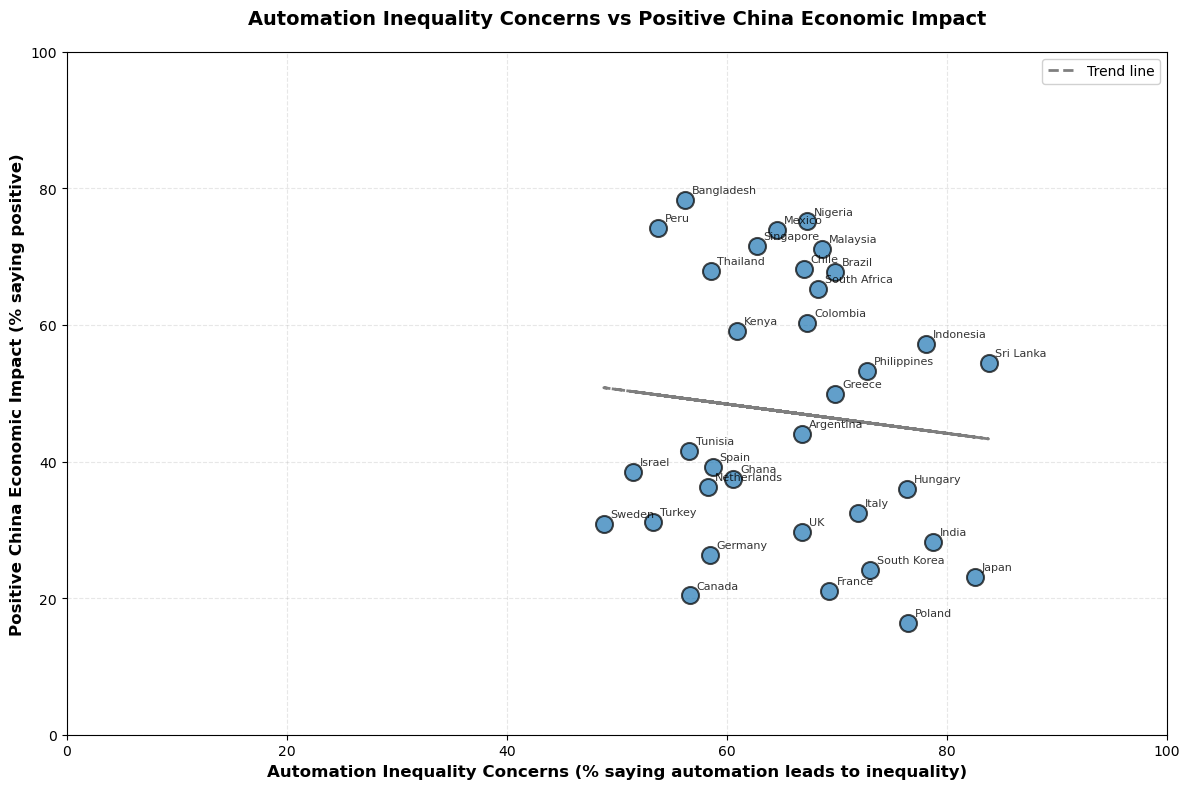

SUMMARY STATISTICS (Weighted Proportions)

Number of countries: 34

Automation Inequality Concerns (% saying it leads to inequality):
  Mean: 65.7%
  Range: 48.8% - 83.8%

Positive China Economic Impact (% saying positive):
  Mean: 47.2%
  Range: 16.3% - 78.3%

Spearman Correlation: -0.156 (p-value: 0.3774)
  ✗ No statistically significant correlation.
  This suggests automation inequality concerns and views of China's positive economic impact are independent.


In [333]:
# Scatterplot: Automation Inequality Concerns vs Positive China Economic Impact
# Testing: Do countries with automation anxiety see China's economic impact as positive?

# Filter to valid responses
valid_data = pew[
    pew['inequality_automation'].isin(['1', '2', '3', '4']) & 
    pew['china_influ_econ2'].isin(['1', '2', '3'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'inequality_automation', 'china_influ_econ2'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Automation inequality: % who say automation leads to inequality (1 or 2)
    automation_inequality = country_data[country_data['inequality_automation'].isin(['1', '2'])]['weight'].sum()
    automation_inequality_pct = (automation_inequality / total_weight) * 100
    
    # China economic impact: % who say it's positive (1)
    china_positive = country_data[country_data['china_influ_econ2'] == '1']['weight'].sum()
    china_positive_pct = (china_positive / total_weight) * 100
    
    country_stats[country] = {
        'automation_inequality_pct': automation_inequality_pct,
        'china_positive_pct': china_positive_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points
ax.scatter(plot_df['automation_inequality_pct'], 
           plot_df['china_positive_pct'], 
           s=150, alpha=0.7, edgecolors='black', linewidth=1.5, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'automation_inequality_pct'], 
                 plot_df.loc[country, 'china_positive_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Add trend line
z = np.polyfit(plot_df['automation_inequality_pct'], 
               plot_df['china_positive_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['automation_inequality_pct'], 
        p(plot_df['automation_inequality_pct']), 
        "k--", alpha=0.5, linewidth=2, label='Trend line', zorder=2)

# Customize axes
ax.set_xlabel('Automation Inequality Concerns (% saying automation leads to inequality)', 
              fontsize=12, fontweight='bold')
ax.set_ylabel('Positive China Economic Impact (% saying positive)', 
              fontsize=12, fontweight='bold')
ax.set_title('Automation Inequality Concerns vs Positive China Economic Impact',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='best', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("SUMMARY STATISTICS (Weighted Proportions)")
print("="*70)
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nAutomation Inequality Concerns (% saying it leads to inequality):")
print(f"  Mean: {plot_df['automation_inequality_pct'].mean():.1f}%")
print(f"  Range: {plot_df['automation_inequality_pct'].min():.1f}% - {plot_df['automation_inequality_pct'].max():.1f}%")
print(f"\nPositive China Economic Impact (% saying positive):")
print(f"  Mean: {plot_df['china_positive_pct'].mean():.1f}%")
print(f"  Range: {plot_df['china_positive_pct'].min():.1f}% - {plot_df['china_positive_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['automation_inequality_pct'], 
                                 plot_df['china_positive_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  ✓ Statistically significant correlation!")
    if correlation > 0:
        print("  Countries with higher automation inequality concerns tend to see China's economic impact as more positive.")
    else:
        print("  Countries with higher automation inequality concerns tend to see China's economic impact as less positive.")
else:
    print("  ✗ No statistically significant correlation.")
    print("  This suggests automation inequality concerns and views of China's positive economic impact are independent.")

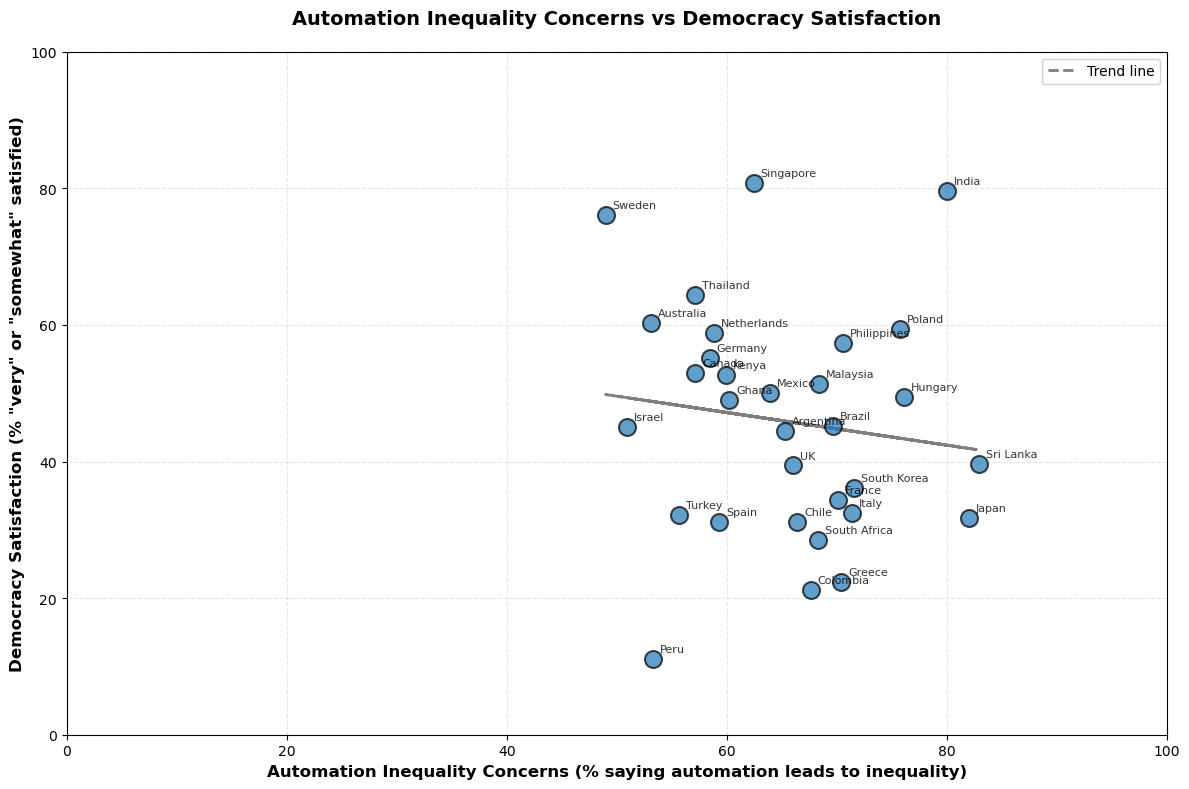

SUMMARY STATISTICS (Weighted Proportions)

Number of countries: 31

Automation Inequality Concerns (% saying it leads to inequality):
  Mean: 65.2%
  Range: 49.0% - 83.0%

Democracy Satisfaction (% 'very' or 'somewhat' satisfied):
  Mean: 45.9%
  Range: 11.1% - 80.8%

Spearman Correlation: -0.181 (p-value: 0.3286)
  ✗ No statistically significant correlation.
  This suggests automation inequality concerns and democracy satisfaction are independent.


In [334]:
# Scatterplot: Automation Inequality Concerns vs Democracy Satisfaction
# Testing: Do countries with automation anxiety differ in their satisfaction with democracy?

# Filter to valid responses
valid_data = pew[
    pew['inequality_automation'].isin(['1', '2', '3', '4']) & 
    pew['satisfied_democracy'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'inequality_automation', 'satisfied_democracy'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Automation inequality: % who say automation leads to inequality (1 or 2)
    automation_inequality = country_data[country_data['inequality_automation'].isin(['1', '2'])]['weight'].sum()
    automation_inequality_pct = (automation_inequality / total_weight) * 100
    
    # Democracy satisfaction: % who are "very" or "somewhat" satisfied (1 or 2)
    satisfied_democracy = country_data[country_data['satisfied_democracy'].isin(['1', '2'])]['weight'].sum()
    satisfied_democracy_pct = (satisfied_democracy / total_weight) * 100
    
    country_stats[country] = {
        'automation_inequality_pct': automation_inequality_pct,
        'satisfied_democracy_pct': satisfied_democracy_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points
ax.scatter(plot_df['automation_inequality_pct'], 
           plot_df['satisfied_democracy_pct'], 
           s=150, alpha=0.7, edgecolors='black', linewidth=1.5, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'automation_inequality_pct'], 
                 plot_df.loc[country, 'satisfied_democracy_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Add trend line
z = np.polyfit(plot_df['automation_inequality_pct'], 
               plot_df['satisfied_democracy_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['automation_inequality_pct'], 
        p(plot_df['automation_inequality_pct']), 
        "k--", alpha=0.5, linewidth=2, label='Trend line', zorder=2)

# Customize axes
ax.set_xlabel('Automation Inequality Concerns (% saying automation leads to inequality)', 
              fontsize=12, fontweight='bold')
ax.set_ylabel('Democracy Satisfaction (% "very" or "somewhat" satisfied)', 
              fontsize=12, fontweight='bold')
ax.set_title('Automation Inequality Concerns vs Democracy Satisfaction',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='best', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("SUMMARY STATISTICS (Weighted Proportions)")
print("="*70)
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nAutomation Inequality Concerns (% saying it leads to inequality):")
print(f"  Mean: {plot_df['automation_inequality_pct'].mean():.1f}%")
print(f"  Range: {plot_df['automation_inequality_pct'].min():.1f}% - {plot_df['automation_inequality_pct'].max():.1f}%")
print(f"\nDemocracy Satisfaction (% 'very' or 'somewhat' satisfied):")
print(f"  Mean: {plot_df['satisfied_democracy_pct'].mean():.1f}%")
print(f"  Range: {plot_df['satisfied_democracy_pct'].min():.1f}% - {plot_df['satisfied_democracy_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['automation_inequality_pct'], 
                                 plot_df['satisfied_democracy_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  ✓ Statistically significant correlation!")
    if correlation > 0:
        print("  Countries with higher automation inequality concerns tend to be more satisfied with democracy.")
    else:
        print("  Countries with higher automation inequality concerns tend to be less satisfied with democracy.")
else:
    print("  ✗ No statistically significant correlation.")
    print("  This suggests automation inequality concerns and democracy satisfaction are independent.")

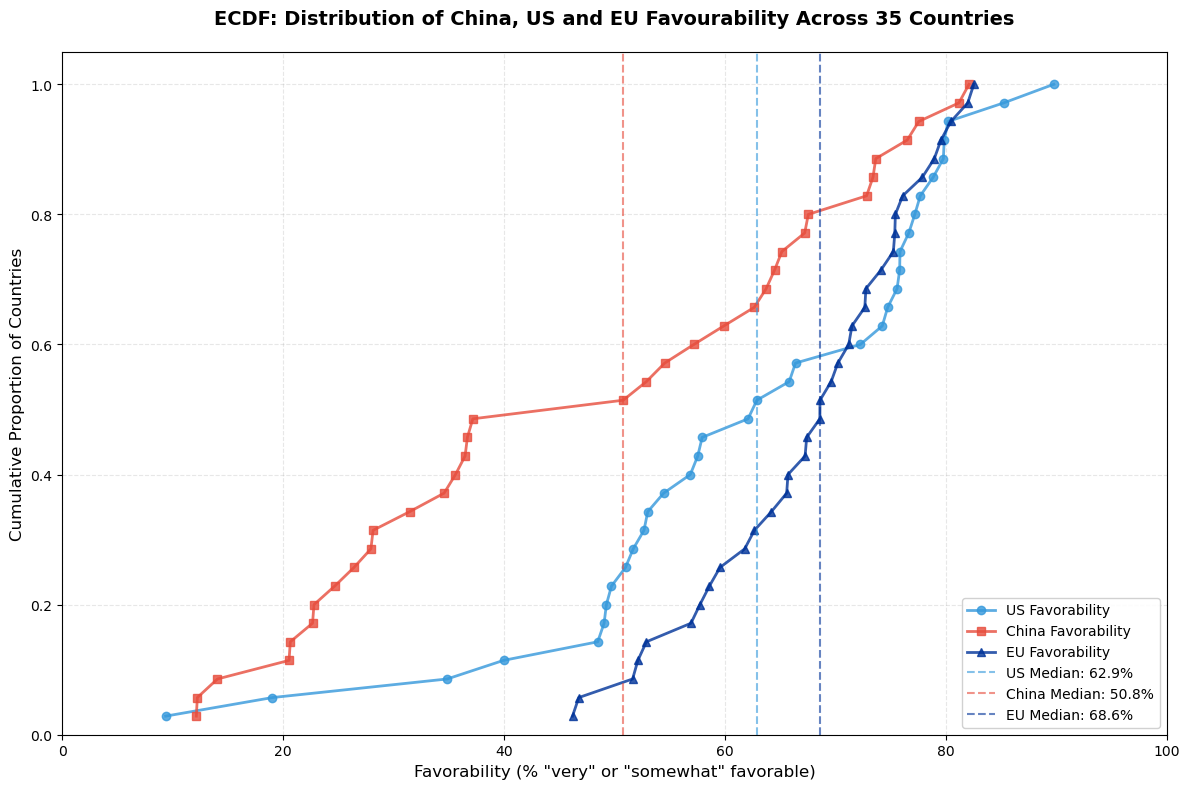

ECDF INTERPRETATION

The ECDF shows the cumulative proportion of countries at or below each favorability level.

Key Observations:

1. Median Comparison:
   US Median: 62.9%
   China Median: 50.8%
   EU Median: 68.6%
   US-China Difference: 12.1 percentage points
   EU-China Difference: 17.8 percentage points
   US-EU Difference: -5.7 percentage points

2. Distribution Shape:
   US Favorability - Range: 9.3% to 89.8%
   China Favorability - Range: 12.1% to 82.1%
   EU Favorability - Range: 46.2% to 82.5%

3. Percentile Comparison:
   25th percentile: US = 51.3%, China = 27.2%, EU = 60.7%
   50th percentile: US = 62.9%, China = 50.8%, EU = 68.6%
   75th percentile: US = 76.2%, China = 66.2%, EU = 75.3%

4. Distribution Comparison (Kolmogorov-Smirnov Test):

   US vs China:
   KS Statistic: 0.400, p-value: 0.0069
   ✓ Significantly different distributions

   US vs EU:
   KS Statistic: 0.257, p-value: 0.1991
   ✗ Not significantly different

   China vs EU:
   KS Statistic: 0.486, p-valu

In [340]:
# ECDF (Empirical Cumulative Distribution Function) Comparison
# Comparing the distribution of US favorability vs China favorability vs EU favorability across countries
# ECDF shows the cumulative proportion of countries at or below each favorability level

# Filter to valid responses for all three variables
valid_data = pew[
    pew['fav_us'].isin(['1', '2', '3', '4']) & 
    pew['fav_china'].isin(['1', '2', '3', '4']) &
    pew['fav_eu'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_us', 'fav_china', 'fav_eu'])

country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_us_favorable = country_data[country_data['fav_us'].isin(['1', '2'])]['weight'].sum()
    fav_us_favorable_pct = (fav_us_favorable / total_weight) * 100
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    fav_eu_favorable = country_data[country_data['fav_eu'].isin(['1', '2'])]['weight'].sum()
    fav_eu_favorable_pct = (fav_eu_favorable / total_weight) * 100
    
    country_stats[country] = {
        'fav_us_favorable_pct': fav_us_favorable_pct,
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'fav_eu_favorable_pct': fav_eu_favorable_pct
    }
plot_df = pd.DataFrame(country_stats).T

# Create ECDF function
def ecdf(data):
    """Compute ECDF for a one-dimensional array of measurements."""
    n = len(data)
    x = np.sort(data)
    y = np.arange(1, n+1) / n
    return x, y

# Compute ECDFs for all three variables
x_us, y_us = ecdf(plot_df['fav_us_favorable_pct'])
x_china, y_china = ecdf(plot_df['fav_china_favorable_pct'])
x_eu, y_eu = ecdf(plot_df['fav_eu_favorable_pct'])

# Create ECDF plot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot ECDFs
ax.plot(x_us, y_us, marker='o', linestyle='-', linewidth=2, markersize=6,
        label='US Favorability', color='#3498db', alpha=0.8)
ax.plot(x_china, y_china, marker='s', linestyle='-', linewidth=2, markersize=6,
        label='China Favorability', color='#e74c3c', alpha=0.8)
ax.plot(x_eu, y_eu, marker='^', linestyle='-', linewidth=2, markersize=6,
        label='EU Favorability', color='#003399', alpha=0.8)

# Add median lines
median_us = plot_df['fav_us_favorable_pct'].median()
median_china = plot_df['fav_china_favorable_pct'].median()
median_eu = plot_df['fav_eu_favorable_pct'].median()

ax.axvline(median_us, color='#3498db', linestyle='--', linewidth=1.5, alpha=0.6, label=f'US Median: {median_us:.1f}%')
ax.axvline(median_china, color='#e74c3c', linestyle='--', linewidth=1.5, alpha=0.6, label=f'China Median: {median_china:.1f}%')
ax.axvline(median_eu, color='#003399', linestyle='--', linewidth=1.5, alpha=0.6, label=f'EU Median: {median_eu:.1f}%')

ax.set_xlabel('Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Cumulative Proportion of Countries', fontsize=12)
ax.set_title('ECDF: Distribution of China, US and EU Favourability Across 35 Countries',
             fontsize=14, fontweight='bold', pad=20)

# After your plot lines, modify the legend section:

# Get handles and labels from the plot
# handles, labels = ax.get_legend_handles_labels()

# Reorder: China, US, EU
# order = [1, 0, 2]  # China (index 1), US (index 0), EU (index 2)
#handles_ordered = [handles[i] for i in order]
# labels_ordered = [labels[i] for i in order]

# ax.legend(handles_ordered, labels_ordered, loc='lower right', framealpha=0.9, fontsize=10)

ax.legend(loc='lower right', framealpha=0.9, fontsize=10)

ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

# Print interpretation
print("="*70)
print("ECDF INTERPRETATION")
print("="*70)
print(f"\nThe ECDF shows the cumulative proportion of countries at or below each favorability level.")
print(f"\nKey Observations:")
print(f"\n1. Median Comparison:")
print(f"   US Median: {median_us:.1f}%")
print(f"   China Median: {median_china:.1f}%")
print(f"   EU Median: {median_eu:.1f}%")
print(f"   US-China Difference: {median_us - median_china:.1f} percentage points")
print(f"   EU-China Difference: {median_eu - median_china:.1f} percentage points")
print(f"   US-EU Difference: {median_us - median_eu:.1f} percentage points")

print(f"\n2. Distribution Shape:")
print(f"   US Favorability - Range: {plot_df['fav_us_favorable_pct'].min():.1f}% to {plot_df['fav_us_favorable_pct'].max():.1f}%")
print(f"   China Favorability - Range: {plot_df['fav_china_favorable_pct'].min():.1f}% to {plot_df['fav_china_favorable_pct'].max():.1f}%")
print(f"   EU Favorability - Range: {plot_df['fav_eu_favorable_pct'].min():.1f}% to {plot_df['fav_eu_favorable_pct'].max():.1f}%")

# Calculate percentiles for comparison
percentiles = [25, 50, 75]
print(f"\n3. Percentile Comparison:")
for p in percentiles:
    p_us = np.percentile(plot_df['fav_us_favorable_pct'], p)
    p_china = np.percentile(plot_df['fav_china_favorable_pct'], p)
    p_eu = np.percentile(plot_df['fav_eu_favorable_pct'], p)
    print(f"   {p}th percentile: US = {p_us:.1f}%, China = {p_china:.1f}%, EU = {p_eu:.1f}%")

# Statistical tests: Kolmogorov-Smirnov test to compare distributions
from scipy.stats import ks_2samp
ks_stat_us_china, ks_p_us_china = ks_2samp(plot_df['fav_us_favorable_pct'], 
                                           plot_df['fav_china_favorable_pct'])
ks_stat_us_eu, ks_p_us_eu = ks_2samp(plot_df['fav_us_favorable_pct'], 
                                     plot_df['fav_eu_favorable_pct'])
ks_stat_china_eu, ks_p_china_eu = ks_2samp(plot_df['fav_china_favorable_pct'], 
                                           plot_df['fav_eu_favorable_pct'])

print(f"\n4. Distribution Comparison (Kolmogorov-Smirnov Test):")
print(f"\n   US vs China:")
print(f"   KS Statistic: {ks_stat_us_china:.3f}, p-value: {ks_p_us_china:.4f}")
if ks_p_us_china < 0.05:
    print(f"   ✓ Significantly different distributions")
else:
    print(f"   ✗ Not significantly different")

print(f"\n   US vs EU:")
print(f"   KS Statistic: {ks_stat_us_eu:.3f}, p-value: {ks_p_us_eu:.4f}")
if ks_p_us_eu < 0.05:
    print(f"   ✓ Significantly different distributions")
else:
    print(f"   ✗ Not significantly different")

print(f"\n   China vs EU:")
print(f"   KS Statistic: {ks_stat_china_eu:.3f}, p-value: {ks_p_china_eu:.4f}")
if ks_p_china_eu < 0.05:
    print(f"   ✓ Significantly different distributions")
else:
    print(f"   ✗ Not significantly different")

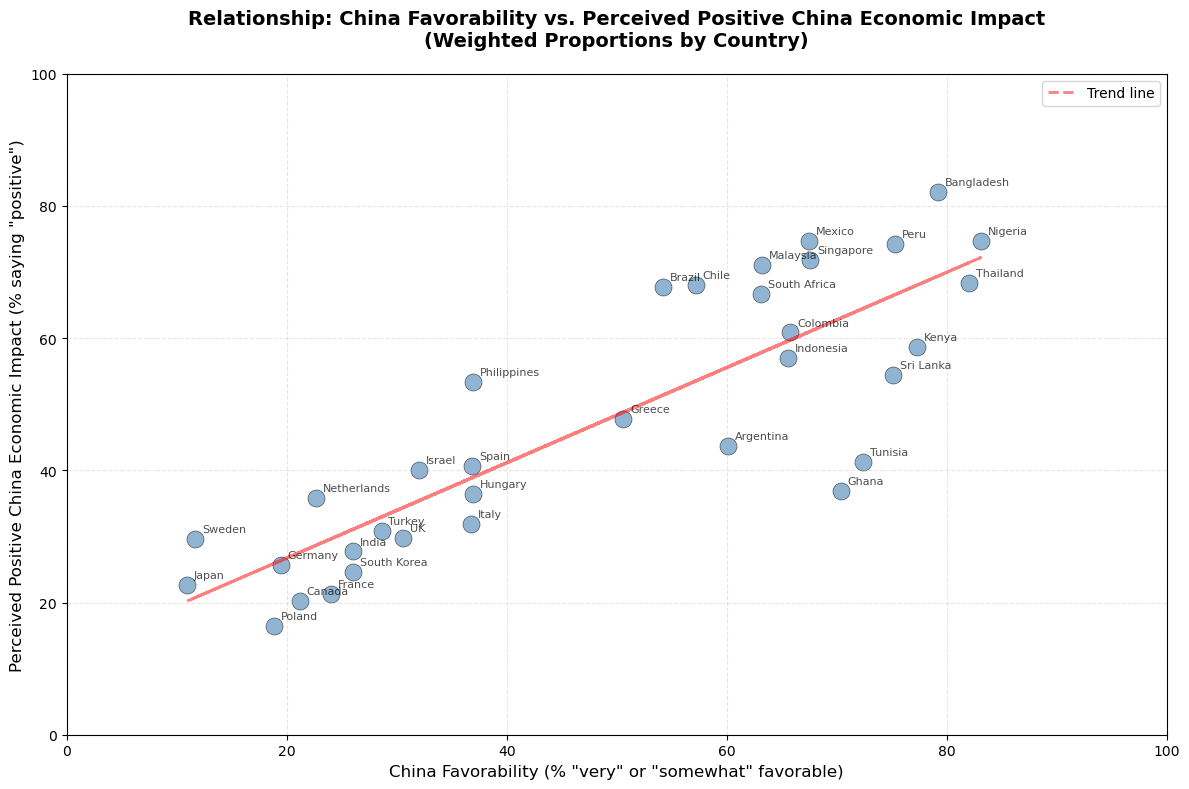

Summary Statistics (Weighted Proportions):

Number of countries: 34

China Favorability (% favorable):
  Mean: 48.5%
  Range: 10.9% - 83.1%

Perceived Positive China Economic Impact (% saying positive):
  Mean: 47.3%
  Range: 16.5% - 82.2%

Perceived Negative China Economic Impact (% saying negative):
  Mean: 46.1%
  Range: 16.0% - 78.4%

Perceived Neither/Both (% saying neither/both):
  Mean: 6.7%
  Range: 0.5% - 31.4%

Spearman Correlation (China Favorability vs. Positive Impact): 0.864 (p-value: 0.0000)
  Statistically significant correlation!
  Positive correlation: More favorable views of China → More likely to see China's impact as positive
  This makes intuitive sense: favorable views align with positive economic perceptions

Spearman Correlation (China Favorability vs. Negative Impact): -0.821 (p-value: 0.0000)
  Statistically significant correlation!
  Negative correlation: More favorable views of China → Less likely to see China's impact as negative
  This makes intuitive sen

In [329]:
# Scatterplot: fav_china vs china_influ_econ2 (Positive vs Negative Economic Impact)
# Testing: Do countries with favorable views of China differ in whether they see China's economic influence as positive or negative?
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses
# Note: china_influ_econ2 is only asked if they answered 1, 2, or 3 to china_influ_econ
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['china_influ_econ2'].isin(['1', '2', '3'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'china_influ_econ2'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_china: % who are favorable (1 or 2: very/somewhat favorable)
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    # For china_influ_econ2: % who see it as positive (1), negative (2), or neither/both (3)
    china_positive = country_data[country_data['china_influ_econ2'] == '1']['weight'].sum()
    china_negative = country_data[country_data['china_influ_econ2'] == '2']['weight'].sum()
    china_neither = country_data[country_data['china_influ_econ2'] == '3']['weight'].sum()
    
    china_positive_pct = (china_positive / total_weight) * 100
    china_negative_pct = (china_negative / total_weight) * 100
    china_neither_pct = (china_neither / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'china_positive_pct': china_positive_pct,
        'china_negative_pct': china_negative_pct,
        'china_neither_pct': china_neither_pct
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Create scatterplot - comparing China favorability with % seeing China's influence as POSITIVE
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df['fav_china_favorable_pct'], 
           plot_df['china_positive_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'fav_china_favorable_pct'], 
                 plot_df.loc[country, 'china_positive_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line
from scipy import stats
z = np.polyfit(plot_df['fav_china_favorable_pct'], 
               plot_df['china_positive_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['fav_china_favorable_pct'], 
        p(plot_df['fav_china_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('China Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Perceived Positive China Economic Impact (% saying "positive")', fontsize=12)
ax.set_title('Relationship: China Favorability vs. Perceived Positive China Economic Impact\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nChina Favorability (% favorable):")
print(f"  Mean: {plot_df['fav_china_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df['fav_china_favorable_pct'].min():.1f}% - {plot_df['fav_china_favorable_pct'].max():.1f}%")
print(f"\nPerceived Positive China Economic Impact (% saying positive):")
print(f"  Mean: {plot_df['china_positive_pct'].mean():.1f}%")
print(f"  Range: {plot_df['china_positive_pct'].min():.1f}% - {plot_df['china_positive_pct'].max():.1f}%")
print(f"\nPerceived Negative China Economic Impact (% saying negative):")
print(f"  Mean: {plot_df['china_negative_pct'].mean():.1f}%")
print(f"  Range: {plot_df['china_negative_pct'].min():.1f}% - {plot_df['china_negative_pct'].max():.1f}%")
print(f"\nPerceived Neither/Both (% saying neither/both):")
print(f"  Mean: {plot_df['china_neither_pct'].mean():.1f}%")
print(f"  Range: {plot_df['china_neither_pct'].min():.1f}% - {plot_df['china_neither_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['fav_china_favorable_pct'], 
                                 plot_df['china_positive_pct'])
print(f"\nSpearman Correlation (China Favorability vs. Positive Impact): {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
    if correlation > 0:
        print("  Positive correlation: More favorable views of China → More likely to see China's impact as positive")
        print("  This makes intuitive sense: favorable views align with positive economic perceptions")
    else:
        print("  Negative correlation: More favorable views of China → Less likely to see China's impact as positive")
        print("  This is counterintuitive and suggests complex perceptions")
else:
    print("  No statistically significant correlation.")
    print("  This suggests that general favorability and economic impact perceptions may operate independently")

# Also calculate correlation with negative perception
correlation_neg, p_value_neg = spearmanr(plot_df['fav_china_favorable_pct'], 
                                         plot_df['china_negative_pct'])
print(f"\nSpearman Correlation (China Favorability vs. Negative Impact): {correlation_neg:.3f} (p-value: {p_value_neg:.4f})")
if p_value_neg < 0.05:
    print("  Statistically significant correlation!")
    if correlation_neg < 0:
        print("  Negative correlation: More favorable views of China → Less likely to see China's impact as negative")
        print("  This makes intuitive sense: favorable views align with less negative economic perceptions")
    else:
        print("  Positive correlation: More favorable views of China → More likely to see China's impact as negative")
        print("  This is counterintuitive and suggests complex or ambivalent perceptions")
else:
    print("  No statistically significant correlation.")

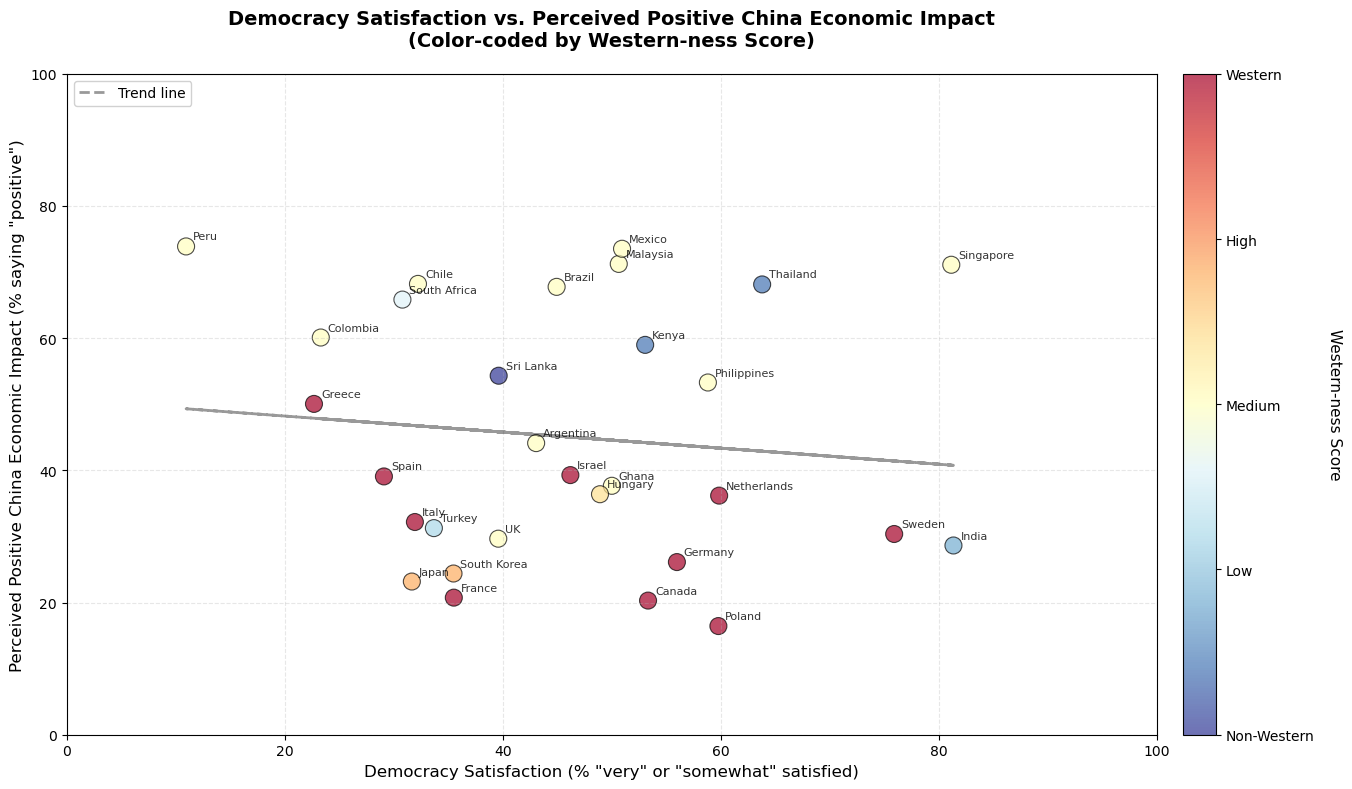

Summary Statistics (Weighted Proportions):

Number of countries: 30

Democracy Satisfaction (% satisfied):
  Mean: 45.8%
  Range: 10.9% - 81.3%

Perceived Positive China Economic Impact (% saying positive):
  Mean: 45.1%
  Range: 16.4% - 73.9%

Spearman Correlation: -0.128 (p-value: 0.5005)
  No statistically significant correlation.
  This suggests that democracy satisfaction and perceptions of China's economic impact are independent


In [130]:
# Enhanced Scatterplot: china_influ_econ2 vs satisfied_democracy with Western-ness Gradient
# Color-coding each country by "Western-ness" score with gradient colorbar

# First, let's define a "Western-ness" score for each country
# You can adjust these classifications based on your theoretical framework
western_ness_scores = {
    # Most Western (score = 1.0)
    'United States': 1.0,
    'Canada': 1.0,
    'United Kingdom': 1.0,
    'France': 1.0,
    'Germany': 1.0,
    'Italy': 1.0,
    'Spain': 1.0,
    'Netherlands': 1.0,
    'Sweden': 1.0,
    'Poland': 1.0,
    'Greece': 1.0,
    'Australia': 1.0,
    'Israel': 1.0,  # You might want to adjust this
    
    # Moderately Western (score = 0.6-0.8)
    'South Korea': 0.7,
    'Japan': 0.7,
    'Brazil': 0.5,
    'Mexico': 0.5,
    'Argentina': 0.5,
    'Chile': 0.5,
    'South Africa': 0.4,
    'Turkey': 0.3,
    
    # Less Western / Non-Western (score = 0.0-0.3)
    'India': 0.2,
    'Indonesia': 0.1,
    'Philippines': 0.5,
    'Vietnam': 0.1,
    'Thailand': 0.1,
    'Bangladesh': 0.0,
    'Sri Lanka': 0.0,
    'Pakistan': 0.0,
    'Nigeria': 0.1,
    'Kenya': 0.1,
    'Tunisia': 0.2,
    'Lebanon': 0.2,
    'Jordan': 0.1,
    'China': 0.0,  # If included
    'Russia': 0.1,
    'Ukraine': 0.3,
    'Hungary': 0.6,
}

# Filter to valid responses
valid_data = pew[
    pew['china_influ_econ2'].isin(['1', '2', '3']) & 
    pew['satisfied_democracy'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'china_influ_econ2', 'satisfied_democracy'])

country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For china_influ_econ2: % who see it as positive (1)
    china_positive = country_data[country_data['china_influ_econ2'] == '1']['weight'].sum()
    china_positive_pct = (china_positive / total_weight) * 100
    
    # For satisfied_democracy: % who are satisfied (1 or 2: very/somewhat satisfied)
    satisfied_democracy_satisfied = country_data[country_data['satisfied_democracy'].isin(['1', '2'])]['weight'].sum()
    satisfied_democracy_pct = (satisfied_democracy_satisfied / total_weight) * 100
    
    # Get Western-ness score (default to 0.5 if not found)
    western_score = western_ness_scores.get(country, 0.5)
    
    country_stats[country] = {
        'china_positive_pct': china_positive_pct,
        'satisfied_democracy_pct': satisfied_democracy_pct,
        'western_ness': western_score
    }

plot_df = pd.DataFrame(country_stats).T

# Create scatterplot with gradient coloring
fig, ax = plt.subplots(figsize=(14, 8))

# Use a colormap - 'coolwarm' or 'RdYlBu_r' works well (red=Western, blue=Non-Western)
scatter = ax.scatter(plot_df['satisfied_democracy_pct'], 
                     plot_df['china_positive_pct'], 
                     c=plot_df['western_ness'],
                     s=150, alpha=0.7, edgecolors='black', linewidth=0.8,
                     cmap='RdYlBu_r',  # Red (Western) to Blue (Non-Western)
                     vmin=0, vmax=1)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'satisfied_democracy_pct'], 
                 plot_df.loc[country, 'china_positive_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional)
z = np.polyfit(plot_df['satisfied_democracy_pct'], 
               plot_df['china_positive_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['satisfied_democracy_pct'], 
        p(plot_df['satisfied_democracy_pct']), 
        "k--", alpha=0.4, linewidth=2, label='Trend line')

# Add colorbar on the right
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Western-ness Score', fontsize=11, rotation=270, labelpad=20)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['Non-Western', 'Low', 'Medium', 'High', 'Western'])

ax.set_xlabel('Democracy Satisfaction (% "very" or "somewhat" satisfied)', fontsize=12)
ax.set_ylabel('Perceived Positive China Economic Impact (% saying "positive")', fontsize=12)
ax.set_title('Democracy Satisfaction vs. Perceived Positive China Economic Impact\n(Color-coded by Western-ness Score)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nDemocracy Satisfaction (% satisfied):")
print(f"  Mean: {plot_df['satisfied_democracy_pct'].mean():.1f}%")
print(f"  Range: {plot_df['satisfied_democracy_pct'].min():.1f}% - {plot_df['satisfied_democracy_pct'].max():.1f}%")
print(f"\nPerceived Positive China Economic Impact (% saying positive):")
print(f"  Mean: {plot_df['china_positive_pct'].mean():.1f}%")
print(f"  Range: {plot_df['china_positive_pct'].min():.1f}% - {plot_df['china_positive_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['satisfied_democracy_pct'], 
                                 plot_df['china_positive_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
    if correlation < 0:
        print("  Negative correlation: More satisfied with democracy → Less likely to see China's impact as positive")
        print("  This suggests that democratic satisfaction may relate to viewing China's economic role more critically")
    else:
        print("  Positive correlation: More satisfied with democracy → More likely to see China's impact as positive")
        print("  This suggests that democratic satisfaction and positive views of China's economy can coexist")
else:
    print("  No statistically significant correlation.")
    print("  This suggests that democracy satisfaction and perceptions of China's economic impact are independent")

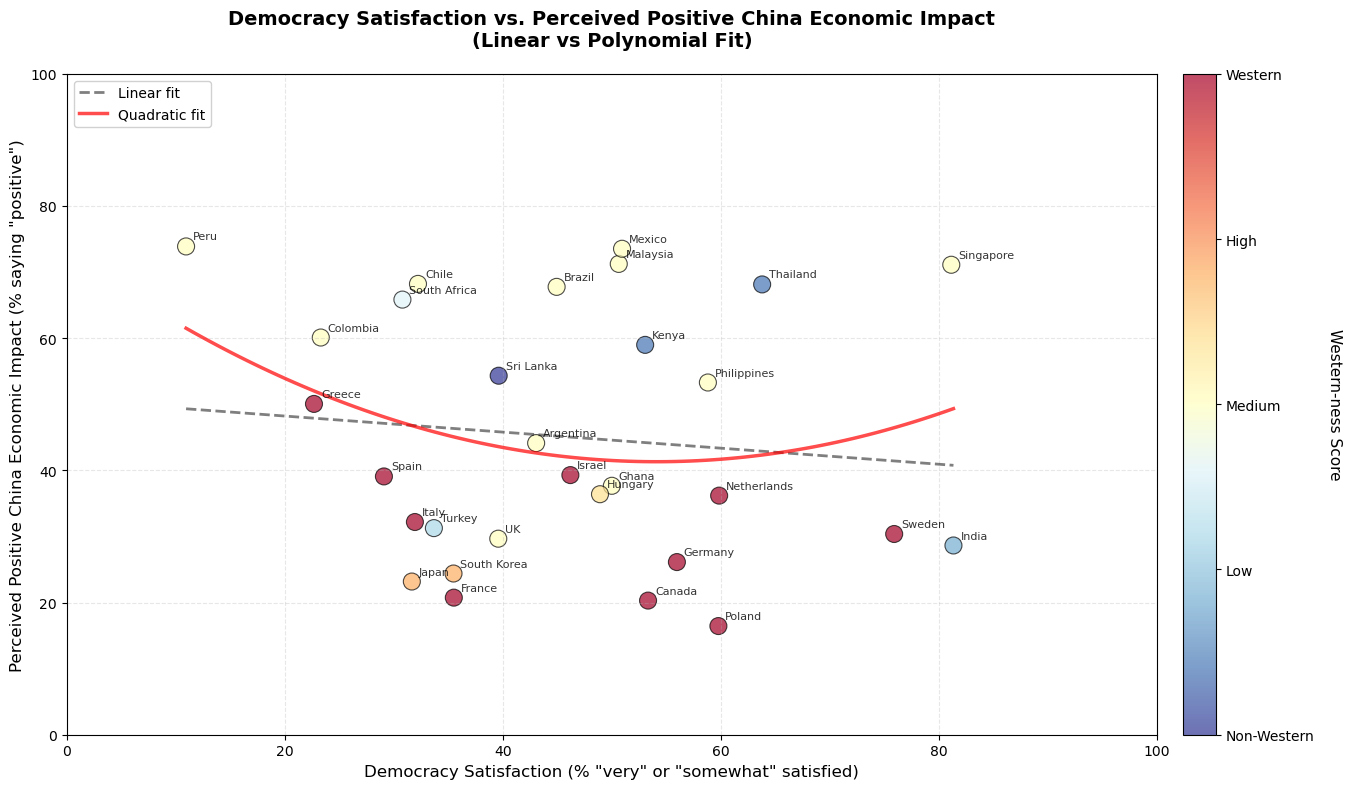

LINEAR vs POLYNOMIAL FIT COMPARISON

Linear Model (y = -0.121x + 50.644):
  R-squared: 0.0120
  RSS (Residual Sum of Squares): 10140.13

Quadratic Model (y = 0.011x² + -1.172x + 73.023):
  R-squared: 0.0569
  RSS (Residual Sum of Squares): 9679.31

Model Comparison (F-test):
  F-statistic: 1.285
  p-value: 0.2669
  ✗ Quadratic model does not fit significantly better than linear.
  Linear relationship is sufficient.

Spearman Correlation (non-parametric): -0.128 (p-value: 0.5005)
  ✗ No statistically significant monotonic relationship
  This suggests that democracy satisfaction and perceptions of China's economic impact are independent


In [336]:
# Enhanced Scatterplot: china_influ_econ2 vs satisfied_democracy with Western-ness Gradient
# Testing for non-linear (polynomial) relationships

# First, let's define a "Western-ness" score for each country
western_ness_scores = {
    # Most Western (score = 1.0)
    'United States': 1.0,
    'Canada': 1.0,
    'United Kingdom': 1.0,
    'France': 1.0,
    'Germany': 1.0,
    'Italy': 1.0,
    'Spain': 1.0,
    'Netherlands': 1.0,
    'Sweden': 1.0,
    'Poland': 1.0,
    'Greece': 1.0,
    'Australia': 1.0,
    'Israel': 1.0,
    
    # Moderately Western (score = 0.6-0.8)
    'South Korea': 0.7,
    'Japan': 0.7,
    'Brazil': 0.5,
    'Mexico': 0.5,
    'Argentina': 0.5,
    'Chile': 0.5,
    'South Africa': 0.4,
    'Turkey': 0.3,
    
    # Less Western / Non-Western (score = 0.0-0.3)
    'India': 0.2,
    'Indonesia': 0.1,
    'Philippines': 0.5,
    'Thailand': 0.1,
    'Bangladesh': 0.0,
    'Sri Lanka': 0.0,
    'Nigeria': 0.1,
    'Kenya': 0.1,
    'Tunisia': 0.2,
    'Hungary': 0.6,
}

# Filter to valid responses
valid_data = pew[
    pew['china_influ_econ2'].isin(['1', '2', '3']) & 
    pew['satisfied_democracy'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'china_influ_econ2', 'satisfied_democracy'])

country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For china_influ_econ2: % who see it as positive (1)
    china_positive = country_data[country_data['china_influ_econ2'] == '1']['weight'].sum()
    china_positive_pct = (china_positive / total_weight) * 100
    
    # For satisfied_democracy: % who are satisfied (1 or 2: very/somewhat satisfied)
    satisfied_democracy_satisfied = country_data[country_data['satisfied_democracy'].isin(['1', '2'])]['weight'].sum()
    satisfied_democracy_pct = (satisfied_democracy_satisfied / total_weight) * 100
    
    # Get Western-ness score (default to 0.5 if not found)
    western_score = western_ness_scores.get(country, 0.5)
    
    country_stats[country] = {
        'china_positive_pct': china_positive_pct,
        'satisfied_democracy_pct': satisfied_democracy_pct,
        'western_ness': western_score
    }

plot_df = pd.DataFrame(country_stats).T

# Create scatterplot with gradient coloring
fig, ax = plt.subplots(figsize=(14, 8))

# Use a colormap - 'RdYlBu_r' works well (red=Western, blue=Non-Western)
scatter = ax.scatter(plot_df['satisfied_democracy_pct'], 
                     plot_df['china_positive_pct'], 
                     c=plot_df['western_ness'],
                     s=150, alpha=0.7, edgecolors='black', linewidth=0.8,
                     cmap='RdYlBu_r',  # Red (Western) to Blue (Non-Western)
                     vmin=0, vmax=1)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'satisfied_democracy_pct'], 
                 plot_df.loc[country, 'china_positive_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points')

# Fit linear and polynomial models
x = plot_df['satisfied_democracy_pct'].values
y = plot_df['china_positive_pct'].values

# Linear fit (degree 1)
linear_coefs = np.polyfit(x, y, 1)
linear_poly = np.poly1d(linear_coefs)
x_line = np.linspace(x.min(), x.max(), 100)
y_linear = linear_poly(x_line)

# Polynomial fit (degree 2 - quadratic)
poly_coefs = np.polyfit(x, y, 2)
poly_poly = np.poly1d(poly_coefs)
y_poly = poly_poly(x_line)

# Plot both fits
ax.plot(x_line, y_linear, "k--", alpha=0.5, linewidth=2, label='Linear fit', zorder=2)
ax.plot(x_line, y_poly, "r-", alpha=0.7, linewidth=2.5, label='Quadratic fit', zorder=2)

# Calculate R-squared for both models
from sklearn.metrics import r2_score

y_pred_linear = linear_poly(x)
y_pred_poly = poly_poly(x)

r2_linear = r2_score(y, y_pred_linear)
r2_poly = r2_score(y, y_pred_poly)

# F-test to compare models
from scipy.stats import f
n = len(x)
p_linear = 2  # number of parameters in linear model
p_poly = 3    # number of parameters in quadratic model

# Residual sum of squares
rss_linear = np.sum((y - y_pred_linear)**2)
rss_poly = np.sum((y - y_pred_poly)**2)

# F-statistic
f_stat = ((rss_linear - rss_poly) / (p_poly - p_linear)) / (rss_poly / (n - p_poly))
f_pvalue = 1 - f.cdf(f_stat, p_poly - p_linear, n - p_poly)

# Add colorbar on the right
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Western-ness Score', fontsize=11, rotation=270, labelpad=20)
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels(['Non-Western', 'Low', 'Medium', 'High', 'Western'])

ax.set_xlabel('Democracy Satisfaction (% "very" or "somewhat" satisfied)', fontsize=12)
ax.set_ylabel('Perceived Positive China Economic Impact (% saying "positive")', fontsize=12)
ax.set_title('Democracy Satisfaction vs. Perceived Positive China Economic Impact\n(Linear vs Polynomial Fit)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("LINEAR vs POLYNOMIAL FIT COMPARISON")
print("="*70)
print(f"\nLinear Model (y = {linear_coefs[0]:.3f}x + {linear_coefs[1]:.3f}):")
print(f"  R-squared: {r2_linear:.4f}")
print(f"  RSS (Residual Sum of Squares): {rss_linear:.2f}")

print(f"\nQuadratic Model (y = {poly_coefs[0]:.3f}x² + {poly_coefs[1]:.3f}x + {poly_coefs[2]:.3f}):")
print(f"  R-squared: {r2_poly:.4f}")
print(f"  RSS (Residual Sum of Squares): {rss_poly:.2f}")

print(f"\nModel Comparison (F-test):")
print(f"  F-statistic: {f_stat:.3f}")
print(f"  p-value: {f_pvalue:.4f}")
if f_pvalue < 0.05:
    print(f"  ✓ Quadratic model fits significantly better than linear!")
    print(f"  This suggests a non-linear relationship.")
else:
    print(f"  ✗ Quadratic model does not fit significantly better than linear.")
    print(f"  Linear relationship is sufficient.")

# Spearman correlation (non-parametric, doesn't assume linearity)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(x, y)
print(f"\nSpearman Correlation (non-parametric): {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  ✓ Statistically significant monotonic relationship")
    if correlation < 0:
        print("  Negative correlation: More satisfied with democracy → Less likely to see China's impact as positive")
    else:
        print("  Positive correlation: More satisfied with democracy → More likely to see China's impact as positive")
else:
    print("  ✗ No statistically significant monotonic relationship")
    print("  This suggests that democracy satisfaction and perceptions of China's economic impact are independent")

- While social identity theory might predict oppositional views (favoring in-group US → disfavoring out-group China), the data reveals a more complex pattern. The Kolmogorov-Smirnov test shows significantly different distributions (KS = 0.400, p = 0.0069), yet no significant correlation (r = 0.256, p = 0.1381). This suggests that views of US and China are structured differently across countries but operate independently rather than in opposition. The largest gap occurs at lower favorability levels (25th percentile: 24.7pp), suggesting that countries with low favorability for one power don't necessarily compensate by favoring the other—both may be viewed unfavorably. This challenges simplistic in-group/out-group dynamics and suggests more nuanced cross-national perceptions.

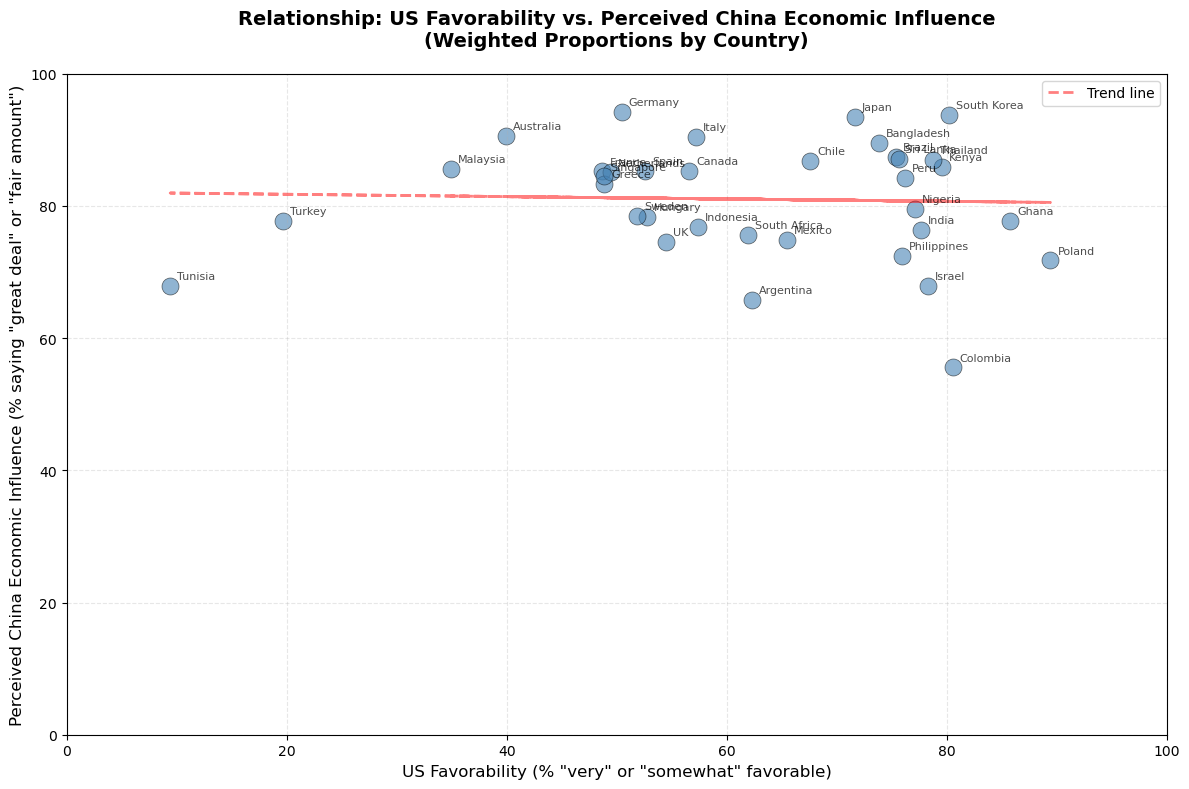

Summary Statistics (Weighted Proportions):

Number of countries: 35

US Favorability (% favorable):
  Mean: 61.9%
  Range: 9.4% - 89.4%

Perceived China Economic Influence (% saying China has influence):
  Mean: 81.0%
  Range: 55.6% - 94.2%

Spearman Correlation: -0.120 (p-value: 0.4937)
  No statistically significant correlation.
  This suggests views of US and perceptions of China's economic influence are independent


In [76]:
# Scatterplot: fav_us vs china_influ_econ
# Testing: Do countries with favorable views of US differ in how they perceive China's economic influence?
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['fav_us'].isin(['1', '2', '3', '4']) & 
    pew['china_influ_econ'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_us', 'china_influ_econ'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_us: % who are favorable (1 or 2: very/somewhat favorable)
    fav_us_favorable = country_data[country_data['fav_us'].isin(['1', '2'])]['weight'].sum()
    fav_us_favorable_pct = (fav_us_favorable / total_weight) * 100
    
    # For china_influ_econ: % who say China has "a great deal" or "a fair amount" of influence (1 or 2)
    china_econ_influence = country_data[country_data['china_influ_econ'].isin(['1', '2'])]['weight'].sum()
    china_econ_influence_pct = (china_econ_influence / total_weight) * 100
    
    country_stats[country] = {
        'fav_us_favorable_pct': fav_us_favorable_pct,
        'china_econ_influence_pct': china_econ_influence_pct
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df['fav_us_favorable_pct'], 
           plot_df['china_econ_influence_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'fav_us_favorable_pct'], 
                 plot_df.loc[country, 'china_econ_influence_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line
from scipy import stats
z = np.polyfit(plot_df['fav_us_favorable_pct'], 
               plot_df['china_econ_influence_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['fav_us_favorable_pct'], 
        p(plot_df['fav_us_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('US Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Perceived China Economic Influence (% saying "great deal" or "fair amount")', fontsize=12)
ax.set_title('Relationship: US Favorability vs. Perceived China Economic Influence\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nUS Favorability (% favorable):")
print(f"  Mean: {plot_df['fav_us_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df['fav_us_favorable_pct'].min():.1f}% - {plot_df['fav_us_favorable_pct'].max():.1f}%")
print(f"\nPerceived China Economic Influence (% saying China has influence):")
print(f"  Mean: {plot_df['china_econ_influence_pct'].mean():.1f}%")
print(f"  Range: {plot_df['china_econ_influence_pct'].min():.1f}% - {plot_df['china_econ_influence_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['fav_us_favorable_pct'], 
                                 plot_df['china_econ_influence_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
    if correlation < 0:
        print("  Negative correlation: More favorable views of US → Less perceived China economic influence")
        print("  This could suggest that US-favorable countries downplay China's economic role")
    else:
        print("  Positive correlation: More favorable views of US → More perceived China economic influence")
        print("  This could suggest that US-favorable countries acknowledge China's economic presence")
else:
    print("  No statistically significant correlation.")
    print("  This suggests views of US and perceptions of China's economic influence are independent")

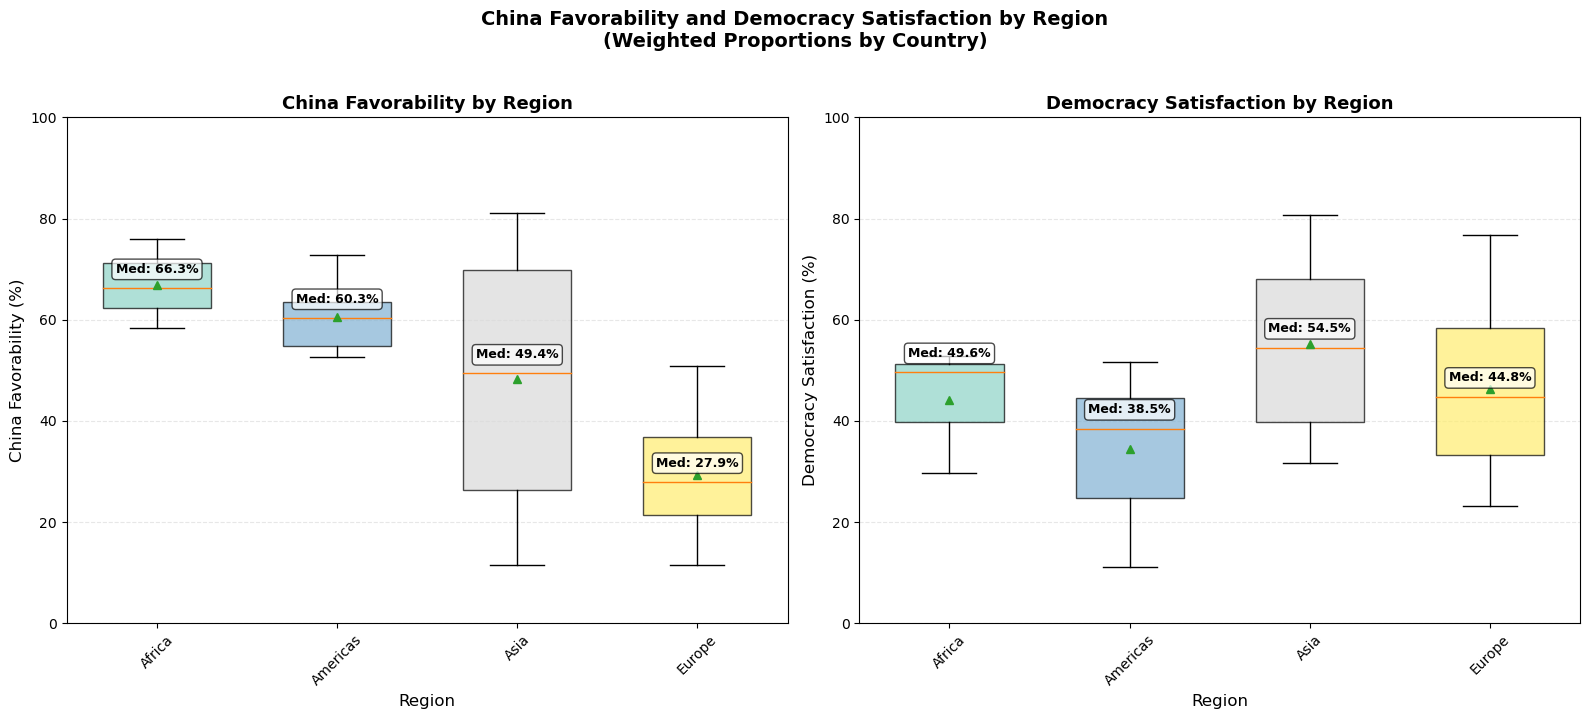

SUMMARY STATISTICS BY REGION

Africa (n=3 countries):
  Countries: Ghana, Kenya, South Africa

  China Favorability:
    Median: 66.3%
    Mean: 66.9%
    Range: 58.3% - 76.0%

  Democracy Satisfaction:
    Median: 49.6%
    Mean: 44.1%
    Range: 29.7% - 52.9%

Americas (n=6 countries):
  Countries: Argentina, Brazil, Chile, Colombia, Mexico, Peru

  China Favorability:
    Median: 60.3%
    Mean: 60.6%
    Range: 52.6% - 72.8%

  Democracy Satisfaction:
    Median: 38.5%
    Mean: 34.4%
    Range: 11.2% - 51.6%

Asia (n=8 countries):
  Countries: India, Japan, Malaysia, Philippines, Singapore, South Korea, Sri Lanka, Thailand

  China Favorability:
    Median: 49.4%
    Mean: 48.3%
    Range: 11.6% - 81.1%

  Democracy Satisfaction:
    Median: 54.5%
    Mean: 55.3%
    Range: 31.6% - 80.7%

Europe (n=10 countries):
  Countries: France, Germany, Greece, Hungary, Italy, Netherlands, Poland, Spain, Sweden, UK

  China Favorability:
    Median: 27.9%
    Mean: 29.2%
    Range: 11.5% - 5

In [58]:
# Box Plot Analysis: China Favorability and Democracy Satisfaction by Region
# Group countries by geographic region

# First, let's define regions based on the countries in your dataset
region_map = {
    # Europe
    'Canada': 'Europe/North America',
    'France': 'Europe',
    'Germany': 'Europe',
    'Greece': 'Europe',
    'Hungary': 'Europe',
    'Italy': 'Europe',
    'Netherlands': 'Europe',
    'Poland': 'Europe',
    'Spain': 'Europe',
    'Sweden': 'Europe',
    'UK': 'Europe',
    
    # Asia
    'Australia': 'Asia-Pacific',
    'Bangladesh': 'Asia',
    'India': 'Asia',
    'Indonesia': 'Asia',
    'Japan': 'Asia',
    'Malaysia': 'Asia',
    'Philippines': 'Asia',
    'Singapore': 'Asia',
    'South Korea': 'Asia',
    'Sri Lanka': 'Asia',
    'Thailand': 'Asia',
    
    # Africa
    'Ghana': 'Africa',
    'Kenya': 'Africa',
    'Nigeria': 'Africa',
    'South Africa': 'Africa',
    'Tunisia': 'Africa',
    
    # Americas
    'Argentina': 'Americas',
    'Brazil': 'Americas',
    'Chile': 'Americas',
    'Colombia': 'Americas',
    'Mexico': 'Americas',
    'Peru': 'Americas',
    
    # Middle East
    'Israel': 'Middle East',
    'Turkey': 'Middle East'
}

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['satisfied_democracy'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'satisfied_democracy'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_china: % who are favorable (1 or 2: very/somewhat favorable)
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    # For satisfied_democracy: % who are satisfied (1 or 2: very/somewhat satisfied)
    satisfied_democracy_satisfied = country_data[country_data['satisfied_democracy'].isin(['1', '2'])]['weight'].sum()
    satisfied_democracy_satisfied_pct = (satisfied_democracy_satisfied / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_pct': fav_china_favorable_pct,
        'satisfied_democracy_pct': satisfied_democracy_satisfied_pct,
        'region': region_map.get(country, 'Other')
    }

# Convert to DataFrame
plot_df = pd.DataFrame(country_stats).T

# Get regions that have at least 3 countries (for meaningful box plots)
region_counts = plot_df['region'].value_counts()
valid_regions = region_counts[region_counts >= 3].index.tolist()
plot_df_filtered = plot_df[plot_df['region'].isin(valid_regions)]

# Create figure with 2 subplots (side by side)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Sort regions by median for better visualization
regions = sorted(plot_df_filtered['region'].unique())

# Box Plot 1: China Favorability by Region
ax1 = axes[0]
data_fav_china = [plot_df_filtered[plot_df_filtered['region'] == region]['fav_china_pct'].values 
                  for region in regions]

bp1 = ax1.boxplot(data_fav_china, labels=regions, patch_artist=True, 
                  showmeans=True, meanline=False, widths=0.6)

# Color the boxes
colors = plt.cm.Set3(np.linspace(0, 1, len(bp1['boxes'])))
for patch, color in zip(bp1['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax1.set_ylabel('China Favorability (%)', fontsize=12)
ax1.set_xlabel('Region', fontsize=12)
ax1.set_title('China Favorability by Region', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y', linestyle='--')
ax1.set_ylim(0, 100)
ax1.tick_params(axis='x', rotation=45)

# Add median annotations
for i, region in enumerate(regions):
    region_data = plot_df_filtered[plot_df_filtered['region'] == region]['fav_china_pct']
    if len(region_data) > 0:
        median_val = region_data.median()
        ax1.text(i+1, median_val + 3, f'Med: {median_val:.1f}%', 
                ha='center', fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

# Box Plot 2: Democracy Satisfaction by Region
ax2 = axes[1]
data_satisfied = [plot_df_filtered[plot_df_filtered['region'] == region]['satisfied_democracy_pct'].values 
                  for region in regions]

bp2 = ax2.boxplot(data_satisfied, labels=regions, patch_artist=True, 
                  showmeans=True, meanline=False, widths=0.6)

# Color the boxes (same colors)
for patch, color in zip(bp2['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax2.set_ylabel('Democracy Satisfaction (%)', fontsize=12)
ax2.set_xlabel('Region', fontsize=12)
ax2.set_title('Democracy Satisfaction by Region', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y', linestyle='--')
ax2.set_ylim(0, 100)
ax2.tick_params(axis='x', rotation=45)

# Add median annotations
for i, region in enumerate(regions):
    region_data = plot_df_filtered[plot_df_filtered['region'] == region]['satisfied_democracy_pct']
    if len(region_data) > 0:
        median_val = region_data.median()
        ax2.text(i+1, median_val + 3, f'Med: {median_val:.1f}%', 
                ha='center', fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

plt.suptitle('China Favorability and Democracy Satisfaction by Region\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("SUMMARY STATISTICS BY REGION")
print("="*70)

for region in regions:
    region_data = plot_df_filtered[plot_df_filtered['region'] == region]
    print(f"\n{region} (n={len(region_data)} countries):")
    print(f"  Countries: {', '.join(region_data.index.tolist())}")
    print(f"\n  China Favorability:")
    print(f"    Median: {region_data['fav_china_pct'].median():.1f}%")
    print(f"    Mean: {region_data['fav_china_pct'].mean():.1f}%")
    print(f"    Range: {region_data['fav_china_pct'].min():.1f}% - {region_data['fav_china_pct'].max():.1f}%")
    print(f"\n  Democracy Satisfaction:")
    print(f"    Median: {region_data['satisfied_democracy_pct'].median():.1f}%")
    print(f"    Mean: {region_data['satisfied_democracy_pct'].mean():.1f}%")
    print(f"    Range: {region_data['satisfied_democracy_pct'].min():.1f}% - {region_data['satisfied_democracy_pct'].max():.1f}%")

### With ammendments to regional groupings

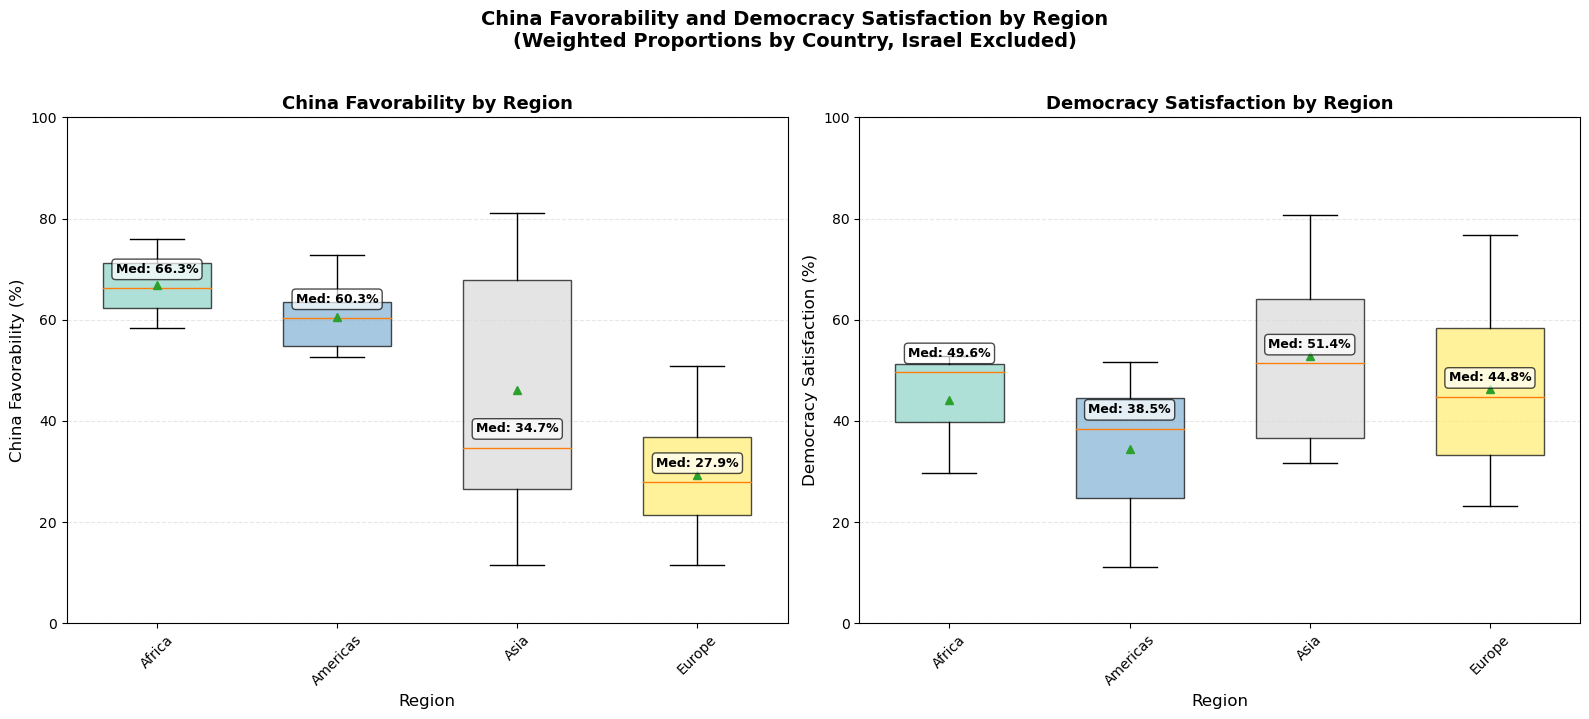

SUMMARY STATISTICS BY REGION (Israel Excluded, Turkey in Asia)

Africa (n=3 countries):
  Countries: Ghana, Kenya, South Africa

  China Favorability:
    Median: 66.3%
    Mean: 66.9%
    Range: 58.3% - 76.0%

  Democracy Satisfaction:
    Median: 49.6%
    Mean: 44.1%
    Range: 29.7% - 52.9%

Americas (n=6 countries):
  Countries: Argentina, Brazil, Chile, Colombia, Mexico, Peru

  China Favorability:
    Median: 60.3%
    Mean: 60.6%
    Range: 52.6% - 72.8%

  Democracy Satisfaction:
    Median: 38.5%
    Mean: 34.4%
    Range: 11.2% - 51.6%

Asia (n=9 countries):
  Countries: India, Japan, Malaysia, Philippines, Singapore, South Korea, Sri Lanka, Thailand, Turkey

  China Favorability:
    Median: 34.7%
    Mean: 46.1%
    Range: 11.6% - 81.1%

  Democracy Satisfaction:
    Median: 51.4%
    Mean: 52.9%
    Range: 31.6% - 80.7%

Europe (n=10 countries):
  Countries: France, Germany, Greece, Hungary, Italy, Netherlands, Poland, Spain, Sweden, UK

  China Favorability:
    Median: 

In [60]:
# Box Plot Analysis: China Favorability and Democracy Satisfaction by Region
# Updated: Turkey moved to Asia, Israel excluded

# Updated region map
region_map = {
    # Europe
    'Canada': 'Europe/North America',
    'France': 'Europe',
    'Germany': 'Europe',
    'Greece': 'Europe',
    'Hungary': 'Europe',
    'Italy': 'Europe',
    'Netherlands': 'Europe',
    'Poland': 'Europe',
    'Spain': 'Europe',
    'Sweden': 'Europe',
    'UK': 'Europe',
    
    # Asia (including Turkey)
    'Australia': 'Asia-Pacific',
    'Bangladesh': 'Asia',
    'India': 'Asia',
    'Indonesia': 'Asia',
    'Japan': 'Asia',
    'Malaysia': 'Asia',
    'Philippines': 'Asia',
    'Singapore': 'Asia',
    'South Korea': 'Asia',
    'Sri Lanka': 'Asia',
    'Thailand': 'Asia',
    'Turkey': 'Asia',  # Moved from Middle East
    
    # Africa
    'Ghana': 'Africa',
    'Kenya': 'Africa',
    'Nigeria': 'Africa',
    'South Africa': 'Africa',
    'Tunisia': 'Africa',
    
    # Americas
    'Argentina': 'Americas',
    'Brazil': 'Americas',
    'Chile': 'Americas',
    'Colombia': 'Americas',
    'Mexico': 'Americas',
    'Peru': 'Americas',
    
    # Israel excluded from analysis
}

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['satisfied_democracy'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'satisfied_democracy'])

# Exclude Israel
valid_data = valid_data[valid_data['country_name'] != 'Israel']

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    # Skip Israel if it somehow appears
    if country == 'Israel':
        continue
        
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_china: % who are favorable (1 or 2: very/somewhat favorable)
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    # For satisfied_democracy: % who are satisfied (1 or 2: very/somewhat satisfied)
    satisfied_democracy_satisfied = country_data[country_data['satisfied_democracy'].isin(['1', '2'])]['weight'].sum()
    satisfied_democracy_satisfied_pct = (satisfied_democracy_satisfied / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_pct': fav_china_favorable_pct,
        'satisfied_democracy_pct': satisfied_democracy_satisfied_pct,
        'region': region_map.get(country, 'Other')
    }

# Convert to DataFrame
plot_df = pd.DataFrame(country_stats).T

# Get regions that have at least 3 countries (for meaningful box plots)
region_counts = plot_df['region'].value_counts()
valid_regions = region_counts[region_counts >= 3].index.tolist()
plot_df_filtered = plot_df[plot_df['region'].isin(valid_regions)]

# Create figure with 2 subplots (side by side)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Sort regions by median for better visualization
regions = sorted(plot_df_filtered['region'].unique())

# Box Plot 1: China Favorability by Region
ax1 = axes[0]
data_fav_china = [plot_df_filtered[plot_df_filtered['region'] == region]['fav_china_pct'].values 
                  for region in regions]

bp1 = ax1.boxplot(data_fav_china, labels=regions, patch_artist=True, 
                  showmeans=True, meanline=False, widths=0.6)

# Color the boxes
colors = plt.cm.Set3(np.linspace(0, 1, len(bp1['boxes'])))
for patch, color in zip(bp1['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax1.set_ylabel('China Favorability (%)', fontsize=12)
ax1.set_xlabel('Region', fontsize=12)
ax1.set_title('China Favorability by Region', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y', linestyle='--')
ax1.set_ylim(0, 100)
ax1.tick_params(axis='x', rotation=45)

# Add median annotations
for i, region in enumerate(regions):
    region_data = plot_df_filtered[plot_df_filtered['region'] == region]['fav_china_pct']
    if len(region_data) > 0:
        median_val = region_data.median()
        ax1.text(i+1, median_val + 3, f'Med: {median_val:.1f}%', 
                ha='center', fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

# Box Plot 2: Democracy Satisfaction by Region
ax2 = axes[1]
data_satisfied = [plot_df_filtered[plot_df_filtered['region'] == region]['satisfied_democracy_pct'].values 
                  for region in regions]

bp2 = ax2.boxplot(data_satisfied, labels=regions, patch_artist=True, 
                  showmeans=True, meanline=False, widths=0.6)

# Color the boxes (same colors)
for patch, color in zip(bp2['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax2.set_ylabel('Democracy Satisfaction (%)', fontsize=12)
ax2.set_xlabel('Region', fontsize=12)
ax2.set_title('Democracy Satisfaction by Region', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y', linestyle='--')
ax2.set_ylim(0, 100)
ax2.tick_params(axis='x', rotation=45)

# Add median annotations
for i, region in enumerate(regions):
    region_data = plot_df_filtered[plot_df_filtered['region'] == region]['satisfied_democracy_pct']
    if len(region_data) > 0:
        median_val = region_data.median()
        ax2.text(i+1, median_val + 3, f'Med: {median_val:.1f}%', 
                ha='center', fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

plt.suptitle('China Favorability and Democracy Satisfaction by Region\n(Weighted Proportions by Country, Israel Excluded)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("SUMMARY STATISTICS BY REGION (Israel Excluded, Turkey in Asia)")
print("="*70)

for region in regions:
    region_data = plot_df_filtered[plot_df_filtered['region'] == region]
    print(f"\n{region} (n={len(region_data)} countries):")
    print(f"  Countries: {', '.join(region_data.index.tolist())}")
    print(f"\n  China Favorability:")
    print(f"    Median: {region_data['fav_china_pct'].median():.1f}%")
    print(f"    Mean: {region_data['fav_china_pct'].mean():.1f}%")
    print(f"    Range: {region_data['fav_china_pct'].min():.1f}% - {region_data['fav_china_pct'].max():.1f}%")
    print(f"\n  Democracy Satisfaction:")
    print(f"    Median: {region_data['satisfied_democracy_pct'].median():.1f}%")
    print(f"    Mean: {region_data['satisfied_democracy_pct'].mean():.1f}%")
    print(f"    Range: {region_data['satisfied_democracy_pct'].min():.1f}% - {region_data['satisfied_democracy_pct'].max():.1f}%")

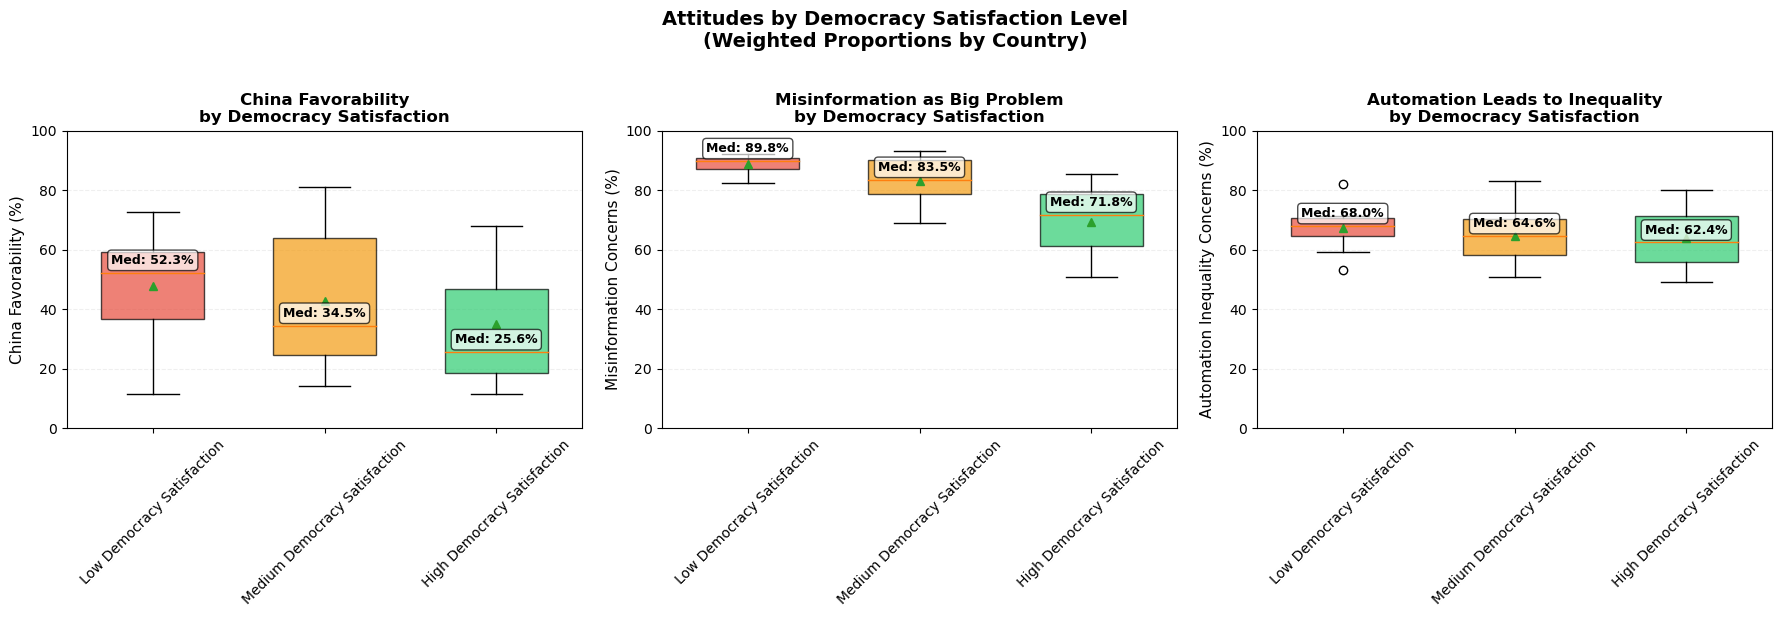

SUMMARY STATISTICS BY DEMOCRACY SATISFACTION LEVEL

Low Democracy Satisfaction (n=8 countries):
  Countries: Chile, Colombia, Greece, Italy, Japan, Peru, South Africa, Spain

  China Favorability:
    Median: 52.3%
    Mean: 47.9%
    Range: 11.6% - 72.8%

  Misinformation Concerns:
    Median: 89.8%
    Mean: 88.7%
    Range: 82.6% - 92.2%

  Automation Inequality Concerns:
    Median: 68.0%
    Mean: 67.3%
    Range: 53.3% - 82.0%

Medium Democracy Satisfaction (n=20 countries):
  Countries: Argentina, Australia, Brazil, Canada, France, Germany, Ghana, Hungary, Israel, Kenya, Malaysia, Mexico, Netherlands, Philippines, Poland, South Korea, Sri Lanka, Thailand, Turkey, UK

  China Favorability:
    Median: 34.5%
    Mean: 42.7%
    Range: 14.1% - 81.1%

  Misinformation Concerns:
    Median: 83.5%
    Mean: 83.3%
    Range: 69.1% - 93.0%

  Automation Inequality Concerns:
    Median: 64.6%
    Mean: 64.6%
    Range: 51.0% - 83.0%

High Democracy Satisfaction (n=3 countries):
  Countri

In [61]:
# Box Plot Analysis: Group by Democracy Satisfaction
# Show China Favorability, Misinformation Concerns, and Automation Inequality within each group

# Function to calculate weighted proportions for a variable
def calc_weighted_proportion(df, var_name, favorable_codes=['1', '2']):
    """Calculate weighted proportion of favorable responses"""
    country_stats = {}
    for country in sorted(df['country_name'].unique()):
        country_data = df[df['country_name'] == country]
        total_weight = country_data['weight'].sum()
        favorable = country_data[country_data[var_name].isin(favorable_codes)]['weight'].sum()
        favorable_pct = (favorable / total_weight) * 100
        country_stats[country] = favorable_pct
    return pd.Series(country_stats)

# 1. China Favorability
valid_china = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['satisfied_democracy'].isin(['1', '2', '3', '4'])
].copy()
valid_china['weight'] = pd.to_numeric(valid_china['weight'], errors='coerce')
valid_china = valid_china.dropna(subset=['weight', 'country_name', 'fav_china', 'satisfied_democracy'])

china_fav = calc_weighted_proportion(valid_china, 'fav_china', ['1', '2'])
democracy_sat = calc_weighted_proportion(valid_china, 'satisfied_democracy', ['1', '2'])

# 2. Misinformation Concerns
valid_misinfo = pew[
    pew['prob_misinformation'].isin(['1', '2', '3', '4']) & 
    pew['satisfied_democracy'].isin(['1', '2', '3', '4'])
].copy()
valid_misinfo['weight'] = pd.to_numeric(valid_misinfo['weight'], errors='coerce')
valid_misinfo = valid_misinfo.dropna(subset=['weight', 'country_name', 'prob_misinformation', 'satisfied_democracy'])

misinfo_concern = calc_weighted_proportion(valid_misinfo, 'prob_misinformation', ['1', '2'])  # Big problem

# 3. Automation Inequality
valid_automation = pew[
    pew['inequality_automation'].isin(['1', '2', '3', '4']) & 
    pew['satisfied_democracy'].isin(['1', '2', '3', '4'])
].copy()
valid_automation['weight'] = pd.to_numeric(valid_automation['weight'], errors='coerce')
valid_automation = valid_automation.dropna(subset=['weight', 'country_name', 'inequality_automation', 'satisfied_democracy'])

automation_ineq = calc_weighted_proportion(valid_automation, 'inequality_automation', ['1', '2'])  # Great deal/fair amount

# Combine into one dataframe
# Get common countries across all three
common_countries = set(china_fav.index) & set(misinfo_concern.index) & set(automation_ineq.index) & set(democracy_sat.index)

plot_df = pd.DataFrame({
    'china_favorability': [china_fav[country] for country in sorted(common_countries)],
    'misinformation_concern': [misinfo_concern[country] for country in sorted(common_countries)],
    'automation_inequality': [automation_ineq[country] for country in sorted(common_countries)],
    'democracy_satisfaction': [democracy_sat[country] for country in sorted(common_countries)]
}, index=sorted(common_countries))

# Group by democracy satisfaction levels (using tertiles)
def categorize_democracy_satisfaction(pct):
    if pct < 33.33:
        return 'Low Democracy Satisfaction'
    elif pct < 66.67:
        return 'Medium Democracy Satisfaction'
    else:
        return 'High Democracy Satisfaction'

plot_df['democracy_group'] = plot_df['democracy_satisfaction'].apply(categorize_democracy_satisfaction)

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

groups = ['Low Democracy Satisfaction', 'Medium Democracy Satisfaction', 'High Democracy Satisfaction']
colors = ['#e74c3c', '#f39c12', '#2ecc71']  # Red, Orange, Green

# Box Plot 1: China Favorability
ax1 = axes[0]
data_china = [plot_df[plot_df['democracy_group'] == group]['china_favorability'].values 
              for group in groups]

bp1 = ax1.boxplot(data_china, labels=groups, patch_artist=True, 
                  showmeans=True, meanline=False, widths=0.6)

for patch, color in zip(bp1['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax1.set_ylabel('China Favorability (%)', fontsize=11)
ax1.set_title('China Favorability\nby Democracy Satisfaction', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.2, axis='y', linestyle='--')
ax1.set_ylim(0, 100)
ax1.tick_params(axis='x', rotation=45)

# Add median annotations
for i, group in enumerate(groups):
    group_data = plot_df[plot_df['democracy_group'] == group]['china_favorability']
    if len(group_data) > 0:
        median_val = group_data.median()
        ax1.text(i+1, median_val + 3, f'Med: {median_val:.1f}%', 
                ha='center', fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

# Box Plot 2: Misinformation Concerns
ax2 = axes[1]
data_misinfo = [plot_df[plot_df['democracy_group'] == group]['misinformation_concern'].values 
                for group in groups]

bp2 = ax2.boxplot(data_misinfo, labels=groups, patch_artist=True, 
                   showmeans=True, meanline=False, widths=0.6)

for patch, color in zip(bp2['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax2.set_ylabel('Misinformation Concerns (%)', fontsize=11)
ax2.set_title('Misinformation as Big Problem\nby Democracy Satisfaction', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.2, axis='y', linestyle='--')
ax2.set_ylim(0, 100)
ax2.tick_params(axis='x', rotation=45)

# Add median annotations
for i, group in enumerate(groups):
    group_data = plot_df[plot_df['democracy_group'] == group]['misinformation_concern']
    if len(group_data) > 0:
        median_val = group_data.median()
        ax2.text(i+1, median_val + 3, f'Med: {median_val:.1f}%', 
                ha='center', fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

# Box Plot 3: Automation Inequality
ax3 = axes[2]
data_automation = [plot_df[plot_df['democracy_group'] == group]['automation_inequality'].values 
                   for group in groups]

bp3 = ax3.boxplot(data_automation, labels=groups, patch_artist=True, 
                  showmeans=True, meanline=False, widths=0.6)

for patch, color in zip(bp3['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax3.set_ylabel('Automation Inequality Concerns (%)', fontsize=11)
ax3.set_title('Automation Leads to Inequality\nby Democracy Satisfaction', fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.2, axis='y', linestyle='--')
ax3.set_ylim(0, 100)
ax3.tick_params(axis='x', rotation=45)

# Add median annotations
for i, group in enumerate(groups):
    group_data = plot_df[plot_df['democracy_group'] == group]['automation_inequality']
    if len(group_data) > 0:
        median_val = group_data.median()
        ax3.text(i+1, median_val + 3, f'Med: {median_val:.1f}%', 
                ha='center', fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

plt.suptitle('Attitudes by Democracy Satisfaction Level\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print summary statistics
print("="*70)
print("SUMMARY STATISTICS BY DEMOCRACY SATISFACTION LEVEL")
print("="*70)

for group in groups:
    group_data = plot_df[plot_df['democracy_group'] == group]
    print(f"\n{group} (n={len(group_data)} countries):")
    print(f"  Countries: {', '.join(group_data.index.tolist())}")
    
    print(f"\n  China Favorability:")
    print(f"    Median: {group_data['china_favorability'].median():.1f}%")
    print(f"    Mean: {group_data['china_favorability'].mean():.1f}%")
    print(f"    Range: {group_data['china_favorability'].min():.1f}% - {group_data['china_favorability'].max():.1f}%")
    
    print(f"\n  Misinformation Concerns:")
    print(f"    Median: {group_data['misinformation_concern'].median():.1f}%")
    print(f"    Mean: {group_data['misinformation_concern'].mean():.1f}%")
    print(f"    Range: {group_data['misinformation_concern'].min():.1f}% - {group_data['misinformation_concern'].max():.1f}%")
    
    print(f"\n  Automation Inequality Concerns:")
    print(f"    Median: {group_data['automation_inequality'].median():.1f}%")
    print(f"    Mean: {group_data['automation_inequality'].mean():.1f}%")
    print(f"    Range: {group_data['automation_inequality'].min():.1f}% - {group_data['automation_inequality'].max():.1f}%")

# Statistical tests
from scipy.stats import kruskal

print(f"\n" + "="*70)
print("STATISTICAL TESTS (Kruskal-Wallis)")
print("="*70)

# Test 1: China Favorability
group_low_china = plot_df[plot_df['democracy_group'] == 'Low Democracy Satisfaction']['china_favorability']
group_med_china = plot_df[plot_df['democracy_group'] == 'Medium Democracy Satisfaction']['china_favorability']
group_high_china = plot_df[plot_df['democracy_group'] == 'High Democracy Satisfaction']['china_favorability']

stat1, p1 = kruskal(group_low_china, group_med_china, group_high_china)
print(f"\nChina Favorability:")
print(f"  H-statistic: {stat1:.3f}, p-value: {p1:.4f}")
print(f"  {'✓ Statistically significant!' if p1 < 0.05 else '✗ Not significant'}")

# Test 2: Misinformation
group_low_mis = plot_df[plot_df['democracy_group'] == 'Low Democracy Satisfaction']['misinformation_concern']
group_med_mis = plot_df[plot_df['democracy_group'] == 'Medium Democracy Satisfaction']['misinformation_concern']
group_high_mis = plot_df[plot_df['democracy_group'] == 'High Democracy Satisfaction']['misinformation_concern']

stat2, p2 = kruskal(group_low_mis, group_med_mis, group_high_mis)
print(f"\nMisinformation Concerns:")
print(f"  H-statistic: {stat2:.3f}, p-value: {p2:.4f}")
print(f"  {'✓ Statistically significant!' if p2 < 0.05 else '✗ Not significant'}")

# Test 3: Automation
group_low_auto = plot_df[plot_df['democracy_group'] == 'Low Democracy Satisfaction']['automation_inequality']
group_med_auto = plot_df[plot_df['democracy_group'] == 'Medium Democracy Satisfaction']['automation_inequality']
group_high_auto = plot_df[plot_df['democracy_group'] == 'High Democracy Satisfaction']['automation_inequality']

stat3, p3 = kruskal(group_low_auto, group_med_auto, group_high_auto)
print(f"\nAutomation Inequality Concerns:")
print(f"  H-statistic: {stat3:.3f}, p-value: {p3:.4f}")
print(f"  {'✓ Statistically significant!' if p3 < 0.05 else '✗ Not significant'}")

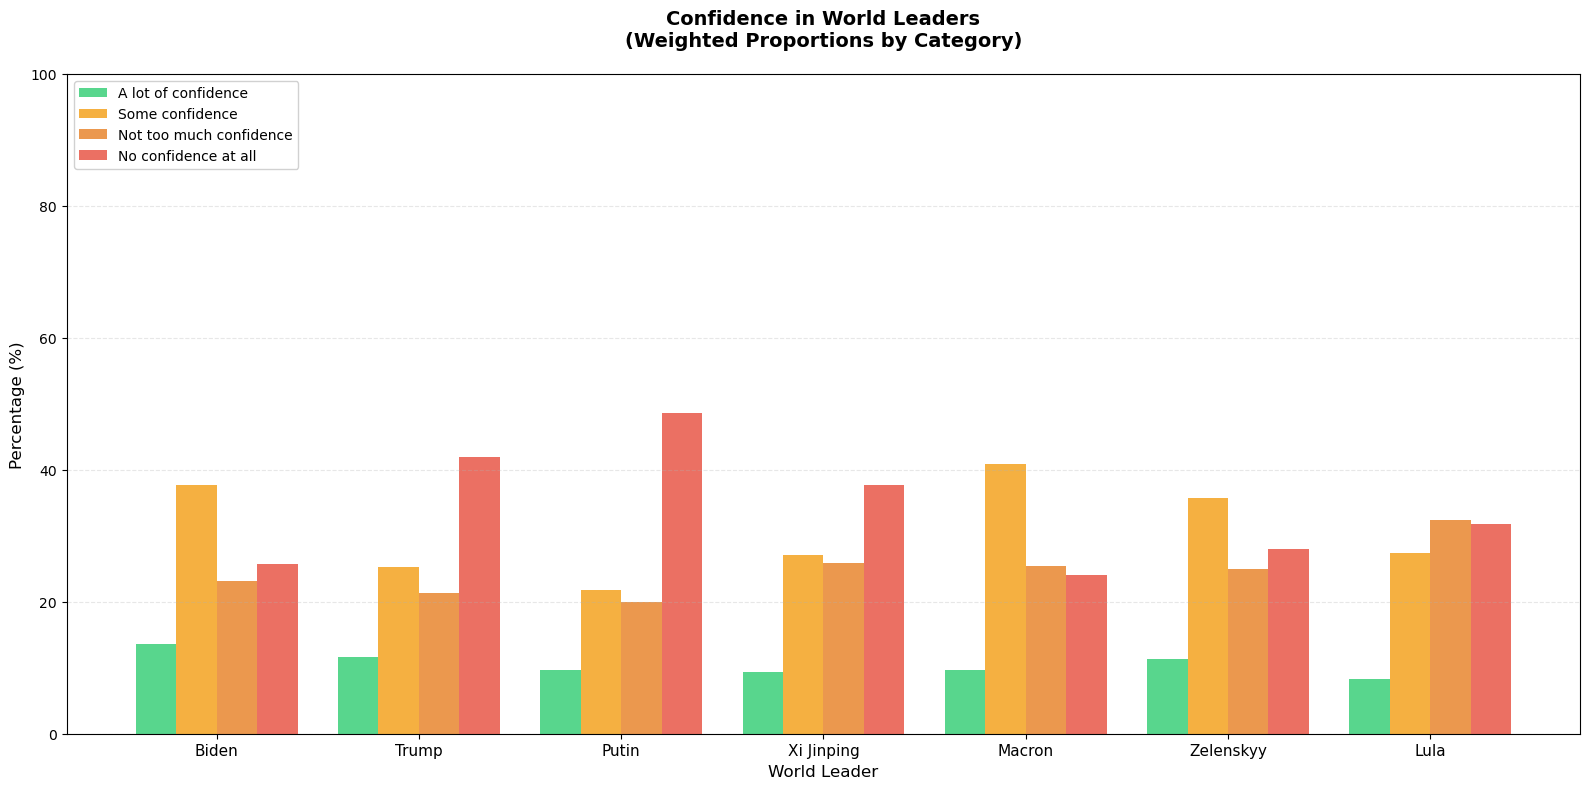

CONFIDENCE IN WORLD LEADERS - SUMMARY STATISTICS

Biden:
  A lot of confidence: 13.5%
  Some confidence: 37.7%
  Not too much confidence: 23.1%
  No confidence at all: 25.7%
  Total Confident (1+2): 51.2%
  Total Not Confident (3+4): 48.8%

Trump:
  A lot of confidence: 11.6%
  Some confidence: 25.3%
  Not too much confidence: 21.3%
  No confidence at all: 41.9%
  Total Confident (1+2): 36.8%
  Total Not Confident (3+4): 63.2%

Putin:
  A lot of confidence: 9.6%
  Some confidence: 21.8%
  Not too much confidence: 20.0%
  No confidence at all: 48.6%
  Total Confident (1+2): 31.4%
  Total Not Confident (3+4): 68.6%

Xi Jinping:
  A lot of confidence: 9.4%
  Some confidence: 27.0%
  Not too much confidence: 25.9%
  No confidence at all: 37.7%
  Total Confident (1+2): 36.4%
  Total Not Confident (3+4): 63.6%

Macron:
  A lot of confidence: 9.7%
  Some confidence: 40.8%
  Not too much confidence: 25.4%
  No confidence at all: 24.1%
  Total Confident (1+2): 50.5%
  Total Not Confident (3+4):

In [62]:
# Confidence in World Leaders Comparison
# Showing all ordinal categories (1-4) for each leader
# Using weighted proportions (appropriate for ordinal variables)

# List of confidence variables to compare
confidence_vars = {
    'confid_biden': 'Biden',
    'confid_trump': 'Trump',
    'confid_putin': 'Putin',
    'confid_xi': 'Xi Jinping',
    'confid_macron': 'Macron',
    'confid_zelenskyy': 'Zelenskyy',
    'confid_lula': 'Lula'
}

# Category labels
category_labels = {
    '1': 'A lot of confidence',
    '2': 'Some confidence',
    '3': 'Not too much confidence',
    '4': 'No confidence at all'
}

# Calculate weighted proportions for each leader
leader_stats = {}

for var_name, leader_name in confidence_vars.items():
    # Filter to valid responses (1-4)
    valid_data = pew[pew[var_name].isin(['1', '2', '3', '4'])].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', var_name])
    
    total_weight = valid_data['weight'].sum()
    
    # Calculate weighted proportions for each category
    proportions = {}
    for category in ['1', '2', '3', '4']:
        category_weight = valid_data[valid_data[var_name] == category]['weight'].sum()
        proportions[category] = (category_weight / total_weight) * 100
    
    leader_stats[leader_name] = proportions

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(leader_stats).T
plot_df.columns = [category_labels[col] for col in plot_df.columns]

# Reorder columns for logical flow
plot_df = plot_df[['A lot of confidence', 'Some confidence', 
                   'Not too much confidence', 'No confidence at all']]

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(16, 8))

# Set up positions for bars
x = np.arange(len(plot_df.index))
width = 0.2  # Width of the bars

# Colors for each category
colors = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']  # Green, Orange, Light Red, Dark Red

# Create bars for each category
for i, (category, color) in enumerate(zip(plot_df.columns, colors)):
    values = plot_df[category].values
    offset = (i - 1.5) * width
    ax.bar(x + offset, values, width, label=category, color=color, alpha=0.8)

# Customize the plot
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_xlabel('World Leader', fontsize=12)
ax.set_title('Confidence in World Leaders\n(Weighted Proportions by Category)', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, fontsize=11)
ax.legend(loc='upper left', framealpha=0.9, fontsize=10)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*80)
print("CONFIDENCE IN WORLD LEADERS - SUMMARY STATISTICS")
print("="*80)

for leader in plot_df.index:
    print(f"\n{leader}:")
    for category in plot_df.columns:
        pct = plot_df.loc[leader, category]
        print(f"  {category}: {pct:.1f}%")
    
    # Calculate "confident" (1+2) vs "not confident" (3+4)
    confident = plot_df.loc[leader, 'A lot of confidence'] + plot_df.loc[leader, 'Some confidence']
    not_confident = plot_df.loc[leader, 'Not too much confidence'] + plot_df.loc[leader, 'No confidence at all']
    print(f"  Total Confident (1+2): {confident:.1f}%")
    print(f"  Total Not Confident (3+4): {not_confident:.1f}%")

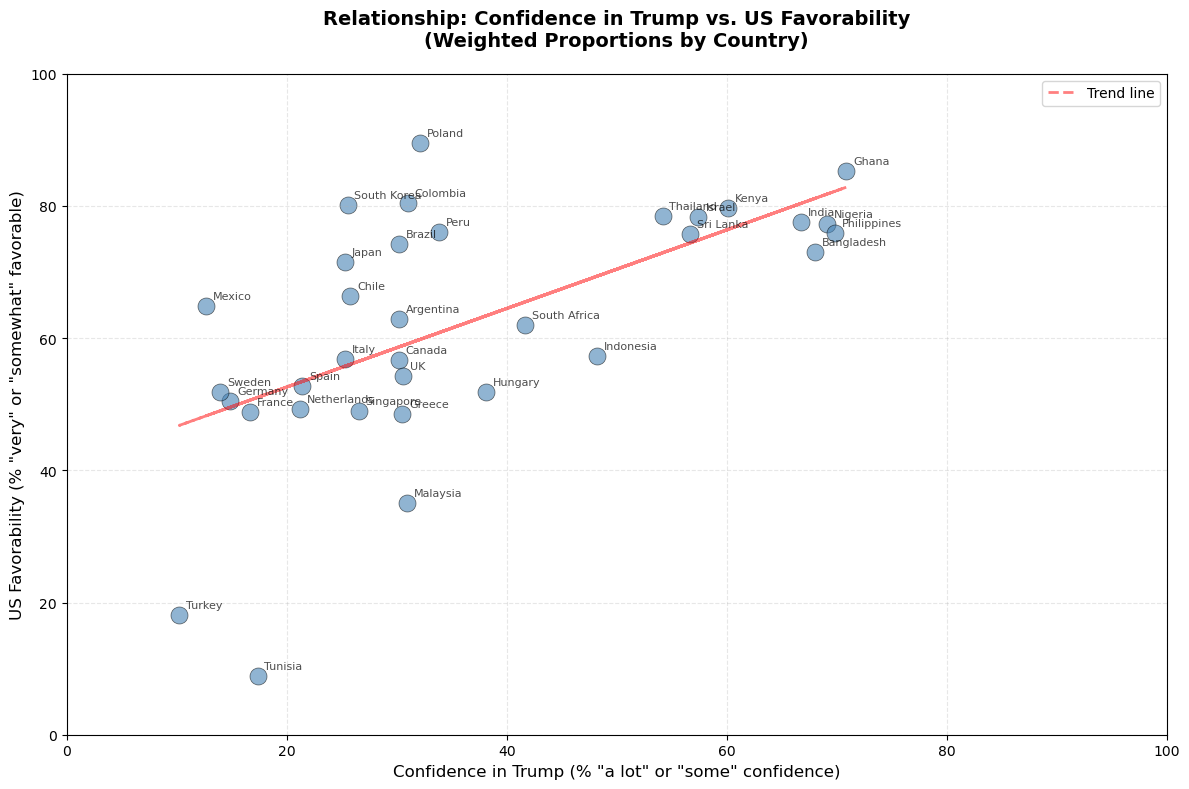

Summary Statistics (Weighted Proportions):

Number of countries: 34

Confidence in Trump (% confident):
  Mean: 36.4%
  Range: 10.2% - 70.9%

US Favorability (% favorable):
  Mean: 62.3%
  Range: 9.0% - 89.5%

Spearman Correlation: 0.631 (p-value: 0.0001)
  Statistically significant correlation!
  Positive correlation: More confidence in Trump → More favorable views of US
  This suggests Trump is seen as representative of the US


In [147]:
# Scatterplot: confid_trump vs fav_us
# Testing: Does confidence in Trump correlate with favorability toward the US?
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['confid_trump'].isin(['1', '2', '3', '4']) & 
    pew['fav_us'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'confid_trump', 'fav_us'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For confid_trump: % who have "a lot of confidence" or "some confidence" (1 or 2)
    trump_confidence = country_data[country_data['confid_trump'].isin(['1', '2'])]['weight'].sum()
    trump_confidence_pct = (trump_confidence / total_weight) * 100
    
    # For fav_us: % who are favorable (1 or 2: very/somewhat favorable)
    fav_us_favorable = country_data[country_data['fav_us'].isin(['1', '2'])]['weight'].sum()
    fav_us_pct = (fav_us_favorable / total_weight) * 100
    
    country_stats[country] = {
        'trump_confidence_pct': trump_confidence_pct,
        'fav_us_pct': fav_us_pct
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df['trump_confidence_pct'], 
           plot_df['fav_us_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'trump_confidence_pct'], 
                 plot_df.loc[country, 'fav_us_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line
from scipy import stats
z = np.polyfit(plot_df['trump_confidence_pct'], 
               plot_df['fav_us_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df['trump_confidence_pct'], 
        p(plot_df['trump_confidence_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('Confidence in Trump (% "a lot" or "some" confidence)', fontsize=12)
ax.set_ylabel('US Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_title('Relationship: Confidence in Trump vs. US Favorability\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nConfidence in Trump (% confident):")
print(f"  Mean: {plot_df['trump_confidence_pct'].mean():.1f}%")
print(f"  Range: {plot_df['trump_confidence_pct'].min():.1f}% - {plot_df['trump_confidence_pct'].max():.1f}%")
print(f"\nUS Favorability (% favorable):")
print(f"  Mean: {plot_df['fav_us_pct'].mean():.1f}%")
print(f"  Range: {plot_df['fav_us_pct'].min():.1f}% - {plot_df['fav_us_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['trump_confidence_pct'], 
                                 plot_df['fav_us_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
    if correlation > 0:
        print("  Positive correlation: More confidence in Trump → More favorable views of US")
        print("  This suggests Trump is seen as representative of the US")
    else:
        print("  Negative correlation: More confidence in Trump → Less favorable views of US")
        print("  This suggests Trump may be viewed separately from the US as a country")
else:
    print("  No statistically significant correlation.")
    print("  This suggests confidence in Trump and favorability toward the US operate independently")

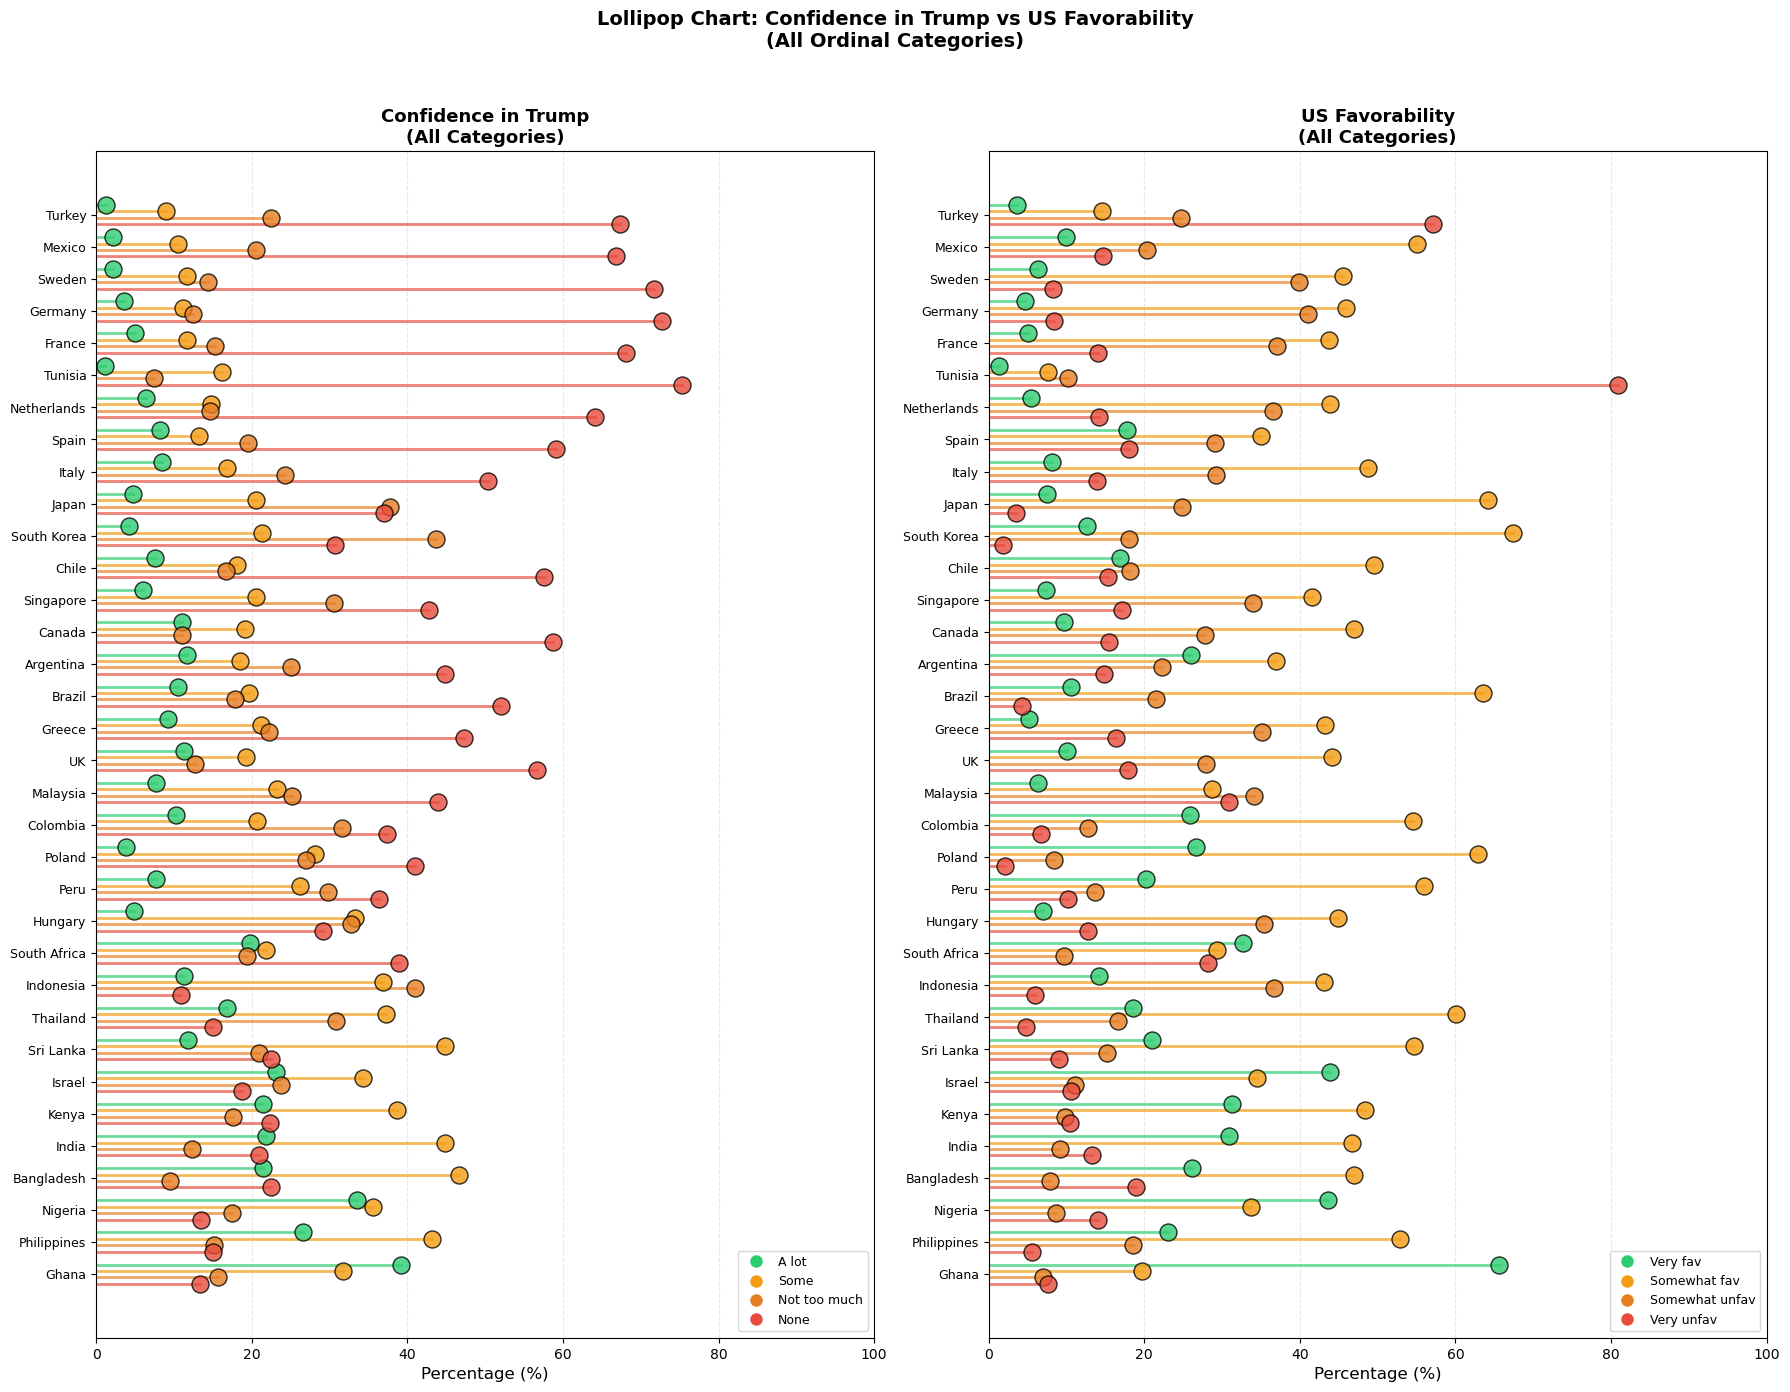

In [149]:
# Grouped Lollipop Chart: All Ordinal Categories
# Showing all 4 categories for confid_trump vs fav_us

# Use the same plot_df from before with all categories
# (from the stacked bar chart code)

# Sort by country name or by a specific metric
plot_df = plot_df.sort_values('total_confident', ascending=True)

# Create grouped lollipop chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, max(10, len(plot_df) * 0.4)))

y_pos = np.arange(len(plot_df))
width = 0.2  # Width between groups

# Chart 1: Trump Confidence - All 4 categories
categories_trump = ['trump_1', 'trump_2', 'trump_3', 'trump_4']
labels_trump = ['A lot', 'Some', 'Not too much', 'None']
colors_trump = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']

for i, (cat, label, color) in enumerate(zip(categories_trump, labels_trump, colors_trump)):
    values = plot_df[cat].values
    offsets = y_pos + (i - 1.5) * width
    for j, (val, offset) in enumerate(zip(values, offsets)):
        ax1.plot([0, val], [offset, offset], color=color, linewidth=2, alpha=0.7)
        ax1.scatter(val, offset, s=150, color=color, alpha=0.8, edgecolors='black', linewidth=1, zorder=3)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(plot_df.index, fontsize=9)
ax1.set_xlabel('Percentage (%)', fontsize=12)
ax1.set_title('Confidence in Trump\n(All Categories)', fontsize=13, fontweight='bold')
ax1.set_xlim(0, 100)
ax1.grid(True, alpha=0.3, axis='x', linestyle='--')
ax1.invert_yaxis()

# Add legend
from matplotlib.lines import Line2D
legend_elements1 = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10, label=label) 
                    for color, label in zip(colors_trump, labels_trump)]
ax1.legend(handles=legend_elements1, loc='lower right', fontsize=9)

# Chart 2: US Favorability - All 4 categories
categories_us = ['fav_us_1', 'fav_us_2', 'fav_us_3', 'fav_us_4']
labels_us = ['Very fav', 'Somewhat fav', 'Somewhat unfav', 'Very unfav']
colors_us = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']

for i, (cat, label, color) in enumerate(zip(categories_us, labels_us, colors_us)):
    values = plot_df[cat].values
    offsets = y_pos + (i - 1.5) * width
    for j, (val, offset) in enumerate(zip(values, offsets)):
        ax2.plot([0, val], [offset, offset], color=color, linewidth=2, alpha=0.7)
        ax2.scatter(val, offset, s=150, color=color, alpha=0.8, edgecolors='black', linewidth=1, zorder=3)

ax2.set_yticks(y_pos)
ax2.set_yticklabels(plot_df.index, fontsize=9)
ax2.set_xlabel('Percentage (%)', fontsize=12)
ax2.set_title('US Favorability\n(All Categories)', fontsize=13, fontweight='bold')
ax2.set_xlim(0, 100)
ax2.grid(True, alpha=0.3, axis='x', linestyle='--')
ax2.invert_yaxis()

legend_elements2 = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10, label=label) 
                    for color, label in zip(colors_us, labels_us)]
ax2.legend(handles=legend_elements2, loc='lower right', fontsize=9)

plt.suptitle('Lollipop Chart: Confidence in Trump vs US Favorability\n(All Ordinal Categories)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

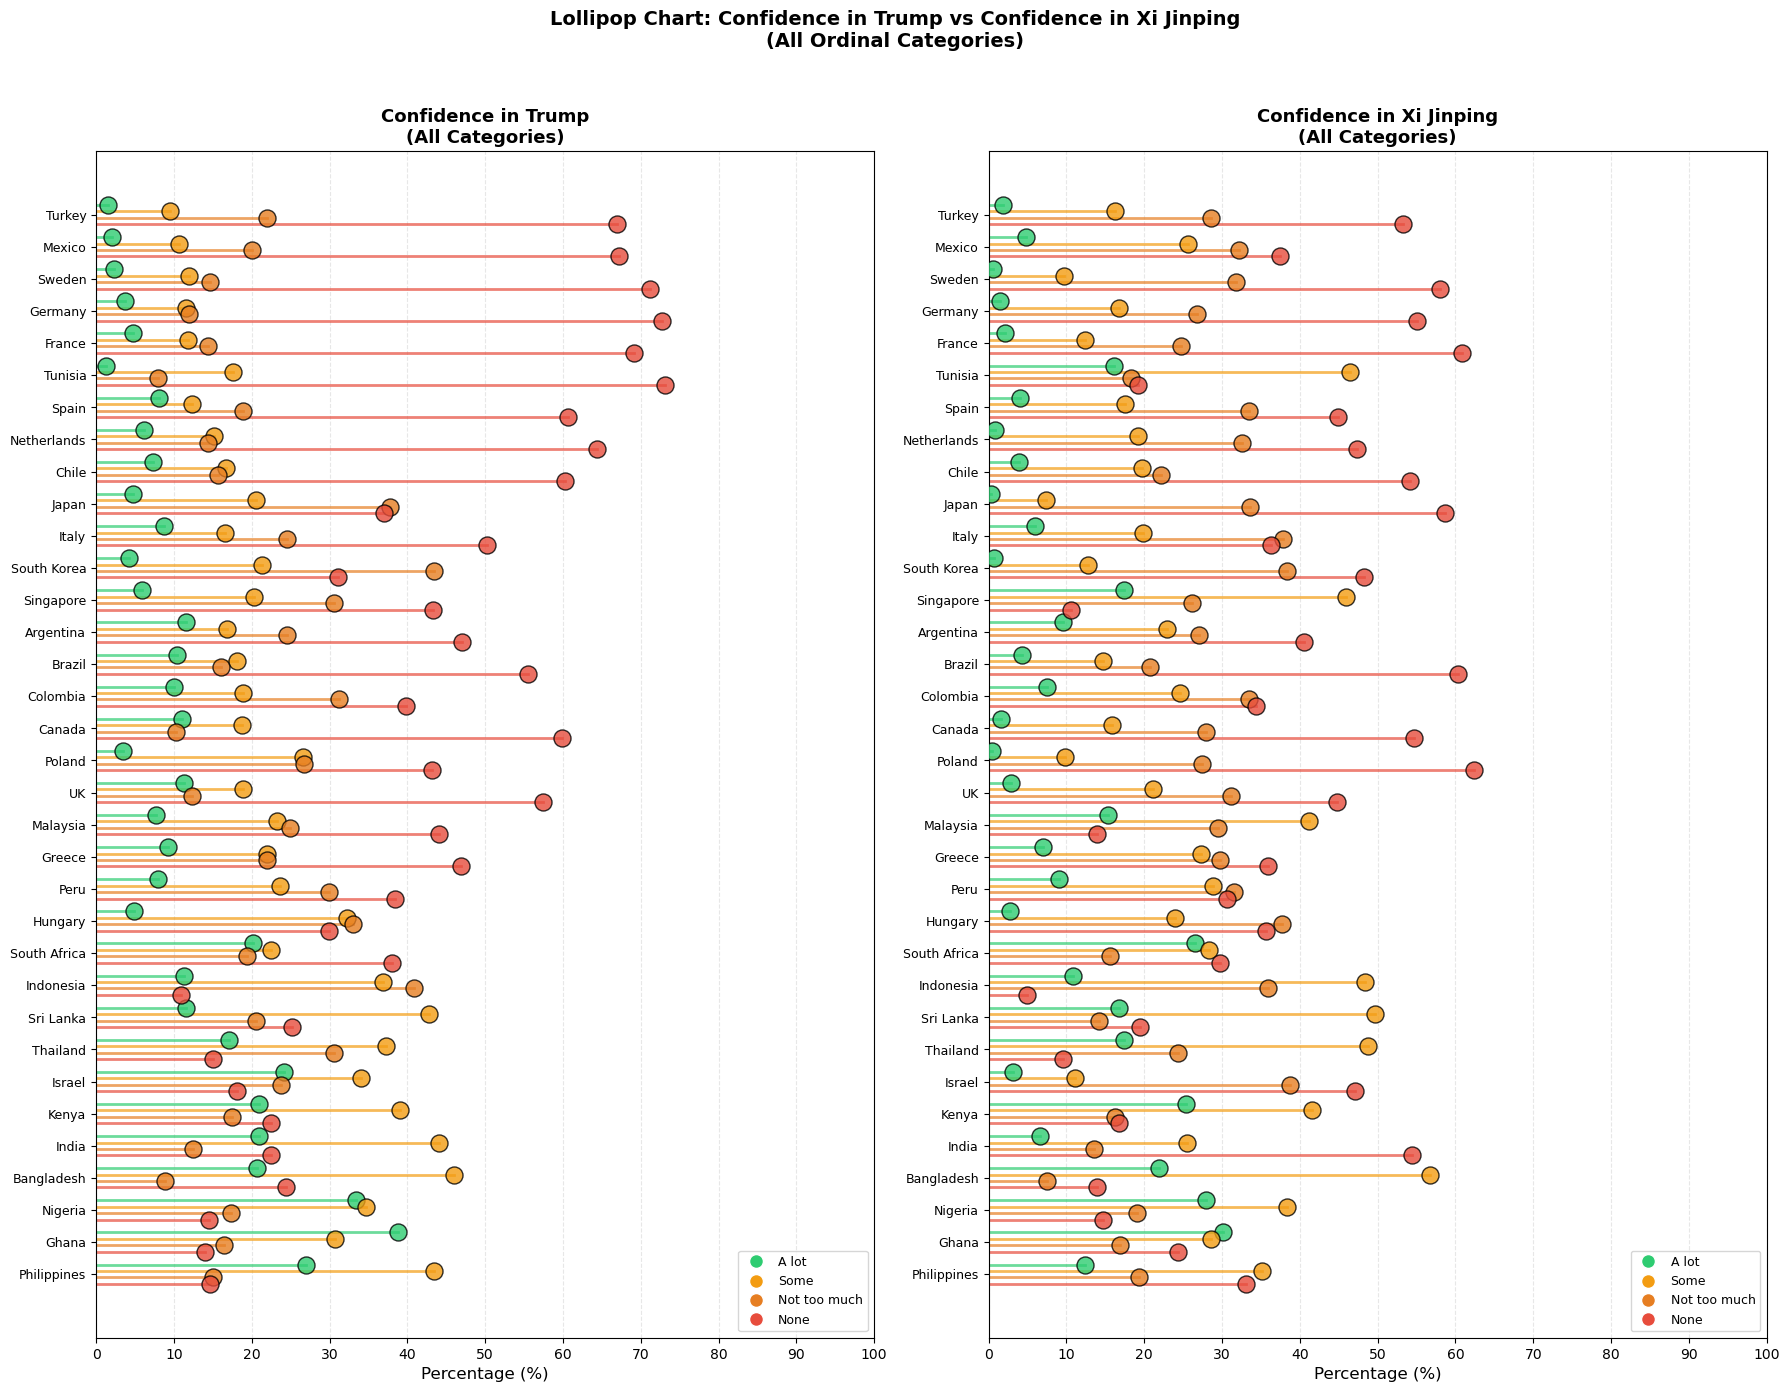

In [150]:
# Grouped Lollipop Chart: Confidence in Trump vs Confidence in Xi
# Showing all 4 ordinal categories side by side

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['confid_trump'].isin(['1', '2', '3', '4']) & 
    pew['confid_xi'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'confid_trump', 'confid_xi'])

# Calculate weighted proportions for ALL categories
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Trump confidence - all 4 categories
    trump_cats = {}
    for cat in ['1', '2', '3', '4']:
        cat_weight = country_data[country_data['confid_trump'] == cat]['weight'].sum()
        trump_cats[cat] = (cat_weight / total_weight) * 100
    
    # Xi confidence - all 4 categories
    xi_cats = {}
    for cat in ['1', '2', '3', '4']:
        cat_weight = country_data[country_data['confid_xi'] == cat]['weight'].sum()
        xi_cats[cat] = (cat_weight / total_weight) * 100
    
    country_stats[country] = {
        'trump_1': trump_cats['1'],  # A lot of confidence
        'trump_2': trump_cats['2'],  # Some confidence
        'trump_3': trump_cats['3'],  # Not too much confidence
        'trump_4': trump_cats['4'],  # No confidence at all
        'xi_1': xi_cats['1'],  # A lot of confidence
        'xi_2': xi_cats['2'],  # Some confidence
        'xi_3': xi_cats['3'],  # Not too much confidence
        'xi_4': xi_cats['4'],  # No confidence at all
    }

plot_df = pd.DataFrame(country_stats).T

# Sort by total confidence in Trump (1+2)
plot_df['trump_total_confident'] = plot_df['trump_1'] + plot_df['trump_2']
plot_df = plot_df.sort_values('trump_total_confident', ascending=True)

# Create grouped lollipop chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, max(10, len(plot_df) * 0.4)))

y_pos = np.arange(len(plot_df))
width = 0.2  # Width between groups

# Chart 1: Trump Confidence - All 4 categories
categories_trump = ['trump_1', 'trump_2', 'trump_3', 'trump_4']
labels_trump = ['A lot', 'Some', 'Not too much', 'None']
colors_trump = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']

for i, (cat, label, color) in enumerate(zip(categories_trump, labels_trump, colors_trump)):
    values = plot_df[cat].values
    offsets = y_pos + (i - 1.5) * width
    for j, (val, offset) in enumerate(zip(values, offsets)):
        ax1.plot([0, val], [offset, offset], color=color, linewidth=2, alpha=0.7)
        ax1.scatter(val, offset, s=150, color=color, alpha=0.8, edgecolors='black', linewidth=1, zorder=3)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(plot_df.index, fontsize=9)
ax1.set_xlabel('Percentage (%)', fontsize=12)
ax1.set_title('Confidence in Trump\n(All Categories)', fontsize=13, fontweight='bold')
ax1.set_xlim(0, 100)
ax1.set_xticks(np.arange(0, 101, 10))
ax1.grid(True, alpha=0.3, axis='x', linestyle='--')
ax1.invert_yaxis()

# Add legend
from matplotlib.lines import Line2D
legend_elements1 = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10, label=label) 
                    for color, label in zip(colors_trump, labels_trump)]
ax1.legend(handles=legend_elements1, loc='lower right', fontsize=9)

# Chart 2: Xi Confidence - All 4 categories
categories_xi = ['xi_1', 'xi_2', 'xi_3', 'xi_4']
labels_xi = ['A lot', 'Some', 'Not too much', 'None']
colors_xi = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']

for i, (cat, label, color) in enumerate(zip(categories_xi, labels_xi, colors_xi)):
    values = plot_df[cat].values
    offsets = y_pos + (i - 1.5) * width
    for j, (val, offset) in enumerate(zip(values, offsets)):
        ax2.plot([0, val], [offset, offset], color=color, linewidth=2, alpha=0.7)
        ax2.scatter(val, offset, s=150, color=color, alpha=0.8, edgecolors='black', linewidth=1, zorder=3)

ax2.set_yticks(y_pos)
ax2.set_yticklabels(plot_df.index, fontsize=9)
ax2.set_xlabel('Percentage (%)', fontsize=12)
ax2.set_title('Confidence in Xi Jinping\n(All Categories)', fontsize=13, fontweight='bold')
ax2.set_xlim(0, 100)
ax2.set_xticks(np.arange(0, 101, 10))
ax2.grid(True, alpha=0.3, axis='x', linestyle='--')
ax2.invert_yaxis()

legend_elements2 = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=10, label=label) 
                    for color, label in zip(colors_xi, labels_xi)]
ax2.legend(handles=legend_elements2, loc='lower right', fontsize=9)

plt.suptitle('Lollipop Chart: Confidence in Trump vs Confidence in Xi Jinping\n(All Ordinal Categories)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

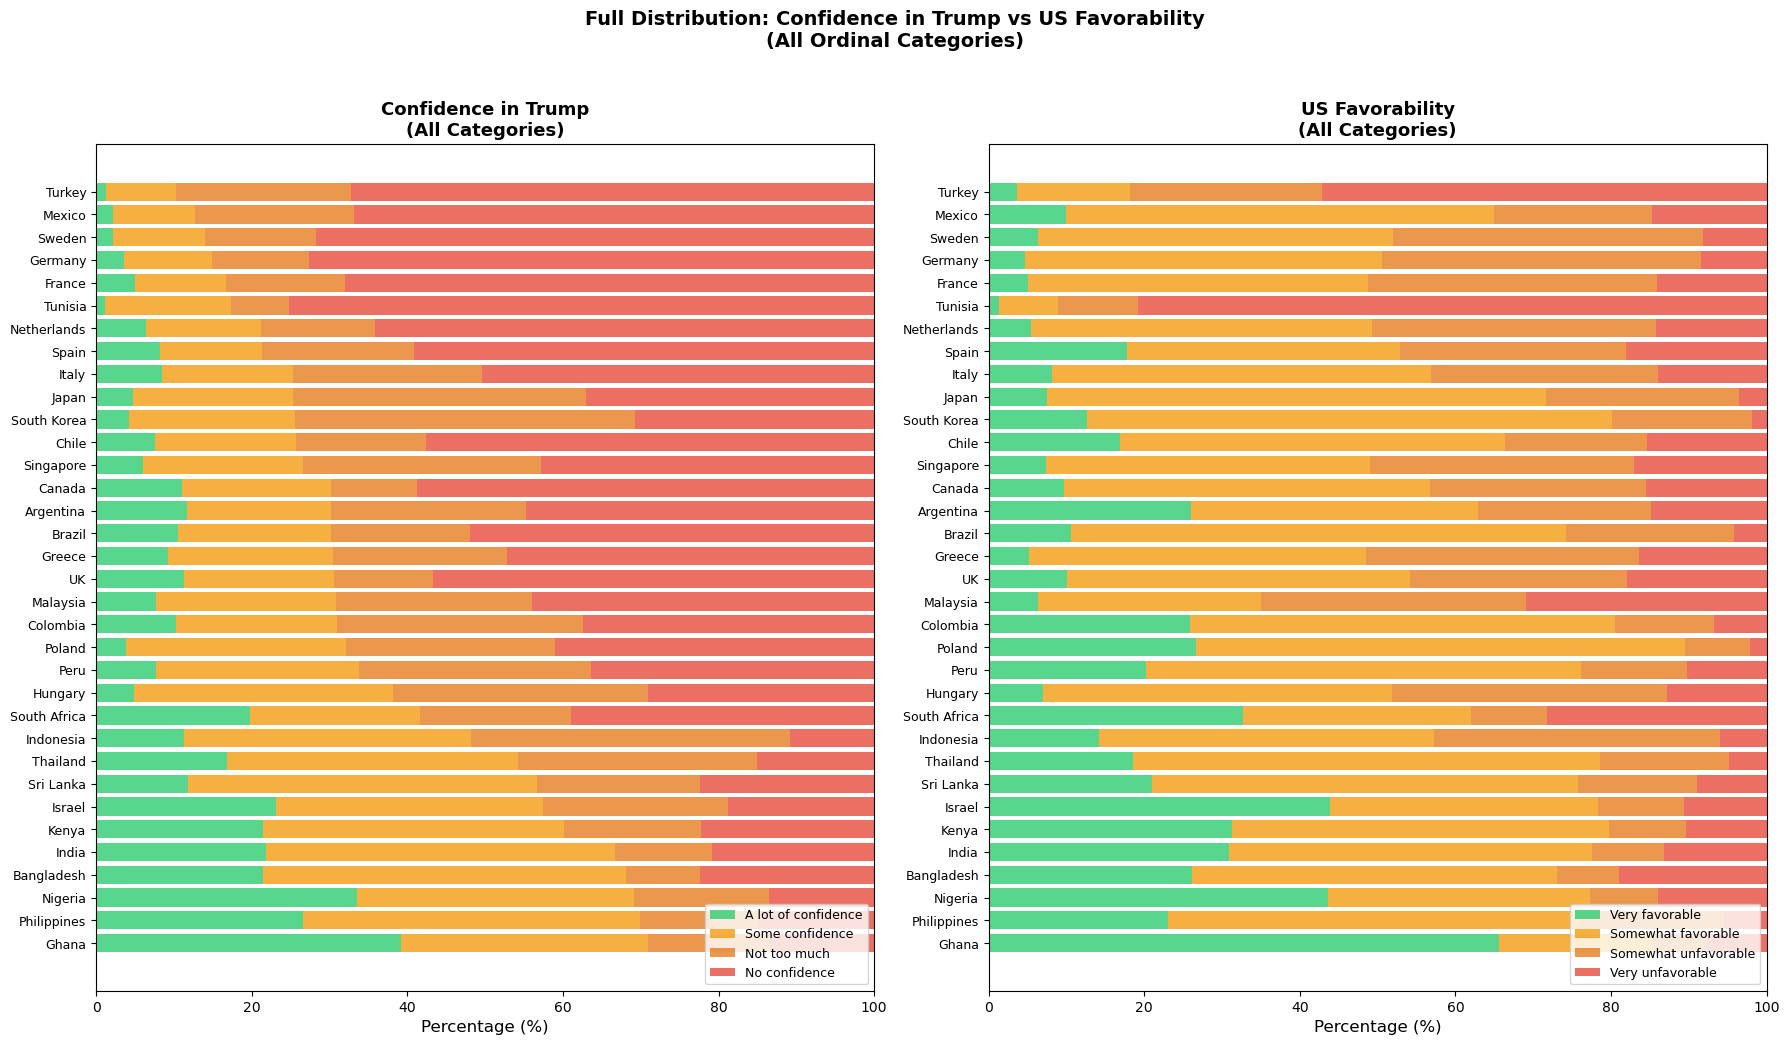

In [148]:
# Option 1: Stacked Bar Chart - All Ordinal Categories
# Showing full distribution of confid_trump vs fav_us

# Filter to valid responses
valid_data = pew[
    pew['confid_trump'].isin(['1', '2', '3', '4']) & 
    pew['fav_us'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'confid_trump', 'fav_us'])

# Calculate weighted proportions for ALL categories
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Trump confidence - all 4 categories
    trump_cats = {}
    for cat in ['1', '2', '3', '4']:
        cat_weight = country_data[country_data['confid_trump'] == cat]['weight'].sum()
        trump_cats[cat] = (cat_weight / total_weight) * 100
    
    # US favorability - all 4 categories
    fav_us_cats = {}
    for cat in ['1', '2', '3', '4']:
        cat_weight = country_data[country_data['fav_us'] == cat]['weight'].sum()
        fav_us_cats[cat] = (cat_weight / total_weight) * 100
    
    country_stats[country] = {
        'trump_1': trump_cats['1'],  # A lot of confidence
        'trump_2': trump_cats['2'],  # Some confidence
        'trump_3': trump_cats['3'],  # Not too much confidence
        'trump_4': trump_cats['4'],  # No confidence at all
        'fav_us_1': fav_us_cats['1'],  # Very favorable
        'fav_us_2': fav_us_cats['2'],  # Somewhat favorable
        'fav_us_3': fav_us_cats['3'],  # Somewhat unfavorable
        'fav_us_4': fav_us_cats['4'],  # Very unfavorable
    }

plot_df = pd.DataFrame(country_stats).T

# Create stacked bar chart for Trump confidence
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, max(10, len(plot_df) * 0.3)))

# Sort by total confidence (1+2)
plot_df['total_confident'] = plot_df['trump_1'] + plot_df['trump_2']
plot_df = plot_df.sort_values('total_confident', ascending=True)

y_pos = np.arange(len(plot_df))

# Stacked bar for Trump confidence
categories_trump = ['trump_1', 'trump_2', 'trump_3', 'trump_4']
labels_trump = ['A lot of confidence', 'Some confidence', 'Not too much', 'No confidence']
colors_trump = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']  # Green to red

bottom = np.zeros(len(plot_df))
for i, (cat, label, color) in enumerate(zip(categories_trump, labels_trump, colors_trump)):
    values = plot_df[cat].values
    ax1.barh(y_pos, values, left=bottom, label=label, color=color, alpha=0.8)
    bottom += values

ax1.set_yticks(y_pos)
ax1.set_yticklabels(plot_df.index, fontsize=9)
ax1.set_xlabel('Percentage (%)', fontsize=12)
ax1.set_title('Confidence in Trump\n(All Categories)', fontsize=13, fontweight='bold')
ax1.legend(loc='lower right', fontsize=9)
ax1.set_xlim(0, 100)
ax1.invert_yaxis()

# Stacked bar for US favorability
categories_us = ['fav_us_1', 'fav_us_2', 'fav_us_3', 'fav_us_4']
labels_us = ['Very favorable', 'Somewhat favorable', 'Somewhat unfavorable', 'Very unfavorable']
colors_us = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']  # Green to red

bottom = np.zeros(len(plot_df))
for i, (cat, label, color) in enumerate(zip(categories_us, labels_us, colors_us)):
    values = plot_df[cat].values
    ax2.barh(y_pos, values, left=bottom, label=label, color=color, alpha=0.8)
    bottom += values

ax2.set_yticks(y_pos)
ax2.set_yticklabels(plot_df.index, fontsize=9)
ax2.set_xlabel('Percentage (%)', fontsize=12)
ax2.set_title('US Favorability\n(All Categories)', fontsize=13, fontweight='bold')
ax2.legend(loc='lower right', fontsize=9)
ax2.set_xlim(0, 100)
ax2.invert_yaxis()

plt.suptitle('Full Distribution: Confidence in Trump vs US Favorability\n(All Ordinal Categories)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

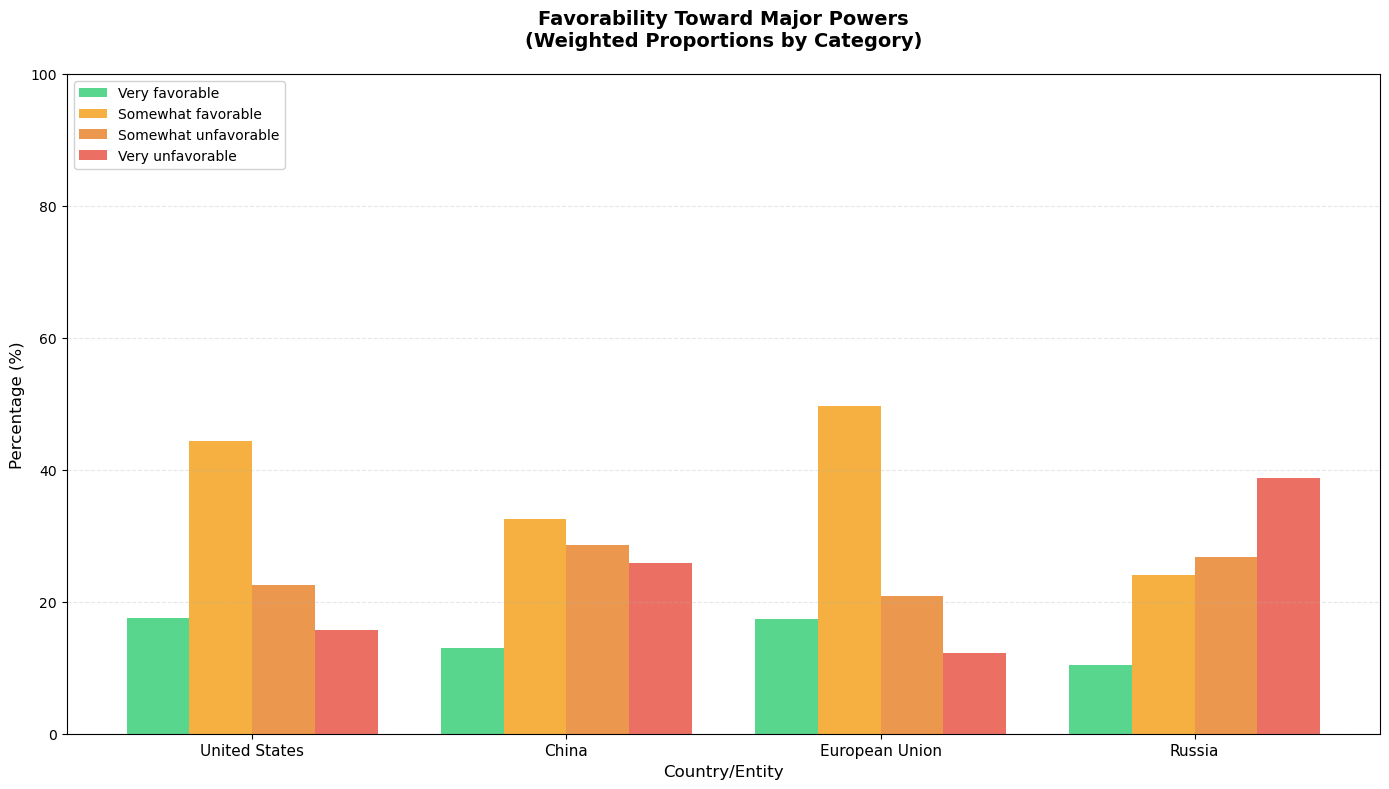

FAVORABILITY TOWARD MAJOR POWERS - SUMMARY STATISTICS

United States:
  Very favorable: 17.5%
  Somewhat favorable: 44.3%
  Somewhat unfavorable: 22.5%
  Very unfavorable: 15.7%
  Total Favorable (1+2): 61.8%
  Total Unfavorable (3+4): 38.2%

China:
  Very favorable: 13.0%
  Somewhat favorable: 32.5%
  Somewhat unfavorable: 28.6%
  Very unfavorable: 25.9%
  Total Favorable (1+2): 45.5%
  Total Unfavorable (3+4): 54.5%

European Union:
  Very favorable: 17.3%
  Somewhat favorable: 49.7%
  Somewhat unfavorable: 20.8%
  Very unfavorable: 12.2%
  Total Favorable (1+2): 67.0%
  Total Unfavorable (3+4): 33.0%

Russia:
  Very favorable: 10.4%
  Somewhat favorable: 24.1%
  Somewhat unfavorable: 26.7%
  Very unfavorable: 38.8%
  Total Favorable (1+2): 34.5%
  Total Unfavorable (3+4): 65.5%


In [63]:
# Favorability in Major Powers Comparison
# Showing all ordinal categories (1-4) for each entity
# Using weighted proportions (appropriate for ordinal variables)

# List of favorability variables to compare (major powers only)
favorability_vars = {
    'fav_us': 'United States',
    'fav_china': 'China',
    'fav_eu': 'European Union',
    'fav_russia': 'Russia'
}

# Category labels
category_labels = {
    '1': 'Very favorable',
    '2': 'Somewhat favorable',
    '3': 'Somewhat unfavorable',
    '4': 'Very unfavorable'
}

# Calculate weighted proportions for each entity
entity_stats = {}

for var_name, entity_name in favorability_vars.items():
    # Filter to valid responses (1-4)
    valid_data = pew[pew[var_name].isin(['1', '2', '3', '4'])].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', var_name])
    
    total_weight = valid_data['weight'].sum()
    
    # Calculate weighted proportions for each category
    proportions = {}
    for category in ['1', '2', '3', '4']:
        category_weight = valid_data[valid_data[var_name] == category]['weight'].sum()
        proportions[category] = (category_weight / total_weight) * 100
    
    entity_stats[entity_name] = proportions

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(entity_stats).T
plot_df.columns = [category_labels[col] for col in plot_df.columns]

# Reorder columns for logical flow
plot_df = plot_df[['Very favorable', 'Somewhat favorable', 
                   'Somewhat unfavorable', 'Very unfavorable']]

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(14, 8))

# Set up positions for bars
x = np.arange(len(plot_df.index))
width = 0.2  # Width of the bars

# Colors for each category
colors = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']  # Green, Orange, Light Red, Dark Red

# Create bars for each category
for i, (category, color) in enumerate(zip(plot_df.columns, colors)):
    values = plot_df[category].values
    offset = (i - 1.5) * width
    ax.bar(x + offset, values, width, label=category, color=color, alpha=0.8)

# Customize the plot
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_xlabel('Country/Entity', fontsize=12)
ax.set_title('Favorability Toward Major Powers\n(Weighted Proportions by Category)', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, fontsize=11)
ax.legend(loc='upper left', framealpha=0.9, fontsize=10)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

# Print summary statistics
print("="*80)
print("FAVORABILITY TOWARD MAJOR POWERS - SUMMARY STATISTICS")
print("="*80)

for entity in plot_df.index:
    print(f"\n{entity}:")
    for category in plot_df.columns:
        pct = plot_df.loc[entity, category]
        print(f"  {category}: {pct:.1f}%")
    
    # Calculate "favorable" (1+2) vs "unfavorable" (3+4)
    favorable = plot_df.loc[entity, 'Very favorable'] + plot_df.loc[entity, 'Somewhat favorable']
    unfavorable = plot_df.loc[entity, 'Somewhat unfavorable'] + plot_df.loc[entity, 'Very unfavorable']
    print(f"  Total Favorable (1+2): {favorable:.1f}%")
    print(f"  Total Unfavorable (3+4): {unfavorable:.1f}%")

# 4. Discussion

# 5. Limitations

# Bibliography

Packages used []